In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pickle
from itertools import product
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from adjustText import adjust_text

In [2]:
def load_pickle(path): 

    with open(path, "rb") as f: 
        return pickle.load(f)

In [3]:
REPO_DIR = Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking")
BASE = REPO_DIR / "model_outputs"
OUT_DIR = REPO_DIR / "benchmarking_results"
FIGURE_DIR = OUT_DIR / "figures"
EMB_DIR = REPO_DIR / "data" / "RNA_embeddings"

DATASETS = ["TCGA", "Hartwig", "CPTAC", "TARGET_AML"]
n_datasets = len(DATASETS)

FM_BULK = {"BulkRNABert", "BulkFormer", "COMPASS"}
FM_SC   = {"scGPT", "STATE", "CancerFoundation"}
FM_ALL  = FM_BULK | FM_SC

dataset_labels = {"TARGET_AML": "TARGET-AML"}

dataset_colors = {
    "TCGA":       "#4C72B0",
    "Hartwig":    "#DD8452",
    "CPTAC":      "#55A868",
    "TARGET_AML": "#C44E52",
}

In [4]:
def get_cancer_type_info_from_embeddings(dataset, cancer_types=None):
    suffix = "_cleaned" if dataset == "TCGA" else ""
    embeddings = load_pickle(EMB_DIR / f"{dataset}_processed{suffix}.pkl")
    
    cancer_type_value_counts = {}
    for pid in embeddings:
        cancer_type = embeddings[pid]["cancer_type"]
        cancer_type_value_counts[cancer_type] = cancer_type_value_counts.get(cancer_type, 0) + 1
    total = sum(cancer_type_value_counts.values())
    
    if cancer_types is None:
        return cancer_type_value_counts
    
    fraction = 0
    for ct in cancer_types:
        fraction += cancer_type_value_counts.get(ct, 0) / total
    return fraction

In [5]:
def select_best_arch_loss_by_val(dataset):
    """
    For each (RNA_key, nHVGs): pick the (arch, loss) with highest mean val C-index
    across all seeds and splits. Returns DataFrame with [RNA_key, nHVGs, arch, loss].
    """
    val_df = pd.read_csv(BASE / dataset / "survival" / "PFS" / "val_metrics.csv")
    val_df["nHVGs"] = val_df["nHVGs"].fillna("None").astype(str)

    val_mean = (
        val_df.dropna(subset=["val_cindex"])
        .groupby(["RNA_key", "nHVGs", "arch", "loss"])["val_cindex"]
        .mean()
        .reset_index()
    )
    best = (
        val_mean.sort_values("val_cindex", ascending=False)
        .groupby(["RNA_key", "nHVGs"], as_index=False)
        .head(1)[["RNA_key", "nHVGs", "arch", "loss"]]
    )
    return best

In [6]:
group_cols = ["dataset", "task", "arch", "loss", "RNA_key", "nHVGs"]

for dataset in DATASETS:
    csv = BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if not csv.exists():
        print(f"Missing: {csv}")
        continue

    df = pd.read_csv(csv)
    df["nHVGs"] = df["nHVGs"].fillna("None")
    print(f"\n{dataset}: {len(df)} rows, {df['overall'].isna().sum()} NaN overall")
    # print NaN rows
    nan_rows = df[df["overall"].isna()]
    print(nan_rows[group_cols + ["overall"]])
    
    error_rows = df[df["error"].notna()]
    print(f"{len(error_rows)} rows with errors:")

    exclude = set(group_cols + ["seed", "split", "run_dir", "error"])
    metric_cols = [c for c in df.columns if c not in exclude]

    agg_dict = {f"{col}_mean": (col, "mean") for col in metric_cols}
    agg_dict.update({f"{col}_std": (col, "std") for col in metric_cols})
    agg_dict["n_runs"] = ("overall", "count")

    df_agg = (
        df.dropna(subset=["overall"])
        .groupby(group_cols)
        .agg(**agg_dict)
        .reset_index()
        .sort_values("overall_mean", ascending=False)
    )

    out_path = OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg.csv"
    df_agg.to_csv(out_path, index=False)
    print(f"Wrote {len(df_agg)} rows to {out_path}")


TCGA: 1000 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 100 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/TCGA_survival_PFS_agg.csv

Hartwig: 1000 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 100 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/Hartwig_survival_PFS_agg.csv

CPTAC: 1000 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 100 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/CPTAC_survival_PFS_agg.csv

TARGET_AML: 1000 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 100 rows to /data/rbg/users/ashyamal/RNA-FM-b

In [7]:
def build_filtered_agg(dataset):
    """Merge agg CSV with val-selected (arch, loss). Run once; saves filtered CSV to disk."""
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg.csv")
    df["nHVGs"] = df["nHVGs"].fillna("None").astype(str)
    df = df.merge(select_best_arch_loss_by_val(dataset), on=["RNA_key", "nHVGs", "arch", "loss"])
    df.to_csv(OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg_filtered.csv", index=False)
    return df

for d in DATASETS:
    build_filtered_agg(d)

In [8]:
def categorize_row(rna_key: str, nHVGs) -> str:
    rk = str(rna_key)
    if rk in FM_BULK:
        return "FM_BULK"
    if rk in FM_SC:
        return "FM_SC"
    if rk.startswith("max_") or rk.startswith("ssGSEA_"):
        return "GS"
    if rk in ("PCA_50", "PCA_100"):
        return "PCA"
    if rk == "RNA_seq":
        if str(nHVGs) in ("None", "nan", ""):
            return "Raw_expression"
        return "HVG"
    return "Other"

def summarize_best_per_category(df: pd.DataFrame, verbose: bool = False) -> pd.DataFrame:
    df = df.copy()
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    df["overall_std"]  = pd.to_numeric(df["overall_std"],  errors="coerce")
    df["nHVGs"] = df["nHVGs"].fillna("None").astype(str)
    df["category"] = df.apply(lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1)

    if verbose:
        df["category"] = df.apply(
            lambda r: r["RNA_key"] if r["category"] in ("FM_BULK", "FM_SC") else r["category"], axis=1
        )
        allowed = FM_ALL | {"GS", "PCA", "Raw_expression", "HVG"}
        order = ["BulkRNABert", "BulkFormer", "COMPASS", "scGPT", "STATE", "CancerFoundation",
                 "GS", "HVG", "PCA", "Raw_expression"]
    else:
        allowed = {"FM_BULK", "FM_SC", "GS", "PCA", "Raw_expression", "HVG"}
        order = ["FM_BULK", "FM_SC", "GS", "HVG", "PCA", "Raw_expression"]

    df = df[df["category"].isin(allowed)].dropna(subset=["overall_mean"])

    df_sorted = df.sort_values(
        by=["category", "overall_mean", "overall_std", "arch", "loss", "RNA_key", "nHVGs"],
        ascending=[True, False, True, True, True, True, True],
        kind="mergesort",
    )
    best = df_sorted.groupby("category", as_index=False).head(1)

    out = best[["category", "overall_mean", "overall_std", "arch", "loss", "RNA_key", "nHVGs"]].rename(
        columns={"overall_mean": "best_cindex_mean", "overall_std": "best_cindex_std"}
    )
    out["category"] = pd.Categorical(out["category"], categories=order, ordered=True)
    return out.sort_values("category").reset_index(drop=True)

def run_agg(verbose=True):
    for d in DATASETS:
        df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        summary = summarize_best_per_category(df, verbose=verbose)
        print(f"\n{'='*80}\nDataset: {d}\n{'='*80}")
        print(summary.to_string(index=False))

run_agg()


Dataset: TCGA
        category  best_cindex_mean  best_cindex_std        arch   loss          RNA_key   nHVGs
     BulkRNABert          0.723639         0.009901 ResidualMLP    Cox      BulkRNABert    None
      BulkFormer          0.716180         0.014934 ResidualMLP CIndex       BulkFormer    None
         COMPASS          0.710862         0.013073 ResidualMLP    Cox          COMPASS    None
           scGPT          0.683241         0.007495      Linear    Cox            scGPT    None
           STATE          0.728183         0.012668 ResidualMLP    Cox            STATE    None
CancerFoundation          0.691970         0.007966      Linear    Cox CancerFoundation    None
              GS          0.737289         0.012883 ResidualMLP CIndex     max_combined    None
             HVG          0.741761         0.010647 ResidualMLP CIndex          RNA_seq 10000.0
             PCA          0.734943         0.009970 ResidualMLP CIndex          PCA_100    None
  Raw_expression         

In [9]:
run_agg(verbose=False)


Dataset: TCGA
      category  best_cindex_mean  best_cindex_std        arch   loss      RNA_key   nHVGs
       FM_BULK          0.723639         0.009901 ResidualMLP    Cox  BulkRNABert    None
         FM_SC          0.728183         0.012668 ResidualMLP    Cox        STATE    None
            GS          0.737289         0.012883 ResidualMLP CIndex max_combined    None
           HVG          0.741761         0.010647 ResidualMLP CIndex      RNA_seq 10000.0
           PCA          0.734943         0.009970 ResidualMLP CIndex      PCA_100    None
Raw_expression          0.740869         0.010690      Linear CIndex      RNA_seq    None

Dataset: Hartwig
      category  best_cindex_mean  best_cindex_std        arch   loss      RNA_key  nHVGs
       FM_BULK          0.592474         0.009985      Linear CIndex  BulkRNABert   None
         FM_SC          0.599900         0.020214      Linear    Cox        STATE   None
            GS          0.610891         0.021936 ResidualMLP CIndex m

### Per cancer type results

In [10]:
def load_all_agg(verbose: bool = False):
    dfs = []
    for d in DATASETS:
        x = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        x["dataset"] = d
        x["category"] = x.apply(lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1)

        if verbose:
            x["category"] = x.apply(
                lambda r: r["RNA_key"] if r["category"] in ("FM_BULK","FM_SC") else r["category"], axis=1
            )
            allowed = FM_ALL | {"GS","PCA","Raw_expression","HVG"}
            order = ["BulkRNABert","BulkFormer","COMPASS","scGPT","STATE","CancerFoundation",
                     "GS","HVG","PCA","Raw_expression"]
        else:
            allowed = {"FM_BULK","FM_SC","GS","PCA","Raw_expression","HVG"}
            order = ["FM_BULK","FM_SC","GS","HVG","PCA","Raw_expression"]

        x = x[x["category"].isin(allowed)].copy()
        x["category"] = pd.Categorical(x["category"], categories=order, ordered=True)
        dfs.append(x)

    df_all = pd.concat(dfs, ignore_index=True)
    return df_all

df_all = load_all_agg(verbose=False)
df_all.shape, df_all["dataset"].value_counts()

((100, 206),
 dataset
 TCGA          25
 Hartwig       25
 CPTAC         25
 TARGET_AML    25
 Name: count, dtype: int64)

In [11]:
df_all.head()

,dataset,task,arch,loss,RNA_key,nHVGs,overall_mean,ACC_mean,BLCA_mean,BRCA_mean,...,"Larynx, NOS_std","Lip, NOS_std","Lung, NOS_std","Oropharynx, NOS_std","Overlapping lesion of lip, oral cavity and pharynx_std","Pancreas, NOS_std","Tongue, NOS_std","Uterus, NOS_std",AML_mean,AML_std
0,TCGA,survival,ResidualMLP,CIndex,RNA_seq,10000.0,0.741761,0.817030,0.625028,0.663260,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TCGA,survival,ResidualMLP,CIndex,RNA_seq,5000.0,0.741386,0.814788,0.642216,0.660732,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TCGA,survival,Linear,CIndex,RNA_seq,NaN,0.740869,0.823811,0.637976,0.673765,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TCGA,survival,ResidualMLP,CIndex,RNA_seq,1250.0,0.737606,0.783700,0.625933,0.670759,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TCGA,survival,ResidualMLP,CIndex,max_combined,NaN,0.737289,0.787143,0.615039,0.656203,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Infer cancer-type metric bases from "*_mean" columns (excluding overall)
mean_cols = [c for c in df_all.columns if c.endswith("_mean")]
cancer_bases = sorted({c[:-5] for c in mean_cols if c not in ("overall_mean",)})

print(f"Found {len(cancer_bases)} cancer types:")
print(f"Example cancer types: {cancer_bases[:10]}")

Found 98 cancer types:
Example cancer types: ['ACC', 'AML', 'Adenocarcinoma', 'Adenocarcinoma, intestinal type', 'Alveolar soft part sarcoma', 'Angiosarcoma', 'BLCA', 'BRCA', 'Basal cell carcinoma', 'Base of tongue, NOS']


In [13]:
rows = []
id_cols = ["dataset","task","arch","loss","RNA_key","nHVGs","category"]

for base in cancer_bases:
    mcol, scol = f"{base}_mean", f"{base}_std"
    if mcol not in df_all.columns: 
        continue

    tmp = df_all[id_cols + [mcol] + ([scol] if scol in df_all.columns else [])].copy()
    tmp = tmp.rename(columns={mcol: "cindex_mean", scol: "cindex_std"} if scol in tmp.columns else {mcol:"cindex_mean"})
    tmp["cancer_type"] = base

    tmp["cindex_mean"] = pd.to_numeric(tmp["cindex_mean"], errors="coerce")
    if "cindex_std" in tmp.columns:
        tmp["cindex_std"] = pd.to_numeric(tmp["cindex_std"], errors="coerce")
    else:
        tmp["cindex_std"] = np.nan

    # Choose best within (dataset, cancer_type, category); tie-break by lower std then deterministic keys
    tmp = tmp.dropna(subset=["cindex_mean"]).sort_values(
        by=["dataset","cancer_type","category","cindex_mean","cindex_std","arch","loss","RNA_key","nHVGs"],
        ascending=[True, True, True, False, True, True, True, True, True],
        kind="mergesort"
    )
    best = tmp.groupby(["dataset","cancer_type","category"], as_index=False, observed=True).head(1)

    rows.append(best)

best_long = pd.concat(rows, ignore_index=True).sort_values(["dataset","cancer_type","category"])
best_long.reset_index(drop=True, inplace=True)

best_long.head()

,dataset,task,arch,loss,RNA_key,nHVGs,category,cindex_mean,cindex_std,cancer_type
0,CPTAC,survival,Linear,Cox,BulkFormer,NaN,FM_BULK,0.561897,0.025537,"Brain, NOS"
1,CPTAC,survival,Linear,Cox,scGPT,NaN,FM_SC,0.574103,0.070898,"Brain, NOS"
2,CPTAC,survival,ResidualMLP,Cox,max_AURORA,NaN,GS,0.596562,0.049949,"Brain, NOS"
3,CPTAC,survival,ResidualMLP,CIndex,RNA_seq,10000.0,HVG,0.592239,0.064318,"Brain, NOS"
4,CPTAC,survival,Linear,Cox,PCA_50,NaN,PCA,0.562084,0.041393,"Brain, NOS"


In [14]:
def heatmap_for_dataset(best_long: pd.DataFrame, dataset: str):
    x = best_long[best_long["dataset"] == dataset].copy()
    mat = x.pivot_table(index="cancer_type", columns="category", values="cindex_mean", aggfunc="first", observed=True)
    return x, mat

heatmaps = {}
for d in best_long["dataset"].unique():
    # Only generate heatmaps for TCGA and CPTAC
    # Hartwig has many cancer types (57)
    # TARGET_AML has only one cancer type (AML)
    if d in ["TCGA", "CPTAC"]:
        _, mat = heatmap_for_dataset(best_long, d)
        heatmaps[d] = mat
        print(d, mat.shape)

CPTAC (9, 6)
TCGA (33, 6)


In [15]:
def plot_heatmap(mat: pd.DataFrame, dataset: str):
    
    mat = mat.dropna(how="all")

    cell_size = 1
    fig_w = cell_size * mat.shape[1]
    fig_h = cell_size * mat.shape[0]

    # Build colormap
    colors = plt.cm.viridis(np.linspace(0.0, 0.75, 256))  # cut off the yellow end
    cmap = mcolors.LinearSegmentedColormap.from_list('viridis_dark', colors)
    
    # Build labels: "CancerType\n(N=123)"
    ct_counts = get_cancer_type_info_from_embeddings(dataset)

    # Sort rows by descending patient count
    sorted_index = sorted(mat.index, key=lambda ct: ct_counts.get(ct, 0), reverse=True)
    mat = mat.loc[sorted_index]
    
    yticklabels = [f"{ct.split(', NOS')[0]}\n(N={ct_counts.get(ct, 0)})" for ct in mat.index]
    
    plt.figure(figsize=(fig_w, fig_h))
    plt.imshow(mat.values, aspect="equal", cmap=cmap, vmin=0.5, vmax=0.89)

    plt.title(f"{dataset}: Best model per category")
    plt.colorbar(label="Best mean C-index")
    
    plt.xticks(range(mat.shape[1]), mat.columns.astype(str), rotation=45, ha="right")
    plt.yticks(range(mat.shape[0]), yticklabels)
    
    # Plot values on cells
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.iat[i, j]
            if pd.notna(val):
                plt.text(j, i, f"{val:.3f}", ha="center", va="center", color="white", fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{dataset}_per_cancer_type_heatmap.png", dpi=300)
    plt.show()

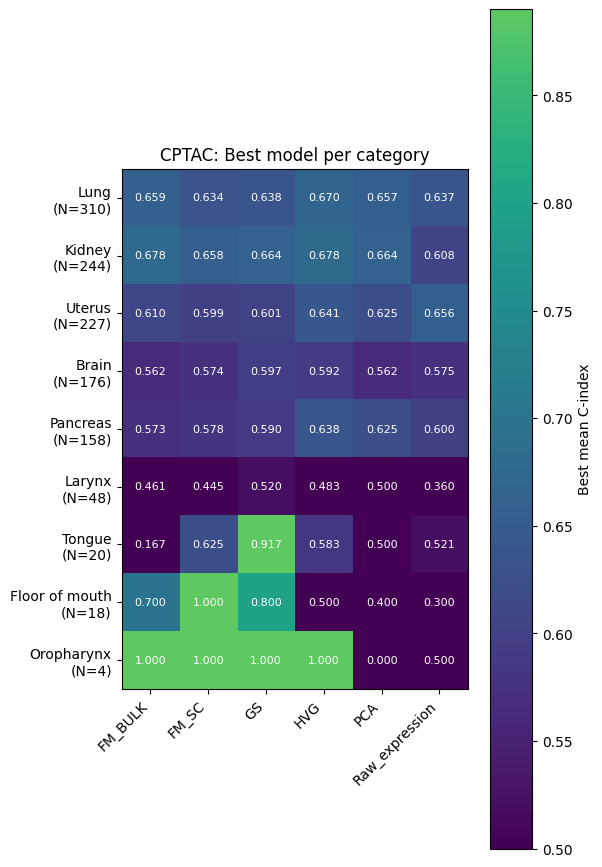

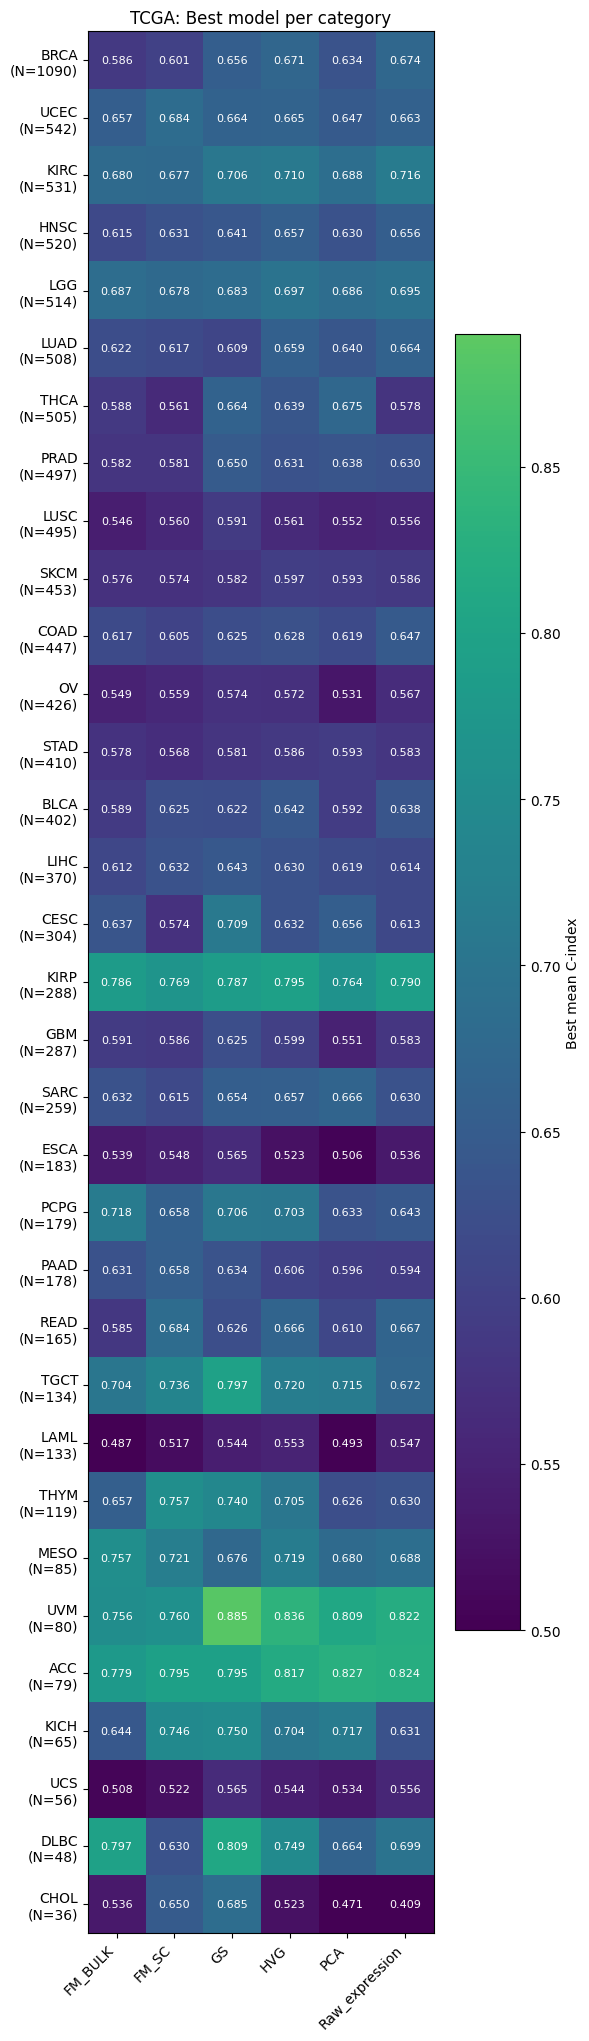

In [16]:
for d, mat in heatmaps.items():
    plot_heatmap(mat, d)

In [17]:
winners = (
    best_long.assign(winner=lambda x: x["RNA_key"].astype(str) + " | " + x["arch"].astype(str) + " | " + x["loss"].astype(str) + " | nHVGs=" + x["nHVGs"].astype(str))
    .pivot_table(index=["dataset","cancer_type"], columns="category", values="winner", aggfunc="first", observed=True)
)

winners

category                                                            FM_BULK  \
dataset cancer_type                                                           
CPTAC   Brain, NOS                    BulkFormer | Linear | Cox | nHVGs=nan   
        Floor of mouth, NOS           BulkFormer | Linear | Cox | nHVGs=nan   
        Kidney, NOS              COMPASS | ResidualMLP | CIndex | nHVGs=nan   
        Larynx, NOS          BulkRNABert | ResidualMLP | CIndex | nHVGs=nan   
        Lung, NOS            BulkRNABert | ResidualMLP | CIndex | nHVGs=nan   
...                                                                     ...   
TCGA    THCA                  BulkFormer | ResidualMLP | CIndex | nHVGs=nan   
        THYM                        COMPASS | ResidualMLP | Cox | nHVGs=nan   
        UCEC                    BulkRNABert | ResidualMLP | Cox | nHVGs=nan   
        UCS                   BulkFormer | ResidualMLP | CIndex | nHVGs=nan   
        UVM                   BulkFormer | ResidualMLP | CIndex | nHVGs=nan   

category                                                              FM_SC  \
dataset cancer_type                                                           
CPTAC   Brain, NOS                         scGPT | Linear | Cox | nHVGs=nan   
        Floor of mouth, NOS  CancerFoundation | Linear | CIndex | nHVGs=nan   
        Kidney, NOS                        STATE | Linear | Cox | nHVGs=nan   
        Larynx, NOS                        scGPT | Linear | Cox | nHVGs=nan   
        Lung, NOS                          STATE | Linear | Cox | nHVGs=nan   
...                                                                     ...   
TCGA    THCA                          STATE | ResidualMLP | Cox | nHVGs=nan   
        THYM                          STATE | ResidualMLP | Cox | nHVGs=nan   
        UCEC                          STATE | ResidualMLP | Cox | nHVGs=nan   
        UCS                                scGPT | Linear | Cox | nHVGs=nan   
        UVM                           STATE | ResidualMLP | Cox | nHVGs=nan   

category                                                                   GS  \
dataset cancer_type                                                             
CPTAC   Brain, NOS                 max_AURORA | ResidualMLP | Cox | nHVGs=nan   
        Floor of mouth, NOS     ssGSEA_hallmark | Linear | CIndex | nHVGs=nan   
        Kidney, NOS             ssGSEA_immuno | ResidualMLP | Cox | nHVGs=nan   
        Larynx, NOS             max_immuno | ResidualMLP | CIndex | nHVGs=nan   
        Lung, NOS                max_combined | ResidualMLP | Cox | nHVGs=nan   
...                                                                       ...   
TCGA    THCA                  max_combined | ResidualMLP | CIndex | nHVGs=nan   
        THYM                     max_hallmark | ResidualMLP | Cox | nHVGs=nan   
        UCEC                    max_AURORA | ResidualMLP | CIndex | nHVGs=nan   
        UCS                  ssGSEA_AURORA | ResidualMLP | CIndex | nHVGs=nan   
        UVM                   max_combined | ResidualMLP | CIndex | nHVGs=nan   

category                                                                HVG  \
dataset cancer_type                                                           
CPTAC   Brain, NOS           RNA_seq | ResidualMLP | CIndex | nHVGs=10000.0   
        Floor of mouth, NOS   RNA_seq | ResidualMLP | CIndex | nHVGs=5000.0   
        Kidney, NOS               RNA_seq | ResidualMLP | Cox | nHVGs=132.0   
        Larynx, NOS                RNA_seq | ResidualMLP | Cox | nHVGs=18.0   
        Lung, NOS                 RNA_seq | ResidualMLP | Cox | nHVGs=500.0   
...                                                                     ...   
TCGA    THCA                  RNA_seq | ResidualMLP | CIndex | nHVGs=5000.0   
        THYM                      RNA_seq | ResidualMLP | Cox | nHVGs=132.0   
        UCEC                 RNA_seq | ResidualMLP | CIndex | nHVGs=10000.0   
        UCS          

In [18]:
fm_cats = {"FM_BULK", "FM_SC"}
baseline_cats = {"GS", "HVG", "PCA", "Raw_expression"}

rows = []

for (dataset, cancer), g in best_long.groupby(["dataset", "cancer_type"]):

    fm_best = g[g["category"].isin(fm_cats)]["cindex_mean"].max()
    base_best = g[g["category"].isin(baseline_cats)]["cindex_mean"].max()

    rows.append({
        "dataset": dataset,
        "cancer_type": cancer,
        "fm_best": fm_best,
        "baseline_best": base_best,
        "fm_beats_baseline": fm_best > base_best
    })

fm_vs_baseline = pd.DataFrame(rows)
fm_vs_baseline.head()

,dataset,cancer_type,fm_best,baseline_best,fm_beats_baseline
0,CPTAC,"Brain, NOS",0.574103,0.596562,False
1,CPTAC,"Floor of mouth, NOS",1.000000,0.800000,True
2,CPTAC,"Kidney, NOS",0.677660,0.678408,False
3,CPTAC,"Larynx, NOS",0.460916,0.520073,False
4,CPTAC,"Lung, NOS",0.658630,0.669711,False


In [19]:
summary = (
    fm_vs_baseline
    .groupby("dataset")
    .agg(
        n_cancer_types=("cancer_type", "count"),
        n_fm_wins=("fm_beats_baseline", "sum"),
        cancer_types_where_fm_wins=("cancer_type", lambda x: list(
            x[fm_vs_baseline.loc[x.index, "fm_beats_baseline"]]
        ))
    )
)

summary["fraction of patients in winning cancer types"] = summary.apply(
    lambda row: get_cancer_type_info_from_embeddings(row.name, row["cancer_types_where_fm_wins"]),
    axis=1
)

summary

,n_cancer_types,n_fm_wins,cancer_types_where_fm_wins,fraction of patients in winning cancer types
dataset,,,,
CPTAC,9,1,"[Floor of mouth, NOS]",0.014730
Hartwig,24,5,"[Gastrointestinal stromal tumor (GIST), Hepato...",0.066756
TARGET_AML,1,0,[],0.000000
TCGA,33,6,"[MESO, PAAD, PCPG, READ, THYM, UCEC]",0.122064


In [20]:
summary.to_csv(OUT_DIR / "transcriptomic" / "fm_vs_baseline_cancer_type_summary.csv")

#### TCGA

/tmp/ipykernel_752538/2158331973.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.loc[g["cindex_mean"].idxmax(), "category"])


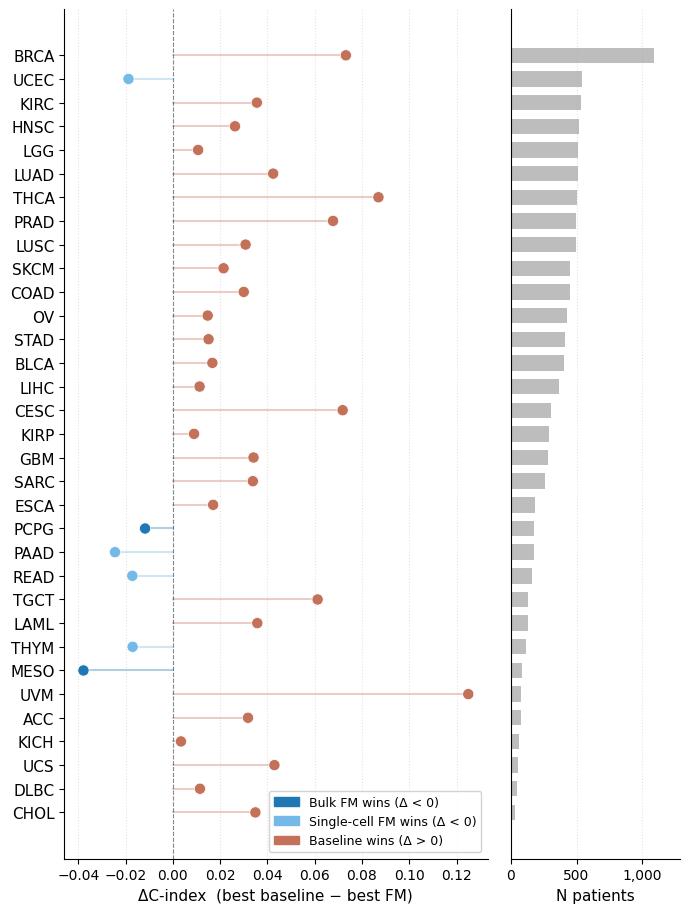

In [22]:
# ── TCGA ΔC-index dot plot (best baseline − best FM) ──────────────────────────
MIN_N = 0  # raise to filter out low-N cancer types

FM_CATS       = {"FM_BULK", "FM_SC"}
BASELINE_CATS = {"GS", "HVG", "PCA", "Raw_expression"}

tcga = best_long[best_long["dataset"] == "TCGA"].copy()

best_fm   = (tcga[tcga["category"].isin(FM_CATS)]
             .groupby("cancer_type")["cindex_mean"].max()
             .rename("best_fm"))
best_base = (tcga[tcga["category"].isin(BASELINE_CATS)]
             .groupby("cancer_type")["cindex_mean"].max()
             .rename("best_baseline"))

delta = pd.concat([best_fm, best_base], axis=1).dropna()
delta["delta"] = delta["best_baseline"] - delta["best_fm"]

ct_counts   = get_cancer_type_info_from_embeddings("TCGA")
delta["N"]  = delta.index.map(lambda ct: ct_counts.get(ct, 0))
delta       = delta[delta["N"] >= MIN_N].sort_values("N", ascending=True)  # ascending → top = most patients

# ── colours ───────────────────────────────────────────────────────────────────
# after computing delta, find which FM category wins per cancer type
winning_fm = (tcga[tcga["category"].isin(FM_CATS)]
              .groupby("cancer_type")
              .apply(lambda g: g.loc[g["cindex_mean"].idxmax(), "category"])
              .rename("winning_fm"))
delta = delta.join(winning_fm)

FM_BULK_COL = '#1F78B4'   # strong cobalt blue — Bulk FMs
FM_SC_COL   = '#74B9E7'   # pale steel blue — Single-cell FMs
BASE_COL = '#C4715A'   # muted terracotta — Baselines

def row_color(r):
    if r["delta"] >= 0:
        return BASE_COL
    return FM_BULK_COL if r["winning_fm"] == "FM_BULK" else FM_SC_COL

colors = [row_color(r) for _, r in delta.iterrows()]

y_pos  = np.arange(len(delta))

# ── figure ────────────────────────────────────────────────────────────────────
fig, (ax, ax_n) = plt.subplots(
    1, 2,
    figsize=(7, max(5, 0.28 * len(delta))),   # was 10 → try 6–7
    gridspec_kw={"width_ratios": [2.5, 1]},   # was [3, 1] — slightly less space to dot panel
    sharey=True,
)

# lollipop stems
for y, d, c in zip(y_pos, delta["delta"], colors):
    ax.plot([0, d], [y, y], color=c, alpha=0.35, lw=1.5, solid_capstyle="round")

# dots
ax.scatter(delta["delta"], y_pos, color=colors, s=65, zorder=3,
           edgecolors="white", linewidths=0.5)

ax.axvline(0, color="black", lw=0.8, ls="--", alpha=0.45)
ax.set_yticks(y_pos)
ax.set_yticklabels(
    [ct.split(", NOS")[0] for ct in delta.index],
    fontsize=11,
)
ax.set_xlabel("ΔC-index  (best baseline − best FM)", fontsize=11)
#ax.set_title("TCGA: per-cancer-type ΔC-index", fontsize=11, fontweight="bold")
ax.grid(axis="x", ls=":", alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)

legend_handles = [
    mpatches.Patch(color=FM_BULK_COL, label="Bulk FM wins (Δ < 0)"),
    mpatches.Patch(color=FM_SC_COL,   label="Single-cell FM wins (Δ < 0)"),
    mpatches.Patch(color=BASE_COL,    label="Baseline wins (Δ > 0)"),
]
ax.legend(handles=legend_handles, fontsize=9, framealpha=0.85, loc="lower right")

# ── patient count bar panel ───────────────────────────────────────────────────
ax_n.barh(y_pos, delta["N"], color="#888888", alpha=0.55, height=0.65)
ax_n.set_xlabel("N patients", fontsize=11)
ax_n.set_xlim(0, delta["N"].max() * 1.18)
ax_n.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax_n.tick_params(axis="y", length=0)
ax_n.grid(axis="x", ls=":", alpha=0.35)
ax_n.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "TCGA_delta_cindex_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()


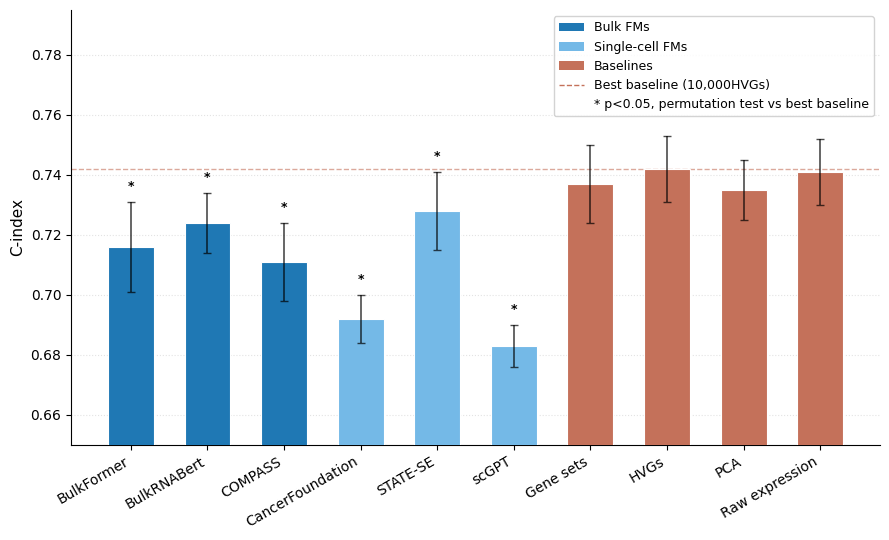

In [ ]:
from matplotlib.lines import Line2D

BULK_COL = '#1F78B4'   # strong cobalt blue — Bulk FMs
SC_COL   = '#74B9E7'   # pale steel blue — Single-cell FMs
BASE_COL = '#C4715A'   # muted terracotta — Baselines
labels = ['BulkFormer', 'BulkRNABert', 'COMPASS',
          'CancerFoundation', 'STATE-SE', 'scGPT',
          'Gene sets', 'HVGs', 'PCA', 'Raw expression']
means  = [0.716, 0.724, 0.711, 0.692, 0.728, 0.683, 0.737, 0.742, 0.735, 0.741]
errors = [0.015, 0.010, 0.013, 0.008, 0.013, 0.007, 0.013, 0.011, 0.010, 0.011]
colors = [BULK_COL]*3 + [SC_COL]*3 + [BASE_COL]*4

# display label → RNA_key used in df_perm
fm_key_map = {
    'BulkFormer': 'BulkFormer', 'BulkRNABert': 'BulkRNABert', 'COMPASS': 'COMPASS',
    'CancerFoundation': 'CancerFoundation', 'STATE-SE': 'STATE', 'scGPT': 'scGPT',
}

# p-values vs best baseline (HVGs 10k) for TCGA
perm = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
perm["baseline_nHVGs"] = perm["baseline_nHVGs"].fillna("None").astype(str)
ref_pvals = (
    perm[(perm["dataset"] == "TCGA") &
         (perm["baseline"] == "RNA_seq") &
         (perm["baseline_nHVGs"] == "10000.0")]
    .set_index("fm")["p_value"]
)

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

# ── figure ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(labels))

ax.bar(x, means, color=colors, width=0.6, edgecolor='white', linewidth=0.8,
       yerr=errors, capsize=3, error_kw={'elinewidth': 1.2, 'alpha': 0.7}, zorder=3)

ax.axhline(y=0.742, color=BASE_COL, linestyle='--', linewidth=1, alpha=0.6, zorder=2)
ax.set_ylim(0.65, 0.795)

# significance stars above each FM bar (vs HVGs 10k)
for i, label in enumerate(labels[:6]):
    rna_key = fm_key_map[label]
    if rna_key in ref_pvals.index:
        stars = pval_stars(ref_pvals[rna_key])
        sig = stars != 'ns'
        ax.text(i, means[i] + errors[i] + 0.003, stars,
                ha='center', va='bottom', fontsize=9,
                color='black' if sig else '#aaaaaa',
                fontweight='bold' if sig else 'normal')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=10)
ax.set_ylabel('C-index', fontsize=11)
#ax.set_title('TCGA Progression-Free Survival Prediction', fontsize=12, fontweight='bold')
ax.grid(axis='y', ls=':', alpha=0.35, zorder=0)
ax.spines[['top', 'right']].set_visible(False)

legend_elements = [
    mpatches.Patch(facecolor=BULK_COL, label='Bulk FMs'),
    mpatches.Patch(facecolor=SC_COL,   label='Single-cell FMs'),
    mpatches.Patch(facecolor=BASE_COL, label='Baselines'),
    Line2D([0], [0], color=BASE_COL, ls='--', lw=1, label='Best baseline (10,000HVGs)'),
    Line2D([0], [0], color='none', label='* p<0.05, permutation test vs best baseline'),
]
ax.legend(handles=legend_elements, fontsize=9, framealpha=0.85, loc='upper right')

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'tcga_results.png', dpi=300, bbox_inches='tight')
plt.show()

### Statistical Testing

In [ ]:
def sign_flip_permutation_test(diffs):
    """One-sided: P(mean >= observed) under sign flips. diffs = baseline - FM."""
    n = len(diffs)
    observed = np.mean(diffs)
    count = 0
    for signs in product([1, -1], repeat=n):
        if np.mean([s * d for s, d in zip(signs, diffs)]) >= observed:
            count += 1
    return count / (2 ** n)

def get_best_config_per_split(dataset):
    best_configs = pd.read_csv(
        OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg_filtered.csv"
    )[["RNA_key", "nHVGs", "arch", "loss"]].drop_duplicates()
    best_configs["nHVGs"] = best_configs["nHVGs"].fillna("None").astype(str)

    raw = pd.read_csv(BASE / dataset / "survival" / "PFS" / "all_metrics.csv")
    raw["nHVGs"] = raw["nHVGs"].fillna("None").astype(str)

    per_split = (
        raw.merge(best_configs, on=["RNA_key", "nHVGs", "arch", "loss"])
        .dropna(subset=["overall"])
        .groupby(["RNA_key", "nHVGs", "split"])["overall"]
        .mean()
        .reset_index()
    )
    per_split["category"] = per_split.apply(
        lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1
    )
    return per_split

def run_permutation_tests(verbose=True):
    
    baselines = {"GS", "HVG", "PCA", "Raw_expression"}
    fms = FM_ALL

    results = []

    for d in DATASETS:
        per_split = get_best_config_per_split(d)

        df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        summary = summarize_best_per_category(df_agg, verbose=True)

        for _, base_row in summary[summary["category"].isin(baselines)].iterrows():
            base_splits = per_split[
                (per_split["RNA_key"] == base_row["RNA_key"]) &
                (per_split["nHVGs"] == str(base_row["nHVGs"]))
            ].sort_values("split")["overall"].values

            for _, fm_row in summary[summary["category"].isin(fms)].iterrows():
                fm_splits = per_split[
                    (per_split["RNA_key"] == fm_row["RNA_key"]) &
                    (per_split["nHVGs"] == str(fm_row["nHVGs"]))
                ].sort_values("split")["overall"].values

                if len(base_splits) != 5 or len(fm_splits) != 5:
                    print(f"WARNING: {d} {base_row['RNA_key']} vs {fm_row['RNA_key']}: "
                          f"{len(base_splits)} vs {len(fm_splits)} splits")
                    continue

                diffs = base_splits - fm_splits
                p = sign_flip_permutation_test(diffs)
                results.append({
                    "dataset": d,
                    "baseline": base_row["RNA_key"],
                    "baseline_nHVGs": base_row["nHVGs"],
                    "fm": fm_row["RNA_key"],
                    "mean_diff": np.mean(diffs),
                    "p_value": p,
                    "significant": p < 0.05,
                })

    df_results = pd.DataFrame(results)
    if verbose:
        print(df_results.to_string(index=False))
    return df_results

df_perm = run_permutation_tests()
df_perm.to_csv(OUT_DIR / "stats" / "permutation_test_results.csv", index=False)

   dataset     baseline baseline_nHVGs               fm  mean_diff  p_value  significant
      TCGA max_combined           None      BulkRNABert   0.013650  0.03125         True
      TCGA max_combined           None       BulkFormer   0.021109  0.03125         True
      TCGA max_combined           None          COMPASS   0.026427  0.03125         True
      TCGA max_combined           None            scGPT   0.054048  0.03125         True
      TCGA max_combined           None            STATE   0.009106  0.03125         True
      TCGA max_combined           None CancerFoundation   0.045319  0.03125         True
      TCGA      RNA_seq        10000.0      BulkRNABert   0.018122  0.03125         True
      TCGA      RNA_seq        10000.0       BulkFormer   0.025581  0.03125         True
      TCGA      RNA_seq        10000.0          COMPASS   0.030899  0.03125         True
      TCGA      RNA_seq        10000.0            scGPT   0.058520  0.03125         True
      TCGA      RNA_s

['Gene sets, Combined (max)' 'HVGs (10k)' 'PCA (100)' 'Raw expression'
 'HVGs (5k)' 'Gene sets, AURORA (max)' 'HVGs (1250)' 'PCA (50)']


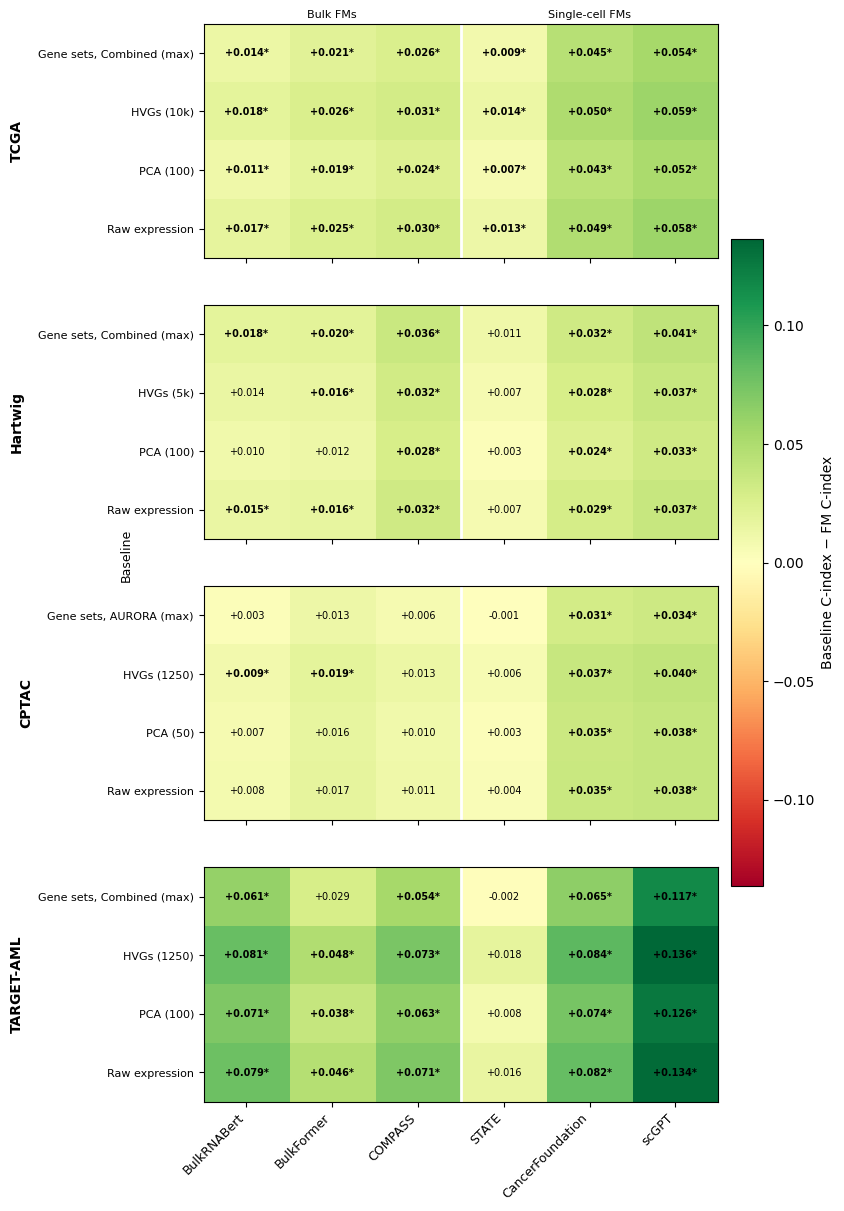

In [ ]:
df = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
df["baseline_nHVGs"] = df["baseline_nHVGs"].fillna("None").astype(str)

def make_baseline_label(row):
    b, n = row["baseline"], row["baseline_nHVGs"]
    if b == "max_combined":    return "Gene sets, Combined (max)"
    if b == "max_AURORA":      return "Gene sets, AURORA (max)"
    if b == "RNA_seq" and n == "10000.0": return "HVGs (10k)"
    if b == "RNA_seq" and n == "5000.0":  return "HVGs (5k)"
    if b == "RNA_seq" and n == "1250.0":  return "HVGs (1250)"
    if b == "PCA_100":                return "PCA (100)"
    if b == "PCA_50":                 return "PCA (50)"
    if b == "RNA_seq" and n == "None":    return "Raw expression"
    return None

df["baseline_label"] = df.apply(make_baseline_label, axis=1)
df = df[df["baseline_label"].notna()]

# Verify labels present
print(df["baseline_label"].unique())

fixed_row_order = [
    "Gene sets, Combined (max)",
    "Gene sets, AURORA (max)",
    "HVGs (10k)",
    "HVGs (5k)",
    "HVGs (1250)",
    "PCA (100)",
    "PCA (50)",
    "Raw expression",
]

fm_order = ["BulkRNABert", "BulkFormer", "COMPASS", "STATE", "CancerFoundation", "scGPT"]

vmax = df["mean_diff"].abs().max()

fig, axes = plt.subplots(4, 1, figsize=(8, 14), sharex=True)

for ax, dataset in zip(axes, DATASETS):
    sub = df[df["dataset"] == dataset].copy()
    rows = [r for r in fixed_row_order if r in sub["baseline_label"].values]

    pivot_diff = sub.pivot(index="baseline_label", columns="fm", values="mean_diff").reindex(
        index=rows, columns=fm_order)
    pivot_sig = sub.pivot(index="baseline_label", columns="fm", values="significant").reindex(
        index=rows, columns=fm_order)

    im = ax.imshow(pivot_diff.values, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")

    for i in range(len(rows)):
        for j in range(len(fm_order)):
            val = pivot_diff.values[i, j]
            sig = pivot_sig.values[i, j]
            if pd.isna(val):
                continue
            weight = "bold" if sig else "normal"
            star = "*" if sig else ""
            ax.text(j, i, f"{val:+.3f}{star}", ha="center", va="center",
                    fontsize=7, fontweight=weight, color="black")

    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontsize=8)
    ax.set_ylabel(dataset_labels.get(dataset, dataset), fontsize=10, fontweight="bold", labelpad=10)
    ax.axvline(2.5, color="white", linewidth=2)

axes[-1].set_xticks(range(len(fm_order)))
axes[-1].set_xticklabels(fm_order, rotation=45, ha="right", fontsize=9)
axes[0].text(1, -0.6, "Bulk FMs", ha="center", fontsize=8, color="black", transform=axes[0].transData)
axes[0].text(4, -0.6, "Single-cell FMs", ha="center", fontsize=8, color="black", transform=axes[0].transData)

plt.colorbar(im, ax=axes, label="Baseline C-index − FM C-index", shrink=0.6, pad=0.02)
fig.text(0.02, 0.5, "Baseline", va="center", rotation="vertical", fontsize=9)

plt.savefig(FIGURE_DIR / "supp_permutation_heatmap.png", bbox_inches="tight")
plt.show()

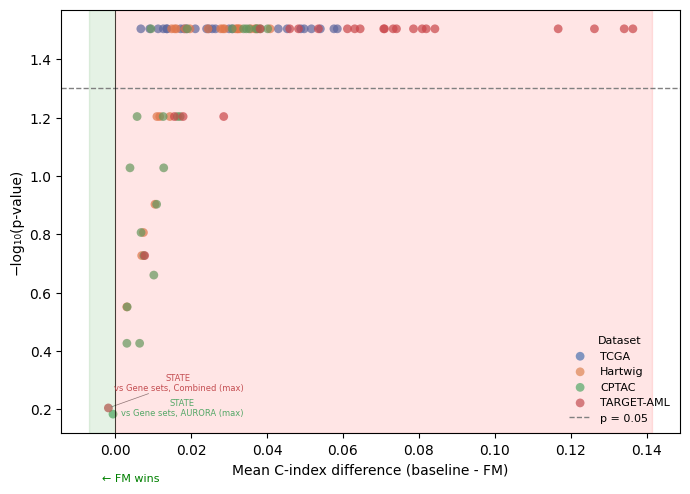

In [ ]:
df = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
df["baseline_nHVGs"] = df["baseline_nHVGs"].fillna("None").astype(str)
df["baseline_label"] = df.apply(make_baseline_label, axis=1)
df = df[df["baseline_label"].notna()]

df["neg_log10_p"] = -np.log10(df["p_value"])

fig, ax = plt.subplots(figsize=(7, 5))

for dataset in DATASETS:
    group = df[df["dataset"] == dataset]
    ax.scatter(
        group["mean_diff"],
        group["neg_log10_p"],
        color=dataset_colors[dataset],
        label=dataset_labels.get(dataset, dataset),
        alpha=0.7,
        s=40,
        edgecolors="none",
    )

# Annotate FM-winning points (mean_diff < 0)
texts = []
fm_wins = df[df["mean_diff"] < 0]
for _, row in fm_wins.iterrows():
    texts.append(ax.text(
        row["mean_diff"], row["neg_log10_p"],
        f"{row['fm']}\nvs {row['baseline_label']}",
        fontsize=6, color=dataset_colors[row["dataset"]],
    ))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# Significance threshold line
sig_threshold = -np.log10(0.05)
ax.axhline(sig_threshold, color="gray", linestyle="--", linewidth=1, label="p = 0.05")
ax.axvline(0, color="black", linestyle="-", linewidth=0.5)

# Shade region where FM wins
ax.axvspan(df["mean_diff"].min() - 0.005, 0, alpha=0.1, color="green")
ax.axvspan(0, df["mean_diff"].max() + 0.005, alpha=0.1, color="red")

ax.text(df["mean_diff"].min() * 0.3 - .003, -.05, "← FM wins", fontsize=8, color="green")

ax.set_xlabel("Mean C-index difference (baseline - FM)", fontsize=10)
ax.set_ylabel("−log₁₀(p-value)", fontsize=10)

ax.legend(title="Dataset", fontsize=8, title_fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "supp_pvalue_volcano.png", bbox_inches="tight")
plt.show()

### Extended Results

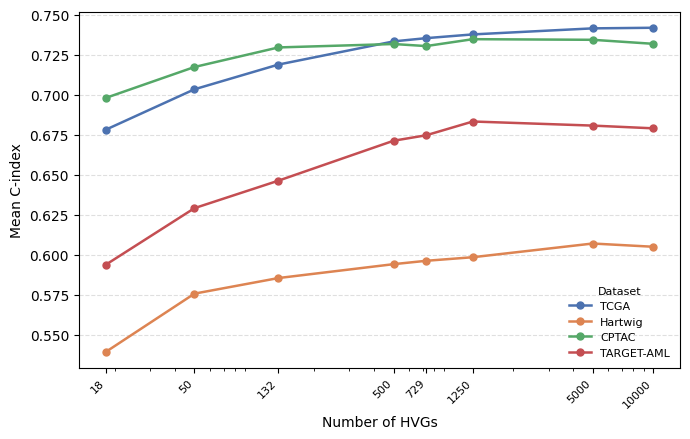

In [ ]:
# --- HVG line chart ---
HVG_VALUES = [18, 50, 132, 500, 729, 1250, 5000, 10000]

hvg_rows = []
for d in DATASETS:
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
    df_agg["nHVGs"] = df_agg["nHVGs"].fillna("None").astype(str)
    df_agg["overall_mean"] = pd.to_numeric(df_agg["overall_mean"], errors="coerce")

    # Keep only HVG rows (RNA_seq with numeric nHVGs)
    sub = df_agg[
        (df_agg["RNA_key"] == "RNA_seq") &
        (df_agg["nHVGs"] != "None")
    ].copy()
    sub["nHVGs_num"] = pd.to_numeric(sub["nHVGs"], errors="coerce")
    sub = sub.dropna(subset=["nHVGs_num", "overall_mean"])

    best = sub[["nHVGs_num", "overall_mean"]].copy()
    best["dataset"] = d

    hvg_rows.append(best)

hvg_df = pd.concat(hvg_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
for d in DATASETS:
    sub = hvg_df[hvg_df["dataset"] == d].sort_values("nHVGs_num")
    ax.plot(
        sub["nHVGs_num"], sub["overall_mean"],
        marker="o", label=dataset_labels.get(d, d),
        color=dataset_colors[d], linewidth=1.8, markersize=5,
    )

ax.set_xscale("log")
ax.set_xticks(HVG_VALUES)
ax.set_xticklabels(HVG_VALUES, rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Number of HVGs", fontsize=10)
ax.set_ylabel("Mean C-index", fontsize=10)
ax.legend(title="Dataset", fontsize=8, title_fontsize=8, frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "hvg_line_chart.png", bbox_inches="tight")
plt.show()

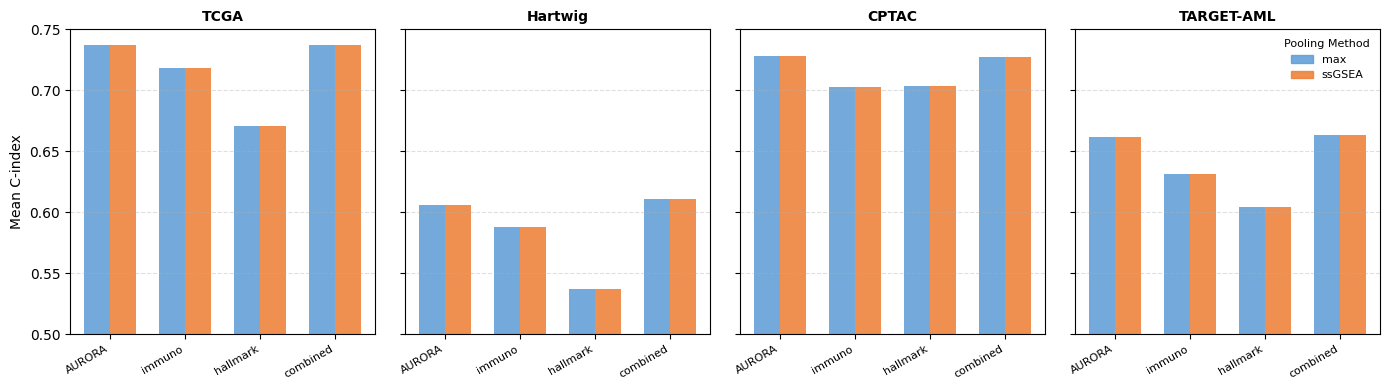

In [ ]:
# --- Gene set bar plot: max vs ssGSEA per gene set per dataset ---
GENE_SETS = ["AURORA", "immuno", "hallmark", "combined"]
METHODS   = ["max", "ssGSEA"]

gs_rows = []
for d in DATASETS:
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
    df_agg["overall_mean"] = pd.to_numeric(df_agg["overall_mean"], errors="coerce")

    for gs in GENE_SETS:
        for method in METHODS:
            rna_key = f"{method}_{gs}"
            sub = df_agg[df_agg["RNA_key"] == rna_key].dropna(subset=["overall_mean"])
            if sub.empty:
                continue
            best_mean = sub["overall_mean"].max()
            gs_rows.append({"dataset": d, "gene_set": gs, "method": method, "cindex_mean": best_mean})

gs_df = pd.DataFrame(gs_rows)

n_gs = len(GENE_SETS)
x = np.arange(n_gs)
width = 0.35
method_colors = {"max": "#5B9BD5", "ssGSEA": "#ED7D31"}

fig, axes = plt.subplots(1, n_datasets, figsize=(14, 4), sharey=True)
for ax, d in zip(axes, DATASETS):
    sub = gs_df[gs_df["dataset"] == d]
    for i, method in enumerate(METHODS):
        vals = [
            sub.loc[sub["gene_set"] == gs, "cindex_mean"].values[0]
            if not sub.loc[sub["gene_set"] == gs, "cindex_mean"].empty else np.nan
            for gs in GENE_SETS
        ]
        offset = (i - 0.5) * width
        ax.bar(x + offset, vals, width, label=method, color=method_colors[method], alpha=0.85)

    ax.set_xticks(x)
    ax.set_ylim(0.50, 0.75)
    ax.set_xticklabels(GENE_SETS, rotation=30, ha="right", fontsize=8)
    ax.set_title(dataset_labels.get(d, d), fontsize=10, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Mean C-index", fontsize=10)
handles = [plt.Rectangle((0,0),1,1, color=method_colors[m], alpha=0.85) for m in METHODS]
axes[-1].legend(handles, METHODS, title="Pooling Method", fontsize=8, title_fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "geneset_bar_chart.png", bbox_inches="tight")
plt.show()


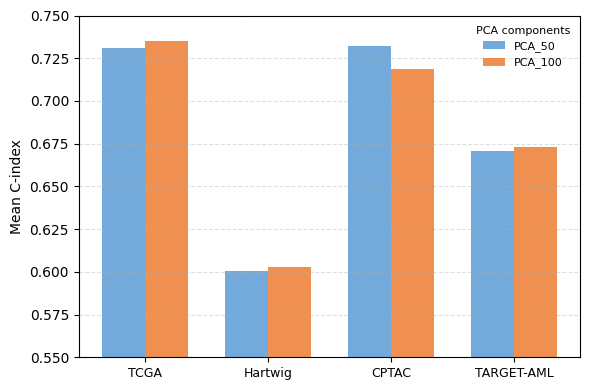

In [ ]:
# --- PCA bar plot: PCA_50 vs PCA_100 across datasets ---
PCA_KEYS = ["PCA_50", "PCA_100"]
pca_rows = []
for d in DATASETS:
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
    df_agg["overall_mean"] = pd.to_numeric(df_agg["overall_mean"], errors="coerce")

    for rna_key in PCA_KEYS:
        sub = df_agg[df_agg["RNA_key"] == rna_key].dropna(subset=["overall_mean"])
        if sub.empty:
            continue
        pca_rows.append({
            "dataset": d,
            "rna_key": rna_key,
            "cindex_mean": sub["overall_mean"].max(),
        })

pca_df = pd.DataFrame(pca_rows)

x = np.arange(n_datasets)
width = 0.35
pca_colors = {"PCA_50": "#5B9BD5", "PCA_100": "#ED7D31"}
labels_x = [dataset_labels.get(d, d) for d in DATASETS]

fig, ax = plt.subplots(figsize=(6, 4))
for i, rna_key in enumerate(PCA_KEYS):
    vals = [
        pca_df.loc[(pca_df["dataset"] == d) & (pca_df["rna_key"] == rna_key), "cindex_mean"].values[0]
        if not pca_df.loc[(pca_df["dataset"] == d) & (pca_df["rna_key"] == rna_key)].empty else np.nan
        for d in DATASETS
    ]
    offset = (i - 0.5) * width
    ax.bar(x + offset, vals, width, label=rna_key, color=pca_colors[rna_key], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_ylabel("Mean C-index", fontsize=10)
ax.set_ylim(0.55, 0.75)
ax.legend(title="PCA components", fontsize=8, title_fontsize=8, frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "pca_bar_chart.png", bbox_inches="tight")
plt.show()


### TCGA results

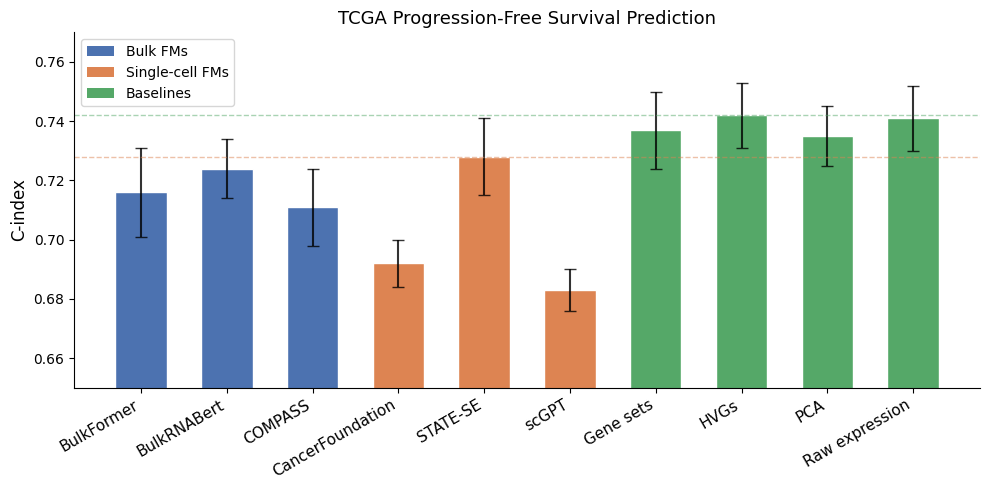

In [ ]:
labels = [
    'BulkFormer', 'BulkRNABert', 'COMPASS',
    'CancerFoundation', 'STATE-SE', 'scGPT',
    'Gene sets', 'HVGs', 'PCA', 'Raw expression'
]

means = [0.716, 0.724, 0.711, 0.692, 0.728, 0.683, 0.737, 0.742, 0.735, 0.741]
errors = [0.015, 0.010, 0.013, 0.008, 0.013, 0.007, 0.013, 0.011, 0.010, 0.011]

colors = (
    ['#4C72B0'] * 3 +   # Bulk FMs
    ['#DD8452'] * 3 +   # Single-cell FMs
    ['#55A868'] * 4     # Baselines
)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(labels))
bars = ax.bar(x, means, color=colors, capsize=4, width=0.6, edgecolor='white', yerr=errors, error_kw={'elinewidth':1.5, 'alpha':0.8})

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=11)
ax.set_ylabel('C-index', fontsize=12)
ax.set_title('TCGA Progression-Free Survival Prediction', fontsize=13)
ax.set_ylim(0.65, 0.77)
ax.axhline(y=0.728, color='#DD8452', linestyle='--', linewidth=1, alpha=0.5, label='Best FM (STATE-SE)')
ax.axhline(y=0.742, color='#55A868', linestyle='--', linewidth=1, alpha=0.5, label='Best baseline (HVGs)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4C72B0', label='Bulk FMs'),
    Patch(facecolor='#DD8452', label='Single-cell FMs'),
    Patch(facecolor='#55A868', label='Baselines'),
]
ax.legend(handles=legend_elements, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('tcga_results.pdf', dpi=300, bbox_inches='tight')
plt.show()

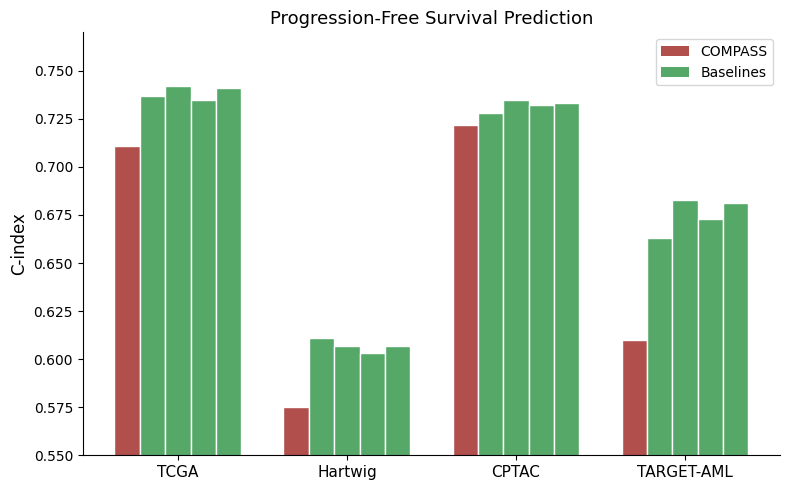

In [ ]:
labels = ['COMPASS', 'Gene sets', 'HVGs', 'PCA', 'Raw expression']
datasets = ['TCGA', 'Hartwig', 'CPTAC', 'TARGET-AML']

tcga = [0.711, 0.737, 0.742, 0.735, 0.741]
hartwig = [0.575, 0.611, 0.607, 0.603, 0.607]
cptac = [0.722, 0.728, 0.735, 0.732, 0.733]
target_aml = [0.610, 0.663, 0.683, 0.673, 0.681]

# Shape: (n_methods, n_datasets)
data = np.array([tcga, hartwig, cptac, target_aml]).T

colors = [
    "#B04F4C",  # COMPASS
    '#55A868',  # Gene sets
    '#55A868',  # HVGs
    '#55A868',  # PCA
    '#55A868',  # Raw expression
]

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(datasets))   # one x location per dataset group
width = 0.15                   # width of each bar

for i, label in enumerate(labels):
    ax.bar(
        x + (i - 2) * width,   # center the 5 bars around each dataset
        data[i],
        width=width,
        label=label,
        color=colors[i],
        edgecolor='white'
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets, fontsize=11)
ax.set_ylabel('C-index', fontsize=12)
ax.set_title('Progression-Free Survival Prediction', fontsize=13)
ax.set_ylim(0.55, 0.77)

legend_elements = [
    Patch(facecolor="#B04F4C", label='COMPASS'),
    Patch(facecolor='#55A868', label='Baselines'),
]
ax.legend(handles=legend_elements, fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('compass_vs_baselines_grouped.pdf', dpi=300, bbox_inches='tight')
plt.show()

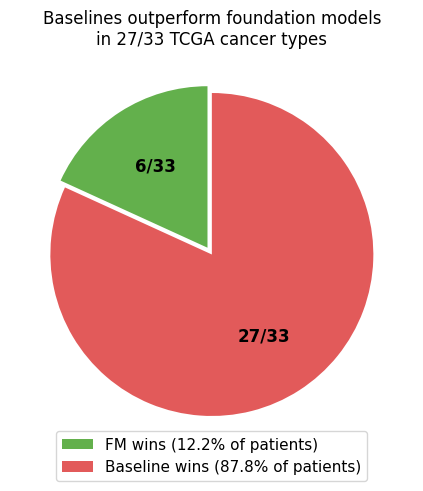

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

sizes = [6/33 * 100, 27/33 * 100]
colors = ["#63B04C", "#E25A5A"]
explode = (0.05, 0)

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=['', ''],
    colors=colors,
    explode=explode,
    autopct=lambda p: f'{round(p/100 * 33)}/33',
    startangle=90,
    textprops={'fontsize': 12}
)

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')

ax.legend(
    wedges,
    ['FM wins (12.2% of patients)', 'Baseline wins (87.8% of patients)'],
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),
    fontsize=11
)

ax.set_title('Baselines outperform foundation models\nin 27/33 TCGA cancer types', fontsize=12)

plt.tight_layout()
plt.savefig('tcga_pie.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Summary Results

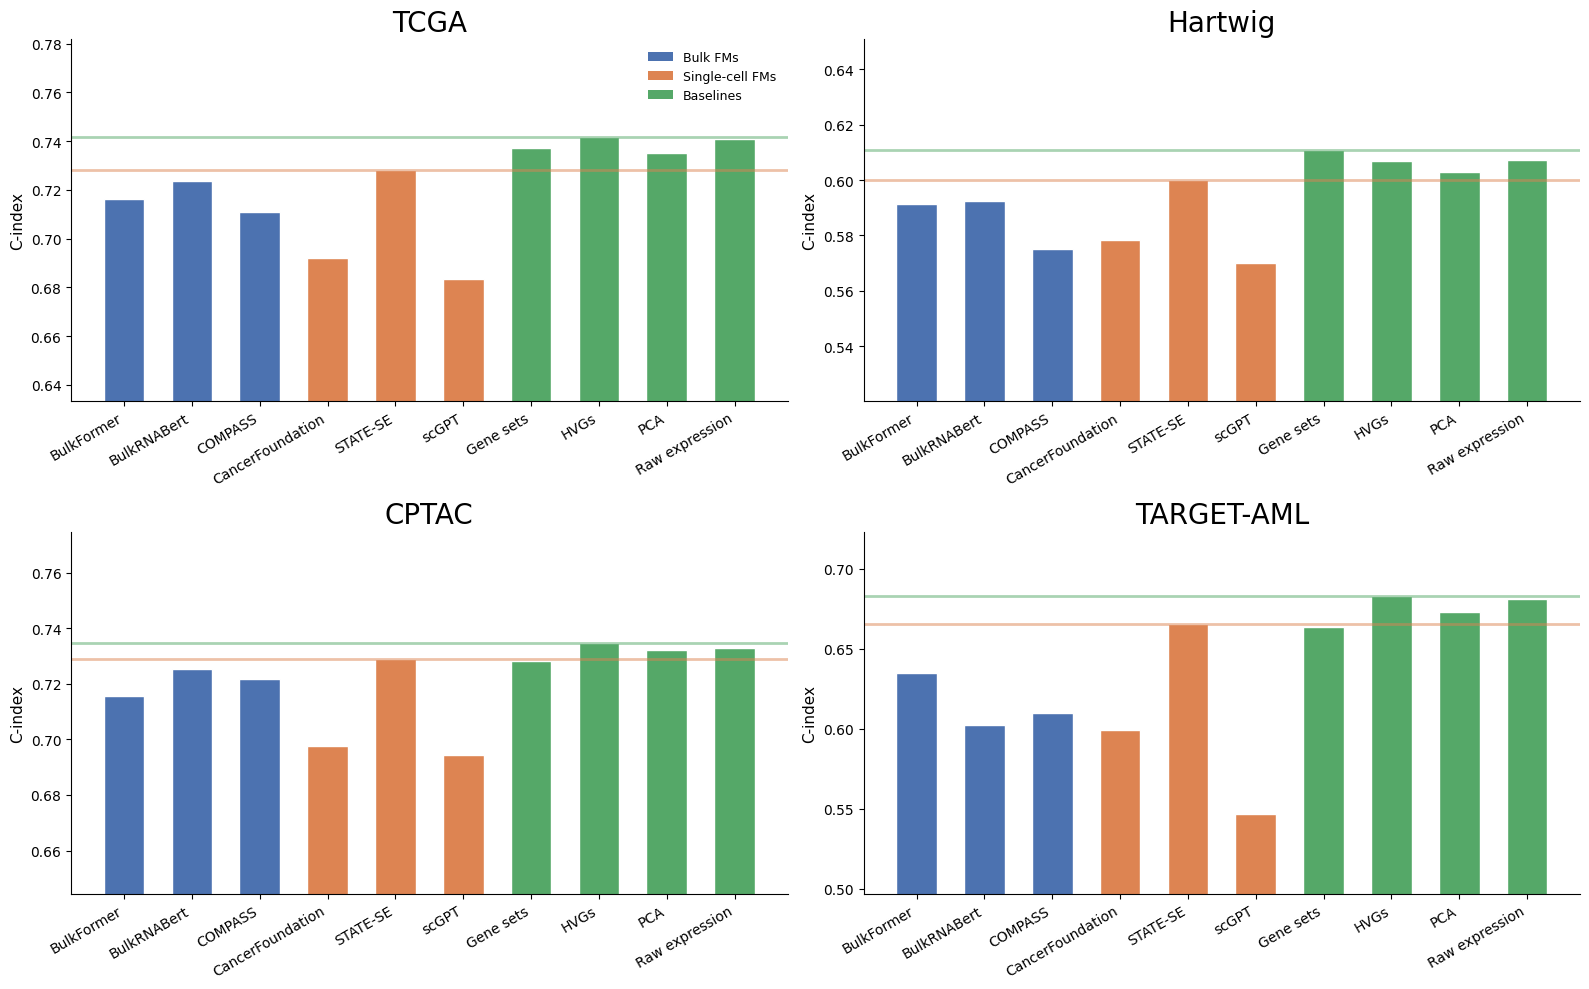

In [ ]:
FM_KEYS_ORDERED    = ['BulkFormer', 'BulkRNABert', 'COMPASS', 'CancerFoundation', 'STATE', 'scGPT']
BASELINE_CATS      = ['GS', 'HVG', 'PCA', 'Raw_expression']
BASELINE_LABELS    = {'GS': 'Gene sets', 'HVG': 'HVGs', 'PCA': 'PCA', 'Raw_expression': 'Raw expression'}
FM_DISPLAY         = {'STATE': 'STATE-SE'}   # rename for display only

COLORS = ['#4C72B0'] * 3 + ['#DD8452'] * 3 + ['#55A868'] * 4

# ── Pull best values per model type from agg_filtered CSVs ───────────────────
def get_dataset_bar_data(dataset):
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg_filtered.csv")
    df["nHVGs"]       = df["nHVGs"].fillna("None").astype(str)
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    df["overall_std"]  = pd.to_numeric(df["overall_std"],  errors="coerce")
    df["category"]     = df.apply(lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1)

    means, errs, labels = [], [], []

    for fm in FM_KEYS_ORDERED:
        sub = df[df["RNA_key"] == fm]
        if sub.empty or sub["overall_mean"].isna().all():
            means.append(np.nan); errs.append(0)
        else:
            row = sub.loc[sub["overall_mean"].idxmax()]
            means.append(row["overall_mean"])
            errs.append(row["overall_std"] if pd.notna(row["overall_std"]) else 0)
        labels.append(FM_DISPLAY.get(fm, fm))

    for cat in BASELINE_CATS:
        sub = df[df["category"] == cat]
        if sub.empty or sub["overall_mean"].isna().all():
            means.append(np.nan); errs.append(0)
        else:
            row = sub.loc[sub["overall_mean"].idxmax()]
            means.append(row["overall_mean"])
            errs.append(row["overall_std"] if pd.notna(row["overall_std"]) else 0)
        labels.append(BASELINE_LABELS[cat])

    return labels, np.array(means), np.array(errs)

# ── 2×2 plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4C72B0', label='Bulk FMs'),
    Patch(facecolor='#DD8452', label='Single-cell FMs'),
    Patch(facecolor='#55A868', label='Baselines'),
]

for ax, dataset in zip(axes, DATASETS):
    labels, means, errs = get_dataset_bar_data(dataset)
    x = np.arange(len(labels))

    ax.bar(x, means, color=COLORS, capsize=4, width=0.6,
           edgecolor='white', error_kw={"linewidth": 1})

    best_fm   = np.nanmax(means[:6])
    best_base = np.nanmax(means[6:])
    best_fm_label   = labels[np.nanargmax(means[:6])]
    best_base_label = labels[6 + np.nanargmax(means[6:])]

    ax.axhline(best_fm,   color='#DD8452', linestyle='solid', linewidth=2, alpha=0.5,
               label=f'Best FM ({best_fm_label})')
    ax.axhline(best_base, color='#55A868', linestyle='solid', linewidth=2, alpha=0.5,
               label=f'Best baseline ({best_base_label})')

    ymin = max(0, np.nanmin(means) - 0.05)
    ymax = np.nanmax(means) + 0.04
    ax.set_ylim(ymin, ymax)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=10)
    ax.set_ylabel('C-index', fontsize=11)
    ax.set_title(dataset_labels.get(dataset, dataset), fontsize=20)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.grid(axis='y', linestyle='--', alpha=0.35)

axes[0].legend(handles=legend_elements, fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'all_datasets_results_2x2.pdf', dpi=300, bbox_inches='tight')
plt.show()


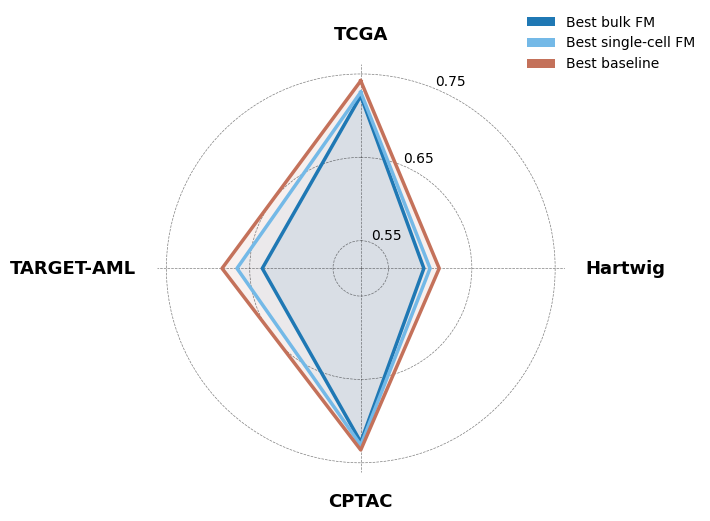

In [ ]:
FM_KEYS_ORDERED = ['BulkFormer', 'BulkRNABert', 'COMPASS', 'CancerFoundation', 'STATE', 'scGPT']
BASELINE_CATS   = ['GS', 'HVG', 'PCA', 'Raw_expression']
BASELINE_LABELS = {'GS': 'Gene sets', 'HVG': 'HVGs', 'PCA': 'PCA', 'Raw_expression': 'Raw expression'}
FM_DISPLAY      = {'STATE': 'STATE-SE'}

# define group keys before they're used
BULK_FM_KEYS  = [FM_DISPLAY.get(k, k) for k in FM_KEYS_ORDERED[:3]]
SC_FM_KEYS    = [FM_DISPLAY.get(k, k) for k in FM_KEYS_ORDERED[3:]]
BASELINE_KEYS = list(BASELINE_LABELS.values())

def get_best_per_model(dataset):
    sub = df_all[df_all["dataset"] == dataset]
    out = {}
    for fm in FM_KEYS_ORDERED:
        rows = sub[sub["RNA_key"] == fm]
        out[FM_DISPLAY.get(fm, fm)] = rows["overall_mean"].max() if not rows.empty else np.nan
    for cat in BASELINE_CATS:
        rows = sub[sub["category"] == cat]
        out[BASELINE_LABELS[cat]] = rows["overall_mean"].max() if not rows.empty else np.nan
    return out

# use the global DATASETS (cell 2) — "TARGET_AML" with underscore matches df_all
all_models_data = {}
for dataset in DATASETS:
    for model, val in get_best_per_model(dataset).items():
        all_models_data.setdefault(model, {})[dataset] = val

group_best = {
    'Bulk FMs':        {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in BULK_FM_KEYS])  for d in DATASETS},
    'Single-cell FMs': {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in SC_FM_KEYS])    for d in DATASETS},
    'Baselines':       {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in BASELINE_KEYS]) for d in DATASETS},
}
GROUP_COLORS = {'Bulk FMs': '#1F78B4', 'Single-cell FMs': '#74B9E7', 'Baselines': '#C4715A'}

# ── radar ─────────────────────────────────────────────────────────────────────
N      = len(DATASETS)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)    # TCGA at top
ax.set_theta_direction(-1)         # clockwise

for label, vals_dict in group_best.items():
    vals = [vals_dict.get(d, np.nan) for d in DATASETS]
    ax.plot(angles, vals + vals[:1], color=GROUP_COLORS[label], linewidth=2.5)
    ax.fill(angles, vals + vals[:1], color=GROUP_COLORS[label], alpha=0.10)

ax.set_thetagrids(np.degrees(angles[:-1]), labels=[''] * N)

all_vals = [v for m in all_models_data.values() for v in m.values() if not np.isnan(v)]
rmin = max(0.45, np.min(all_vals) - 0.03)
rmax = np.max(all_vals) + 0.02
ax.set_ylim(rmin, rmax)

# spoke labels — ha/va from spoke direction so text is centered on each radius
r_label = rmax + (rmax - rmin) * 0.10
for dataset, angle in zip(DATASETS, angles[:-1]):
    display = dataset_labels.get(dataset, dataset)
    disp_angle = np.pi / 2 - angle
    cos_a, sin_a = np.cos(disp_angle), np.sin(disp_angle)
    ha = 'center' if abs(cos_a) < 0.5 else ('left' if cos_a > 0 else 'right')
    va = 'center' if abs(sin_a) < 0.5 else ('bottom' if sin_a > 0 else 'top')
    ax.text(angle, r_label, display, ha=ha, va=va, fontsize=13, fontweight='bold')

rticks = np.array([0.55, 0.65, 0.75])
rticks = rticks[(rticks >= rmin) & (rticks <= rmax)]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{v:.2f}" for v in rticks], fontsize=10)
ax.set_rlabel_position(22.5)
ax.grid(color='black', linestyle='--', linewidth=0.5, alpha=0.5)
ax.spines['polar'].set_visible(False)

legend_handles = [
    mpatches.Patch(facecolor='#1F78B4', label='Best bulk FM'),
    mpatches.Patch(facecolor='#74B9E7', label='Best single-cell FM'),
    mpatches.Patch(facecolor='#C4715A', label='Best baseline'),
]
ax.legend(handles=legend_handles, loc='upper right',
          bbox_to_anchor=(1.35, 1.15), fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'all_datasets_results_radar.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Compare FMs with Similar Baselines

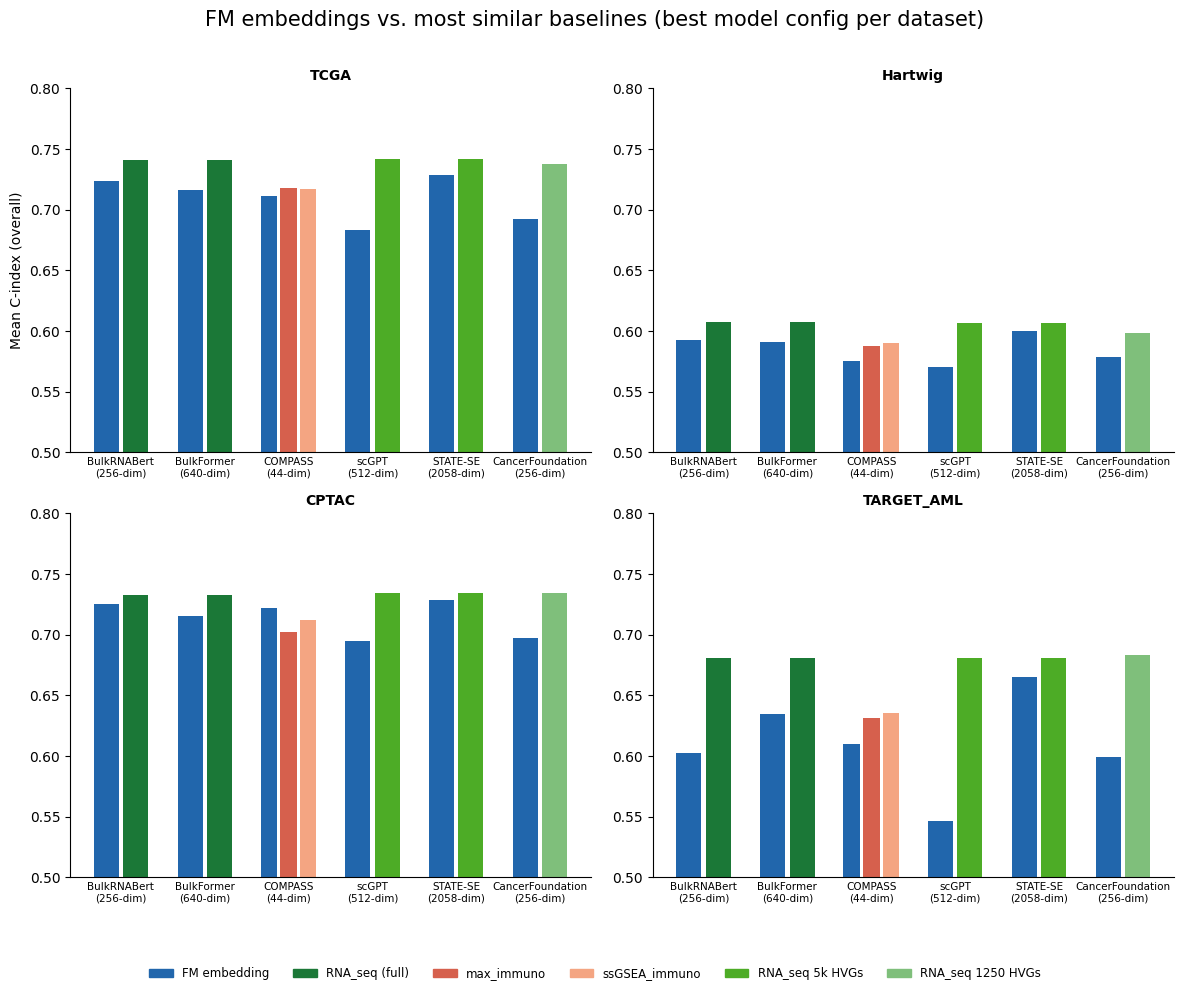

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# FM → most-similar baseline comparison map
# (display_label, rna_key_in_csv, nHVGs_as_float_or_None)
#
# Bulk FMs (BulkRNABert, BulkFormer): compared to RNA_seq with no HVG
# filtering (full transcriptome), since both models take the full
# transcriptome as input — this tests whether the FM's learned compression
# beats raw expression from the same data.
# ─────────────────────────────────────────────────────────────────────────────
FM_BASELINE_MAP = {
    "BulkRNABert":      [("RNA_seq (full)",    "RNA_seq",       None)],
    "BulkFormer":       [("RNA_seq (full)",    "RNA_seq",       None)],
    "COMPASS":          [("max_immuno",        "max_immuno",    None),
                         ("ssGSEA_immuno",     "ssGSEA_immuno", None)],
    "scGPT":            [("RNA_seq 5k HVGs",   "RNA_seq",       5000.0)],
    "STATE":            [("RNA_seq 5k HVGs",   "RNA_seq",       5000.0)],
    "CancerFoundation": [("RNA_seq 1250 HVGs", "RNA_seq",       1250.0)],
}
FM_ORDER = ["BulkRNABert", "BulkFormer", "COMPASS", "scGPT", "STATE", "CancerFoundation"]
FM_LABEL = {
    "BulkRNABert":      "BulkRNABert\n(256-dim)",
    "BulkFormer":       "BulkFormer\n(640-dim)",
    "COMPASS":          "COMPASS\n(44-dim)",
    "scGPT":            "scGPT\n(512-dim)",
    "STATE":            "STATE-SE\n(2058-dim)",
    "CancerFoundation": "CancerFoundation\n(256-dim)",
}
BL_COLOR_MAP = {
    "RNA_seq (full)":    "#1b7837",
    "max_immuno":        "#d6604d",
    "ssGSEA_immuno":     "#f4a582",
    "RNA_seq 5k HVGs":   "#4dac26",
    "RNA_seq 1250 HVGs": "#7fbf7b",
}
FM_COLOR = "#2166ac"


def _best_row(df, rna_key, nHVGs=None):
    """Return the row with the highest overall_mean for a given (rna_key, nHVGs)."""
    df = df.copy()
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    df["nHVGs"]        = pd.to_numeric(df["nHVGs"],        errors="coerce")
    if nHVGs is None:
        mask = (df["RNA_key"] == rna_key) & df["nHVGs"].isna()
    else:
        mask = (df["RNA_key"] == rna_key) & (df["nHVGs"] == nHVGs)
    sub = df[mask].dropna(subset=["overall_mean"])
    return sub.loc[sub["overall_mean"].idxmax()] if not sub.empty else None


fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=False) # Adjusted figsize for 2x2
axes_flat = axes.flatten()

legend_items = {}   # ordered: label → Patch

for ax, d in zip(axes_flat, DATASETS):
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")

    x = 0
    tick_pos, tick_lbl = [], []

    for fm in FM_ORDER:
        baselines = FM_BASELINE_MAP[fm]
        n_bars = 1 + len(baselines)
        bw     = 0.7 / n_bars                                     # individual bar width
        offs   = np.arange(n_bars) * bw - (n_bars - 1) * bw / 2  # center the group

        fm_row = _best_row(df_agg, fm)
        if fm_row is None:
            x += 1
            continue

        # FM bar
        ax.bar(x + offs[0], fm_row["overall_mean"], width=bw * 0.85,
               color=FM_COLOR,
               capsize=2.5,
               error_kw={"linewidth": 0.8, "ecolor": "#555"})
        legend_items.setdefault("FM embedding",
                                mpatches.Patch(color=FM_COLOR, label="FM embedding"))

        # Baseline bar(s)
        for j, (bl_lbl, rk, nhvg) in enumerate(baselines):
            color  = BL_COLOR_MAP[bl_lbl]
            bl_row = _best_row(df_agg, rk, nhvg)
            if bl_row is not None:
                ax.bar(x + offs[j + 1], bl_row["overall_mean"], width=bw * 0.85,
                       color=color,
                       capsize=2.5,
                       error_kw={"linewidth": 0.8, "ecolor": "#555"})
            legend_items.setdefault(bl_lbl, mpatches.Patch(color=color, label=bl_lbl))

        tick_pos.append(x)
        tick_lbl.append(FM_LABEL.get(fm, fm))
        x += 1

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_lbl, fontsize=7.5)
    ax.set_ylim(0.50, 0.80)
    ax.set_title(d, fontsize=10, fontweight="bold")
    if d == DATASETS[0]:
        ax.set_ylabel("Mean C-index (overall)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)

fig.legend(
    handles=list(legend_items.values()),
    loc="lower center",
    ncol=len(legend_items),
    fontsize=8.5,
    bbox_to_anchor=(0.5, -0.08),
    frameon=False,
)
fig.suptitle("FM embeddings vs. most similar baselines (best model config per dataset)",
             fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fm_vs_similar_baselines.png", bbox_inches="tight")
plt.show()

### Examine Concat Results

In [ ]:
CONCAT_BASE = REPO_DIR / "concat_model_outputs"

BEST_HVG_PER_DATASET = {"TCGA": 10000, "Hartwig": 5000, "CPTAC": 1250, "TARGET_AML": 1250}
CONCAT_DATASETS = ["TCGA", "Hartwig", "CPTAC", "TARGET_AML"]
FM_ORDER = ["BulkFormer", "BulkRNABert", "COMPASS", "scGPT", "STATE", "CancerFoundation"]

concat_dfs = []
for dataset in CONCAT_DATASETS:
    csv = CONCAT_BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if csv.exists():
        concat_dfs.append(pd.read_csv(csv))
    else:
        print(f"Missing: {csv}")

concat_df = pd.concat(concat_dfs, ignore_index=True)
print(f"Loaded {len(concat_df)} concat runs across {concat_df['dataset'].nunique()} datasets")
concat_df[["dataset", "arch", "loss", "fm_key", "n_hvgs", "seed", "split", "overall"]].head(10)

Loaded 960 concat runs across 4 datasets


,dataset,arch,loss,fm_key,n_hvgs,seed,split,overall
0,TCGA,Linear,CIndex,BulkFormer,10000,37,0,0.717337
1,TCGA,Linear,CIndex,BulkFormer,10000,37,1,0.743034
2,TCGA,Linear,CIndex,BulkFormer,10000,37,2,0.736677
3,TCGA,Linear,CIndex,BulkFormer,10000,37,3,0.745347
4,TCGA,Linear,CIndex,BulkFormer,10000,37,4,0.748958
5,TCGA,Linear,CIndex,BulkFormer,10000,42,0,0.717211
6,TCGA,Linear,CIndex,BulkFormer,10000,42,1,0.741708
7,TCGA,Linear,CIndex,BulkFormer,10000,42,2,0.738060
8,TCGA,Linear,CIndex,BulkFormer,10000,42,3,0.741380
9,TCGA,Linear,CIndex,BulkFormer,10000,42,4,0.752974


In [ ]:
hvg_dfs = []
for dataset in CONCAT_DATASETS:
    csv = BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if not csv.exists():
        print(f"Missing HVG baseline: {csv}")
        continue
    df = pd.read_csv(csv)
    best_n = BEST_HVG_PER_DATASET[dataset]
    df = df[(df["RNA_key"] == "RNA_seq") & (df["nHVGs"] == best_n)].copy()
    df = df.rename(columns={"overall": "hvg_cindex"})
    hvg_dfs.append(df[["dataset", "arch", "loss", "seed", "split", "hvg_cindex"]])

hvg_df = pd.concat(hvg_dfs, ignore_index=True)
print(f"Loaded {len(hvg_df)} HVG baseline runs")
hvg_df.head()

Loaded 160 HVG baseline runs


,dataset,arch,loss,seed,split,hvg_cindex
0,TCGA,Linear,CIndex,37,0,0.716249
1,TCGA,Linear,CIndex,37,1,0.751437
2,TCGA,Linear,CIndex,37,2,0.737461
3,TCGA,Linear,CIndex,37,3,0.742170
4,TCGA,Linear,CIndex,37,4,0.739322


In [ ]:
fm_dfs = []
for dataset in CONCAT_DATASETS:
    csv = BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if not csv.exists():
        continue
    df = pd.read_csv(csv)
    df = df[df["RNA_key"].isin(FM_ORDER)].copy()
    df = df.rename(columns={"RNA_key": "fm_key", "overall": "fm_only_cindex"})
    fm_dfs.append(df[["dataset", "arch", "loss", "fm_key", "seed", "split", "fm_only_cindex"]])

fm_only_df = pd.concat(fm_dfs, ignore_index=True)
print(f"Loaded {len(fm_only_df)} FM-only runs")
fm_only_df.head()

Loaded 960 FM-only runs


,dataset,arch,loss,fm_key,seed,split,fm_only_cindex
0,TCGA,Linear,CIndex,BulkFormer,37,0,0.691443
1,TCGA,Linear,CIndex,BulkFormer,37,1,0.721369
2,TCGA,Linear,CIndex,BulkFormer,37,2,0.710670
3,TCGA,Linear,CIndex,BulkFormer,37,3,0.723396
4,TCGA,Linear,CIndex,BulkFormer,37,4,0.731742


In [ ]:
# Merge on (dataset, arch, loss, seed, split) for paired per-run comparison
merged = (
    concat_df
    .merge(hvg_df,     on=["dataset", "arch", "loss", "seed", "split"], how="inner")
    .merge(fm_only_df, on=["dataset", "arch", "loss", "fm_key", "seed", "split"], how="left")
)
merged["delta_vs_hvg"] = merged["overall"] - merged["hvg_cindex"]
merged["delta_vs_fm"]  = merged["overall"] - merged["fm_only_cindex"]

# Aggregate across seeds and splits
agg = (
    merged.groupby(["dataset", "arch", "loss", "fm_key"])
    .agg(
        concat_mean   = ("overall",         "mean"),
        concat_std    = ("overall",         "std"),
        hvg_mean      = ("hvg_cindex",      "mean"),
        fm_only_mean  = ("fm_only_cindex",  "mean"),
        delta_vs_hvg_mean = ("delta_vs_hvg", "mean"),
        delta_vs_hvg_std  = ("delta_vs_hvg", "std"),
        delta_vs_fm_mean  = ("delta_vs_fm",  "mean"),
        n_runs        = ("overall",         "count"),
    )
    .reset_index()
)

# Pick best (arch, loss) per (dataset, fm_key) by concat mean C-index
best_idx = agg.groupby(["dataset", "fm_key"])["concat_mean"].idxmax()
best = agg.loc[best_idx].copy().reset_index(drop=True)
best["fm_key"] = pd.Categorical(best["fm_key"], categories=FM_ORDER, ordered=True)
best = best.sort_values(["dataset", "fm_key"]).reset_index(drop=True)

print("Three-way comparison (best arch/loss per FM+dataset):")
display(best[["dataset", "fm_key", "arch", "loss",
              "fm_only_mean", "hvg_mean", "concat_mean",
              "delta_vs_hvg_mean", "delta_vs_hvg_std", "delta_vs_fm_mean"]].to_string(index=False))

Three-way comparison (best arch/loss per FM+dataset):


TypeError: 'str' object is not callable

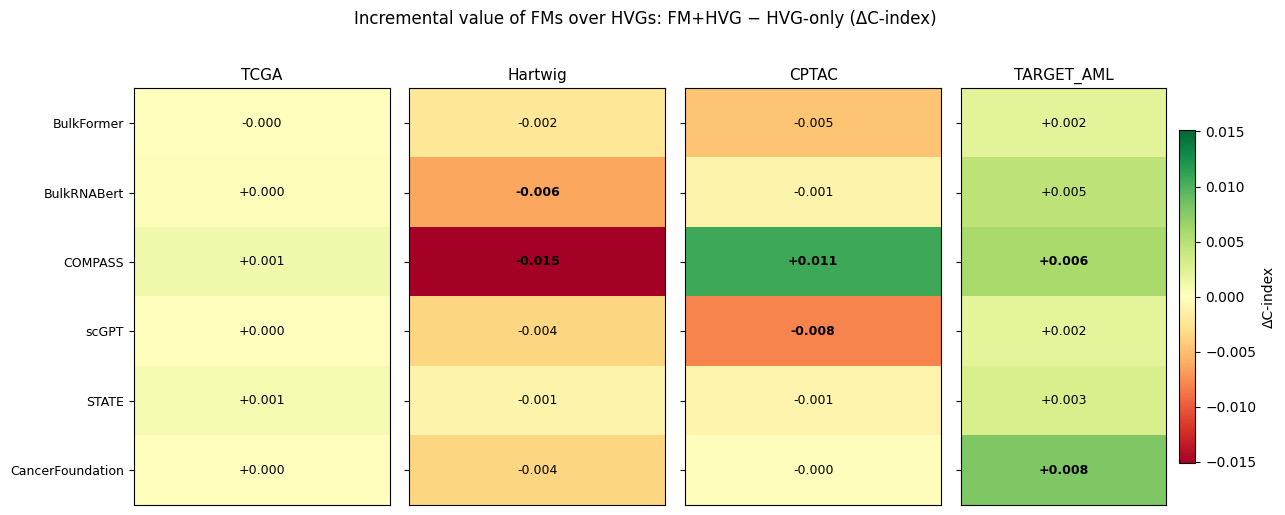

In [ ]:
fig, axes = plt.subplots(1, len(CONCAT_DATASETS), figsize=(13, 5), sharey=True)

vmax = max(best["delta_vs_hvg_mean"].abs().max(), 0.01)

for ax, dataset in zip(axes, CONCAT_DATASETS):
    sub = best[best["dataset"] == dataset].set_index("fm_key").reindex(FM_ORDER)
    vals = sub["delta_vs_hvg_mean"].values.reshape(-1, 1)

    im = ax.imshow(vals, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")

    for i, fm in enumerate(FM_ORDER):
        if fm in sub.index and not pd.isna(sub.loc[fm, "delta_vs_hvg_mean"]):
            v = sub.loc[fm, "delta_vs_hvg_mean"]
            ax.text(0, i, f"{v:+.3f}", ha="center", va="center", fontsize=9,
                    fontweight="bold" if abs(v) > 0.005 else "normal", color="black")

    ax.set_title(dataset, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks(range(len(FM_ORDER)))
    if ax is axes[0]:
        ax.set_yticklabels(FM_ORDER, fontsize=9)

fig.suptitle("Incremental value of FMs over HVGs: FM+HVG − HVG-only (ΔC-index)", fontsize=12, y=1.02)
plt.colorbar(im, ax=axes[-1], label="ΔC-index", shrink=0.8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "concat_delta_vs_hvg_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


### Linear Probe

In [ ]:
lp = pd.read_csv(REPO_DIR / "benchmarking_results" / "linear_probing_results.csv")

# Readable label for each embedding spec
def emb_label(rna_key, n_hvgs):
    if rna_key == "RNA_seq":
        return f"RNA_seq_full" if pd.isna(n_hvgs) else f"RNA_seq_{int(n_hvgs)}"
    return rna_key

lp["emb"] = lp.apply(lambda r: emb_label(r["rna_key"], r["n_hvgs"]), axis=1)

# Average metrics over 5 splits
group_cols = ["dataset", "emb", "rna_key", "n_hvgs", "task"]
lp_agg = (
    lp.groupby(group_cols, dropna=False)   # <-- add this
    .agg(
        accuracy_mean        = ("accuracy",       "mean"),
        accuracy_std         = ("accuracy",       "std"),
        macro_f1_mean        = ("macro_f1",       "mean"),
        macro_f1_std         = ("macro_f1",       "std"),
        weighted_kappa_mean  = ("weighted_kappa", "mean"),
        weighted_kappa_std   = ("weighted_kappa", "std"),
        n_splits             = ("accuracy",       "count"),
    )
    .reset_index()
)

print(f"Loaded {len(lp)} rows → {len(lp_agg)} aggregated (dataset × emb × task)")
lp_agg.head(10)

Loaded 1000 rows → 200 aggregated (dataset × emb × task)


,dataset,emb,rna_key,n_hvgs,task,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_kappa_mean,weighted_kappa_std,n_splits
0,CPTAC,BulkFormer,BulkFormer,NaN,cancer_type,0.916215,0.011888,0.516940,0.063960,NaN,NaN,5
1,CPTAC,BulkFormer,BulkFormer,NaN,grade,0.599012,0.013292,0.198480,0.026310,0.071289,0.045111,5
2,CPTAC,BulkFormer,BulkFormer,NaN,organ,0.915122,0.013662,0.532884,0.066234,NaN,NaN,5
3,CPTAC,BulkRNABert,BulkRNABert,NaN,cancer_type,0.885757,0.013199,0.495517,0.057758,NaN,NaN,5
4,CPTAC,BulkRNABert,BulkRNABert,NaN,grade,0.591311,0.009121,0.221012,0.052135,0.053097,0.095249,5
5,CPTAC,BulkRNABert,BulkRNABert,NaN,organ,0.882484,0.017834,0.473548,0.052977,NaN,NaN,5
6,CPTAC,COMPASS,COMPASS,NaN,cancer_type,0.956213,0.015430,0.958492,0.014867,NaN,NaN,5
7,CPTAC,COMPASS,COMPASS,NaN,grade,0.580571,0.032738,0.179771,0.030133,0.056156,0.047940,5
8,CPTAC,COMPASS,COMPASS,NaN,organ,0.951479,0.020240,0.954212,0.020190,NaN,NaN,5
9,CPTAC,CancerFoundation,CancerFoundation,NaN,cancer_type,0.736695,0.021930,0.336118,0.023329,NaN,NaN,5


In [ ]:
EMB_ORDER = [
    "BulkFormer", "BulkRNABert", "COMPASS",
    "scGPT", "STATE", "CancerFoundation",
    "ssGSEA_AURORA", "ssGSEA_immuno", "ssGSEA_hallmark", "ssGSEA_combined",
    "max_AURORA", "max_immuno", "max_hallmark", "max_combined",
    "PCA_50", "PCA_100",
    "RNA_seq_18", "RNA_seq_50", "RNA_seq_132", "RNA_seq_500",
    "RNA_seq_729", "RNA_seq_1250", "RNA_seq_5000", "RNA_seq_10000", "RNA_seq_full",
]

LP_DATASETS = ["TCGA", "CPTAC", "Hartwig"]  # TARGET_AML had no applicable tasks
TASKS       = ["cancer_type", "grade", "organ"]
TASK_METRIC = {"cancer_type": "macro_f1", "grade": "weighted_kappa", "organ": "macro_f1"}
TASK_LABEL  = {"cancer_type": "Cancer type\n(macro F1)",
               "grade":       "Tumor grade\n(weighted κ)",
               "organ":       "Tumor location\n(macro F1)"}

In [ ]:
rows = []
for task in TASKS:
    metric = TASK_METRIC[task] + "_mean"
    sub = lp_agg[lp_agg["task"] == task]
    for dataset in LP_DATASETS:
        dsub = sub[sub["dataset"] == dataset]
        if dsub.empty:
            continue
        best = dsub.loc[dsub[metric].idxmax()]
        rows.append({
            "task": task, "dataset": dataset,
            "best_emb": best["emb"],
            "mean": best[metric],
            "std":  best[TASK_METRIC[task] + "_std"],
        })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

       task dataset      best_emb     mean      std
cancer_type    TCGA RNA_seq_10000 0.932267 0.007574
cancer_type   CPTAC       COMPASS 0.958492 0.014867
cancer_type Hartwig  RNA_seq_5000 0.555145 0.028976
      grade    TCGA RNA_seq_10000 0.732877 0.027483
      grade   CPTAC       PCA_100 0.327860 0.067713
      organ    TCGA  RNA_seq_5000 0.960997 0.003878
      organ   CPTAC       COMPASS 0.954212 0.020190
      organ Hartwig  RNA_seq_5000 0.492069 0.069075


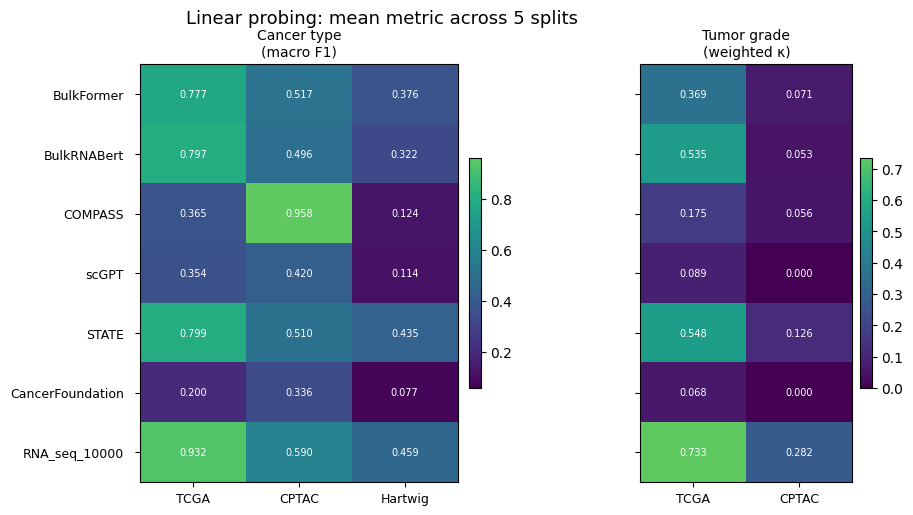

In [ ]:
TASKS_TO_PLOT = ["cancer_type", "grade"]
TASK_DATASETS = {
    "cancer_type": ["TCGA", "CPTAC", "Hartwig"],
    "grade": ["TCGA", "CPTAC"],
}

included_embs = [
    "BulkFormer",
    "BulkRNABert",
    "COMPASS",
    "scGPT",
    "STATE",
    "CancerFoundation",
    "RNA_seq_10000",
    #"RNA_seq_full",
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5.5),
    sharey=True,
    gridspec_kw={"width_ratios": [3, 2]}
)

axes = np.atleast_1d(axes)

for ax, task in zip(axes, TASKS_TO_PLOT):
    metric = TASK_METRIC[task] + "_mean"
    datasets_for_task = TASK_DATASETS[task]

    sub = lp_agg[
        (lp_agg["task"] == task) &
        (lp_agg["emb"].isin(included_embs)) &
        (lp_agg["dataset"].isin(datasets_for_task))
    ].copy()

    mat = (
        sub.pivot(index="emb", columns="dataset", values=metric)
        .reindex(index=included_embs, columns=datasets_for_task)
    )

    vals = mat.to_numpy(dtype=float)
    finite_vals = vals[np.isfinite(vals)]
    vmin = max(finite_vals.min() - 0.02, 0) if finite_vals.size else 0
    vmax = finite_vals.max() if finite_vals.size else 1

    colors = plt.cm.viridis(np.linspace(0.0, 0.75, 256))
    cmap = mcolors.LinearSegmentedColormap.from_list("viridis_dark", colors)

    im = ax.imshow(vals, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")

    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.iloc[i, j]
            if pd.notna(val):
                ax.text(
                    j, i, f"{val:.3f}",
                    ha="center", va="center",
                    fontsize=7, color="white"
                )

    ax.set_title(TASK_LABEL[task], fontsize=10)
    ax.set_xticks(range(len(datasets_for_task)))
    ax.set_xticklabels(datasets_for_task, fontsize=9)
    ax.set_yticks(range(len(included_embs)))

# Set y-axis labels only once, after the loop
axes[0].set_yticklabels(included_embs, fontsize=9)
axes[0].tick_params(axis="y", pad=8)

# Hide y tick labels on the second subplot without modifying the shared axis labels
axes[1].tick_params(axis="y", labelleft=False)

for ax in axes:
    fig.colorbar(ax.images[0], ax=ax, shrink=0.55, pad=0.03)

fig.subplots_adjust(left=0.28, right=0.97, top=0.88, bottom=0.12, wspace=0.35)
fig.suptitle("Linear probing: mean metric across 5 splits", fontsize=13)

plt.savefig(FIGURE_DIR / "linear_probing_heatmap_ct_grade.png", dpi=300)
plt.show()

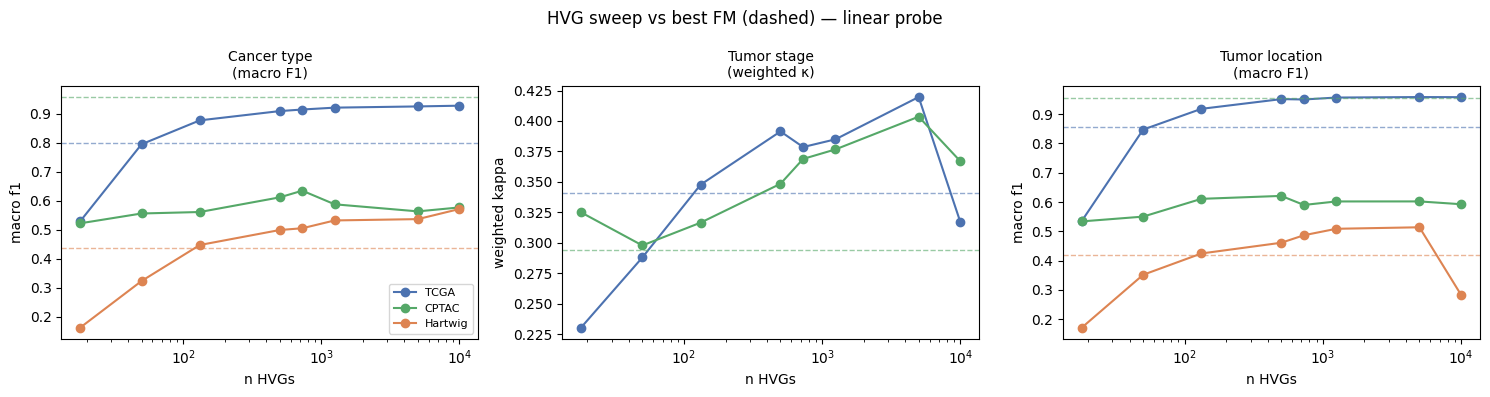

In [ ]:
# Useful for seeing how much information scales with HVG count
fig, axes = plt.subplots(1, len(TASKS), figsize=(15, 4), sharey=False)

hvg_counts = [18, 50, 132, 500, 729, 1250, 5000, 10000]
hvg_embs   = [f"RNA_seq_{n}" for n in hvg_counts]

for ax, task in zip(axes, TASKS):
    metric = TASK_METRIC[task] + "_mean"
    sub = lp_agg[lp_agg["task"] == task]

    for dataset in LP_DATASETS:
        dsub = sub[sub["dataset"] == dataset].set_index("emb")

        # HVG sweep line
        hvg_vals = [dsub.loc[e, metric] if e in dsub.index else np.nan for e in hvg_embs]
        ax.plot(hvg_counts, hvg_vals, marker="o", label=dataset,
                color=dataset_colors[dataset])

        # FM best as horizontal dashed line
        fm_best = dsub.loc[dsub.index.isin(FM_ALL), metric].max() if any(e in dsub.index for e in FM_ALL) else np.nan
        ax.axhline(fm_best, color=dataset_colors[dataset], linestyle="--", linewidth=1, alpha=0.6)

    ax.set_xscale("log")
    ax.set_xlabel("n HVGs")
    ax.set_title(TASK_LABEL[task], fontsize=10)
    ax.set_ylabel(TASK_METRIC[task].replace("_", " "))
    if ax is axes[0]:
        ax.legend(fontsize=8)

fig.suptitle("HVG sweep vs best FM (dashed) — linear probe", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "linear_probing_hvg_sweep.png", dpi=300, bbox_inches="tight")
plt.show()


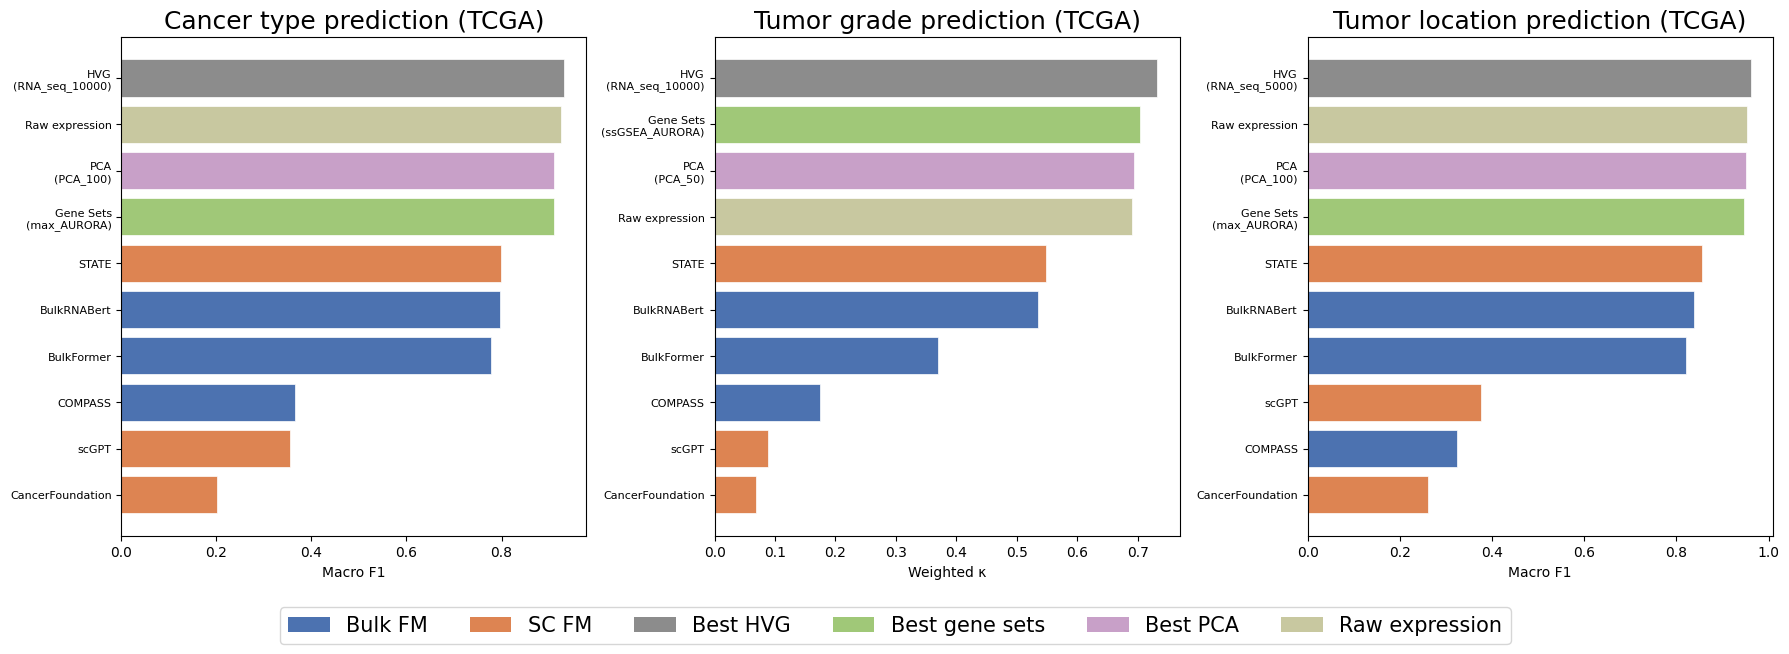

In [ ]:
BASELINE_GROUPS = {
    "HVG":            [e for e in EMB_ORDER if e.startswith("RNA_seq_") and e != "RNA_seq_full"],
    "Gene Sets":      [e for e in EMB_ORDER if e.startswith("ssGSEA_") or e.startswith("max_")],
    "PCA":            [e for e in EMB_ORDER if e.startswith("PCA_")],
    "Raw expression": ["RNA_seq_full"],
}

BAR_COLORS = {
    "BulkFormer":       "#4C72B0",
    "BulkRNABert":      "#4C72B0",
    "COMPASS":          "#4C72B0",
    "scGPT":            "#DD8452",
    "STATE":            "#DD8452",
    "CancerFoundation": "#DD8452",
    "HVG":              "#8C8C8C",
    "Gene Sets":        "#A0C878",
    "PCA":              "#C8A0C8",
    "Raw expression":   "#C8C8A0",
}

TASK_PRIMARY_METRIC = {
    "cancer_type": ("macro_f1_mean", "macro_f1_std", "Macro F1"),
    "grade":       ("weighted_kappa_mean", "weighted_kappa_std", "Weighted κ"),
    "organ":       ("macro_f1_mean", "macro_f1_std", "Macro F1"),
}
TASK_TITLE = {
    "cancer_type": "Cancer type prediction (TCGA)",
    "grade":       "Tumor grade prediction (TCGA)",
    "organ":       "Tumor location prediction (TCGA)",
}

tcga = lp_agg[lp_agg["dataset"] == "TCGA"].set_index("emb")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, task in zip(axes, TASKS):
    mean_col, std_col, ylabel = TASK_PRIMARY_METRIC[task]
    sub = tcga[tcga["task"] == task]

    entries = []

    # One bar per FM
    for emb in FM_ALL:
        if emb not in sub.index or not np.isfinite(sub.loc[emb, mean_col]):
            continue
        entries.append({
            "label": emb,
            "mean":  sub.loc[emb, mean_col],
            "std":   sub.loc[emb, std_col],
            "color": BAR_COLORS[emb],
        })

    # One bar per baseline group
    for group_label, group_embs in BASELINE_GROUPS.items():
        group_rows = sub.loc[sub.index.isin(group_embs), mean_col].dropna()
        if group_rows.empty:
            continue
        best_emb = group_rows.idxmax()
        # Show best embedding name beneath label, except for Raw expression
        if group_label == "Raw expression":
            display_label = group_label
        else:
            display_label = f"{group_label}\n({best_emb})"
        entries.append({
            "label": display_label,
            "mean":  sub.loc[best_emb, mean_col],
            "std":   sub.loc[best_emb, std_col],
            "color": BAR_COLORS[group_label],
        })

    entries = sorted(entries, key=lambda e: e["mean"], reverse=True)

    labels = [e["label"] for e in entries]
    means  = [e["mean"]  for e in entries]
    stds   = [e["std"]   for e in entries]
    colors = [e["color"] for e in entries]

    ax.barh(range(len(entries)), means,
            color=colors, edgecolor="white", linewidth=0.5,
            error_kw=dict(elinewidth=1, capsize=3, ecolor="black"))

    ax.set_yticks(range(len(entries)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel(ylabel, fontsize=10)
    ax.set_title(TASK_TITLE[task], fontsize=18)
    ax.axvline(0, color="black", linewidth=0.5)
    '''
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(m + s + 0.005, i, f"{m:.3f}", va="center", fontsize=7)
    '''
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", label="Bulk FM"),
    Patch(facecolor="#DD8452", label="SC FM"),
    Patch(facecolor="#8C8C8C", label="Best HVG"),
    Patch(facecolor="#A0C878", label="Best gene sets"),
    Patch(facecolor="#C8A0C8", label="Best PCA"),
    Patch(facecolor="#C8C8A0", label="Raw expression"),
]
fig.legend(handles=legend_elements, loc="lower center", ncol=6,
           fontsize=15, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig(FIGURE_DIR / "linear_probing_tcga_bars.png", dpi=300, bbox_inches="tight")
plt.show()

### UMAP Visualizations

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
import umap
from sklearn.preprocessing import StandardScaler

BASE = "/data/rbg/users/ashyamal/RNA-FM-benchmarking"

with open(f"{BASE}/data/RNA_embeddings/TCGA_processed_cleaned.pkl", "rb") as f:
    data = pickle.load(f)

In [ ]:
BAD_VALUES = {"unknown", "not reported", "'--", "not applicable", "n/a", "na",
              "none", "", "nan/null", "--"}

def clean_val(x):
    if pd.isnull(x): return np.nan
    return np.nan if str(x).strip().lower() in BAD_VALUES else x

stage_map = {
    'Stage 0': 0, 'Stage 0a': 0, 'Stage 0is': 0, 'Stage IS': 0,
    'Stage I': 1, 'Stage IA': 1, 'Stage IB': 1, 'Stage IB1': 1, 'Stage IC': 1,
    'Stage II': 2, 'Stage IIA': 2, 'Stage IIB': 2, 'Stage IIC': 2,
    'Stage III': 3, 'Stage IIIA': 3, 'Stage IIIB': 3, 'Stage IIIC': 3,
    'Stage IV': 4, 'Stage IVA': 4, 'Stage IVB': 4, 'Stage IVC': 4,
}

grade_order = ["G1", "Low Grade", "G2", "GB", "G3", "High Grade", "G4", "GX"]
grade_colors = {
    "G1":         "#2166ac",
    "Low Grade":  "#74add1",
    "G2":         "#abd9e9",
    "GB":         "#ffffbf",
    "G3":         "#fdae61",
    "High Grade": "#f46d43",
    "G4":         "#d73027",
    "GX":         "#cccccc",
}

clinical = pd.read_csv(f"{REPO_DIR}/data/TCGA/clinical/clinical.tsv", sep="\t",
                       dtype=str, low_memory=False)
clinical = clinical.drop_duplicates(subset="cases.submitter_id").set_index("cases.submitter_id")

pids = [p for p in data if data[p].get("PFS_time") is not None]

def get_val(pid, col):
    if pid not in clinical.index: return np.nan
    return clean_val(clinical.loc[pid, col])

meta = pd.DataFrame({
    "cancer_type": [data[p]["cancer_type"] for p in pids],
    "PFS_time":    [float(data[p]["PFS_time"])  for p in pids],
    "PFS_event":   [float(data[p]["PFS_event"]) for p in pids],
    "stage":       [stage_map.get(get_val(p, "diagnoses.ajcc_pathologic_stage"), np.nan) for p in pids],
    "grade":       [get_val(p, "diagnoses.tumor_grade") for p in pids],
    "age":         [float(get_val(p, "demographic.age_at_index"))
                    if pd.notna(get_val(p, "demographic.age_at_index")) else np.nan
                    for p in pids],
}, index=pids)
meta["log_PFS_time"] = np.log1p(meta["PFS_time"])

print(f"Samples: {len(pids)}")
print(f"Stage:   {meta['stage'].notna().sum()} / {len(meta)}")
print(f"Grade:   {meta['grade'].notna().sum()} / {len(meta)}")
print(f"Age:     {meta['age'].notna().sum()} / {len(meta)}")
print(meta["grade"].value_counts())


Samples: 10388
Stage:   5302 / 10388
Grade:   3397 / 10388
Age:     10365 / 10388
grade
G3            1443
G2            1275
G1             265
High Grade     231
GX              89
G4              74
Low Grade       18
GB               2
Name: count, dtype: int64


In [ ]:
EMBEDDING_CONFIGS = {
    "BulkFormer":  lambda r: np.asarray(r["BulkFormer"]).squeeze(),
    "BulkRNABert": lambda r: np.asarray(r["BulkRNABert"]).squeeze(),
    "STATE-SE":    lambda r: np.asarray(r["STATE"]).squeeze(),
    "HVG (10k)":   lambda r: np.asarray(r["RNA_seq"])[:10000],
}

umaps = {}
for name, getter in EMBEDDING_CONFIGS.items():
    X = np.stack([getter(data[p]) for p in pids]).astype(np.float32)
    X = StandardScaler().fit_transform(X)
    reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.3,
                        random_state=42, low_memory=False, n_jobs=8)
    umaps[name] = reducer.fit_transform(X)
    print(f"  {name}: done  shape={umaps[name].shape}")

/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  BulkFormer: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  BulkRNABert: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  STATE-SE: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  HVG (10k): done  shape=(10388, 2)


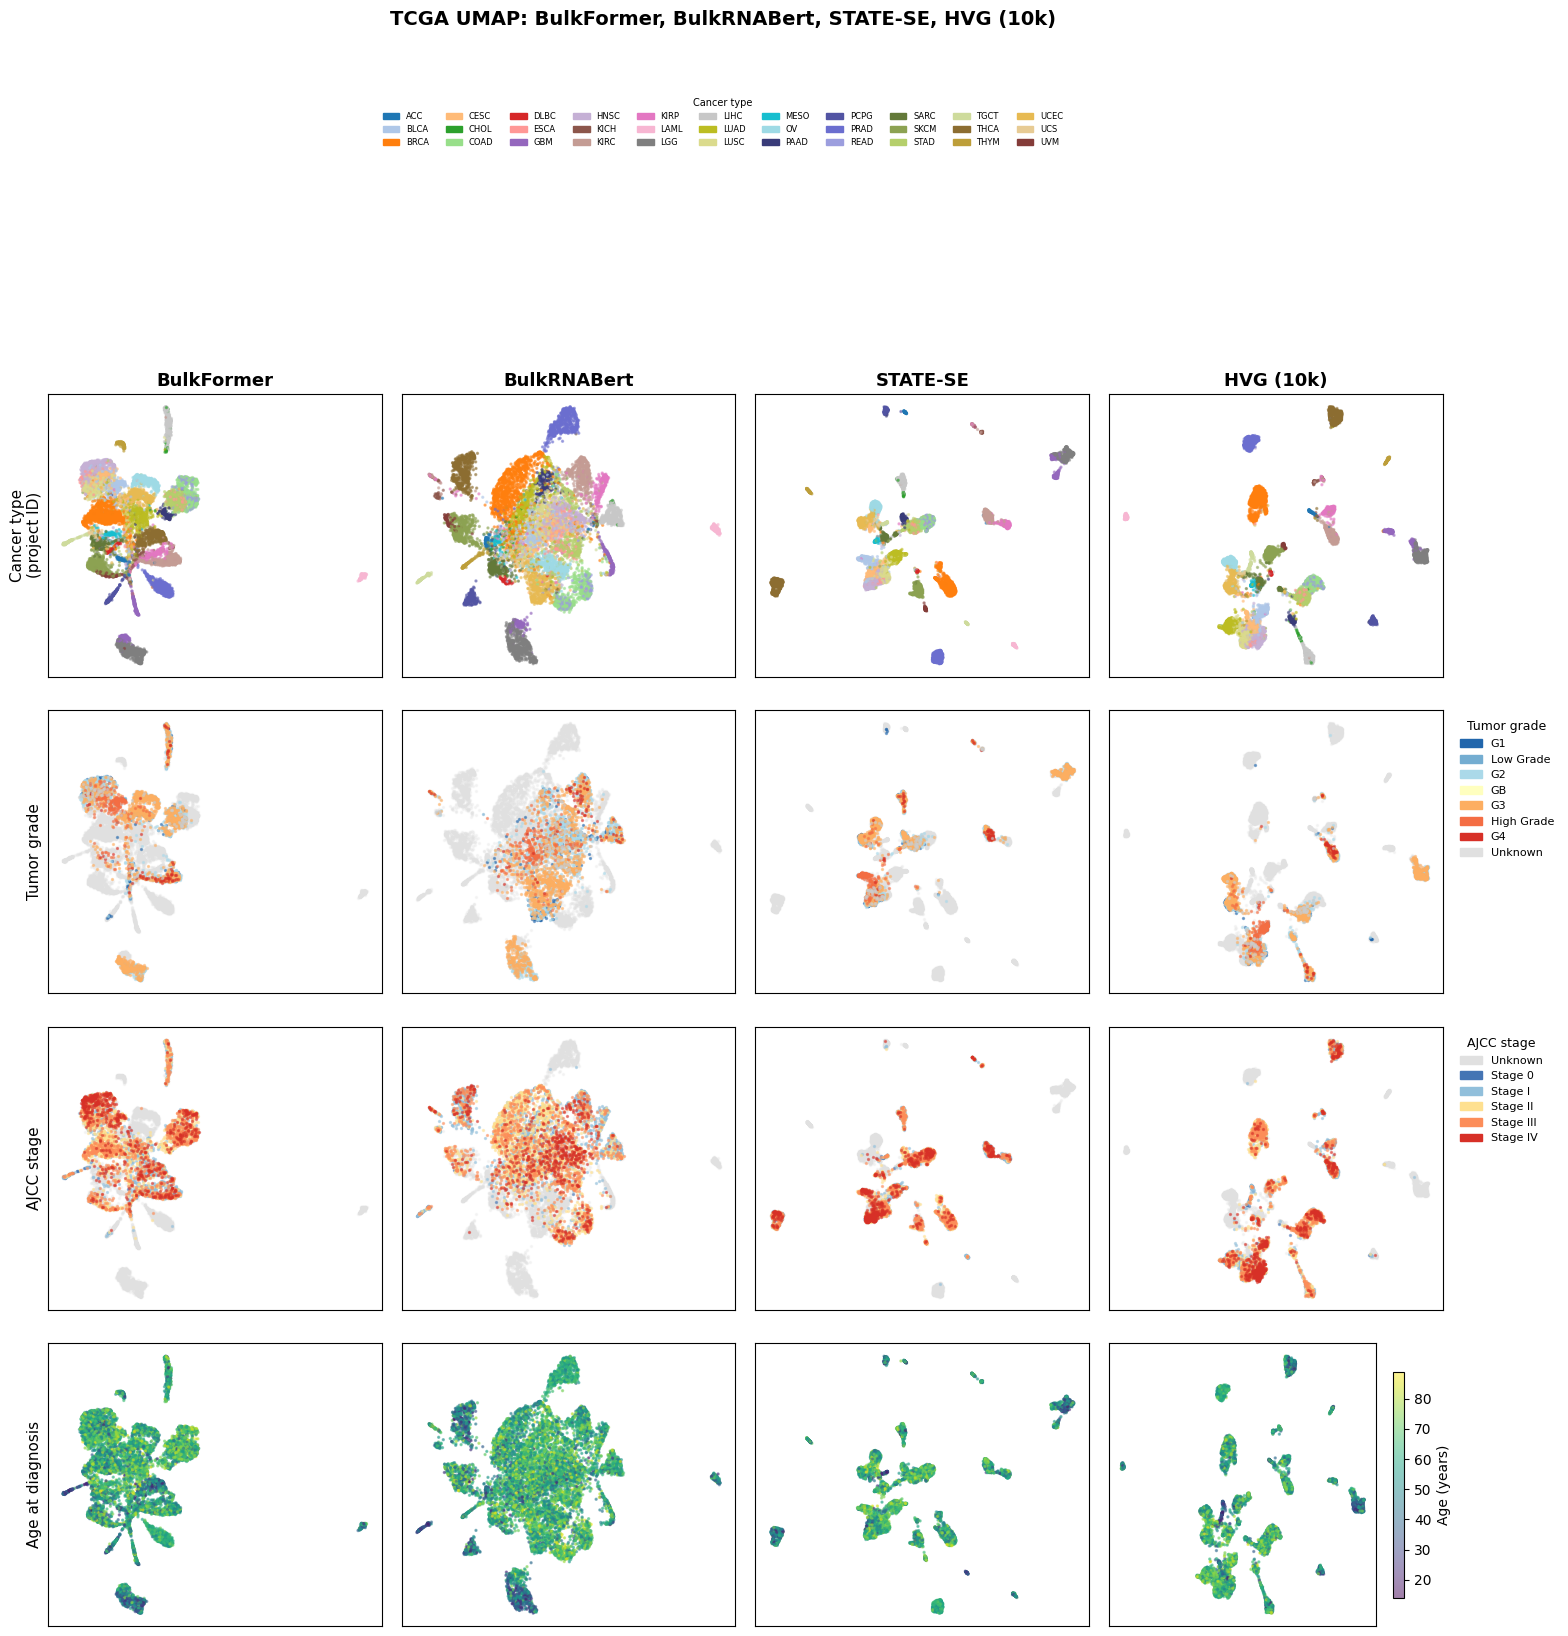

In [ ]:
EMBED_NAMES = list(EMBEDDING_CONFIGS.keys())
n_models = len(EMBED_NAMES)
s, alpha = 2, 0.5

# ── palettes ──────────────────────────────────────────────────────────────────
ct_cats    = sorted(meta["cancer_type"].unique())
all_colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
ct_palette = {c: all_colors[i % 40] for i, c in enumerate(ct_cats)}

stage_colors = {0: "#4575b4", 1: "#91bfdb", 2: "#fee090", 3: "#fc8d59", 4: "#d73027"}
stage_labels = {0: "Stage 0", 1: "Stage I", 2: "Stage II", 3: "Stage III", 4: "Stage IV"}

row_labels = ["Cancer type\n(project ID)", "Tumor grade", "AJCC stage", "Age at diagnosis"]

fig, axes = plt.subplots(4, n_models, figsize=(n_models * 4.5, 16),
                         gridspec_kw={"hspace": 0.12, "wspace": 0.06})

for col, name in enumerate(EMBED_NAMES):
    xy = umaps[name]
    axes[0, col].set_title(name, fontsize=13, fontweight="bold", pad=6)

    # ── row 0: cancer type ────────────────────────────────────────────────────
    ax = axes[0, col]
    ax.scatter(xy[:, 0], xy[:, 1],
               c=[ct_palette[c] for c in meta["cancer_type"]],
               s=s, alpha=alpha, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    if col == 0: ax.set_ylabel(row_labels[0], fontsize=11)

    # ── row 1: tumor grade ────────────────────────────────────────────────────
    ax = axes[1, col]
    no_grade = meta["grade"].isna()
    ax.scatter(xy[no_grade, 0], xy[no_grade, 1],
               c="#e0e0e0", s=s, alpha=0.25, rasterized=True)
    for g in grade_order:
        mask = meta["grade"] == g
        if mask.any():
            ax.scatter(xy[mask, 0], xy[mask, 1],
                       c=grade_colors[g], s=s, alpha=alpha, rasterized=True, label=g)
    ax.set_xticks([]); ax.set_yticks([])
    if col == 0: ax.set_ylabel(row_labels[1], fontsize=11)

    # ── row 2: AJCC stage ─────────────────────────────────────────────────────
    ax = axes[2, col]
    no_stage = meta["stage"].isna()
    ax.scatter(xy[no_stage, 0], xy[no_stage, 1],
               c="#e0e0e0", s=s, alpha=0.25, rasterized=True)
    for stg in [0, 1, 2, 3, 4]:
        mask = meta["stage"] == stg
        if mask.any():
            ax.scatter(xy[mask, 0], xy[mask, 1],
                       c=stage_colors[stg], s=s, alpha=alpha, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    if col == 0: ax.set_ylabel(row_labels[2], fontsize=11)

    # ── row 3: age (continuous) ───────────────────────────────────────────────
    ax = axes[3, col]
    no_age = meta["age"].isna()
    ax.scatter(xy[no_age, 0], xy[no_age, 1],
               c="#e0e0e0", s=s, alpha=0.25, rasterized=True)
    has_age = ~no_age
    norm_age = Normalize(vmin=meta["age"].min(), vmax=meta["age"].max())
    sc = ax.scatter(xy[has_age, 0], xy[has_age, 1],
                    c=meta.loc[has_age, "age"], cmap="viridis",
                    norm=norm_age, s=s, alpha=alpha, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    if col == 0: ax.set_ylabel(row_labels[3], fontsize=11)
    if col == n_models - 1:
        fig.colorbar(sc, ax=ax, shrink=0.8, label="Age (years)")

# ── legends ───────────────────────────────────────────────────────────────────
# Cancer type legend — horizontal, above the figure
ct_handles = [mpatches.Patch(color=ct_palette[c], label=c) for c in ct_cats]
fig.legend(handles=ct_handles, loc="upper center", bbox_to_anchor=(0.5, 1.07),
           fontsize=6, ncol=len(ct_cats)//3, frameon=False,
           title="Cancer type", title_fontsize=7)

# Tumor grade legend
grade_handles = [mpatches.Patch(color=grade_colors[g], label=g) for g in grade_order
                 if g != "GX"] + [mpatches.Patch(color="#e0e0e0", label="Unknown")]
axes[1, -1].legend(handles=grade_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                   fontsize=8, frameon=False, title="Tumor grade", title_fontsize=9)

# Stage legend
stage_handles = ([mpatches.Patch(color="#e0e0e0", label="Unknown")]
                 + [mpatches.Patch(color=stage_colors[s], label=stage_labels[s]) for s in range(5)])
axes[2, -1].legend(handles=stage_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                   fontsize=8, frameon=False, title="AJCC stage", title_fontsize=9)

plt.suptitle("TCGA UMAP: BulkFormer, BulkRNABert, STATE-SE, HVG (10k)",
             fontsize=14, fontweight="bold", y=1.12)
plt.savefig(FIGURE_DIR / "TCGA_UMAP_clinical_features.pdf", dpi=150, bbox_inches="tight")
plt.show()


### Examine Gene Importance

In [ ]:
import pickle
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib_venn import venn2

# ── Config ─────────────────────────────────────────────────────────────────────
REPO = "/data/rbg/users/ashyamal/RNA-FM-benchmarking"
WEIGHTS_PATH = f"{REPO}/analysis/linear_gene_weights.pkl"

H5AD_PATHS = {
    "TCGA":       f"{REPO}/data/TCGA/RNA/TCGA_bulk_RNA_processed_log1p.h5ad",
    "Hartwig":    f"{REPO}/data/Hartwig/RNA/Hartwig_bulk_RNA_processed_log1p.h5ad",
    "CPTAC":      f"{REPO}/data/CPTAC/RNA/CPTAC_bulk_RNA_processed_log1p.h5ad",
    "TARGET_AML": f"{REPO}/data/TARGET_AML/RNA/TARGET_AML_bulk_RNA_processed_log1p.h5ad",
}

TOP_N = 30  # for bar plots

# ── Load data ──────────────────────────────────────────────────────────────────
with open(WEIGHTS_PATH, "rb") as f:
    all_weights = pickle.load(f)

# Build per-dataset variance lookup: gene_symbol -> log_variance
variance_lookup = {}
for ds, path in H5AD_PATHS.items():
    adata = sc.read_h5ad(path)
    var_df = adata.var[["gene_symbol", "log_variance"]].copy()
    var_df = var_df.set_index("gene_symbol")["log_variance"]
    variance_lookup[ds] = var_df

# Build merged DataFrames: one per (dataset, config)
dfs = {}
for ds, configs in all_weights.items():
    for config, gene_dict in configs.items():
        df = pd.DataFrame({"gene": list(gene_dict.keys()), "weight": list(gene_dict.values())})
        df["abs_weight"] = df["weight"].abs()
        df["direction"] = df["weight"].apply(lambda w: "risk" if w > 0 else "protective")
        df = df.merge(
            variance_lookup[ds].rename("log_variance"),
            left_on="gene", right_index=True, how="left"
        )
        dfs[(ds, config)] = df

print("Datasets/configs loaded:")
for (ds, cfg), df in dfs.items():
    print(f"  {ds}/{cfg}: {len(df)} genes, {df['log_variance'].notna().sum()} with variance info")

Datasets/configs loaded:
  TCGA/raw_expression: 17927 genes, 17927 with variance info
  TCGA/HVG_10000: 10000 genes, 10000 with variance info
  Hartwig/raw_expression: 18005 genes, 18005 with variance info
  Hartwig/HVG_5000: 5000 genes, 5000 with variance info
  CPTAC/raw_expression: 18775 genes, 18775 with variance info
  CPTAC/HVG_1250: 1250 genes, 1250 with variance info
  TARGET_AML/raw_expression: 16671 genes, 16671 with variance info
  TARGET_AML/HVG_1250: 1250 genes, 1250 with variance info


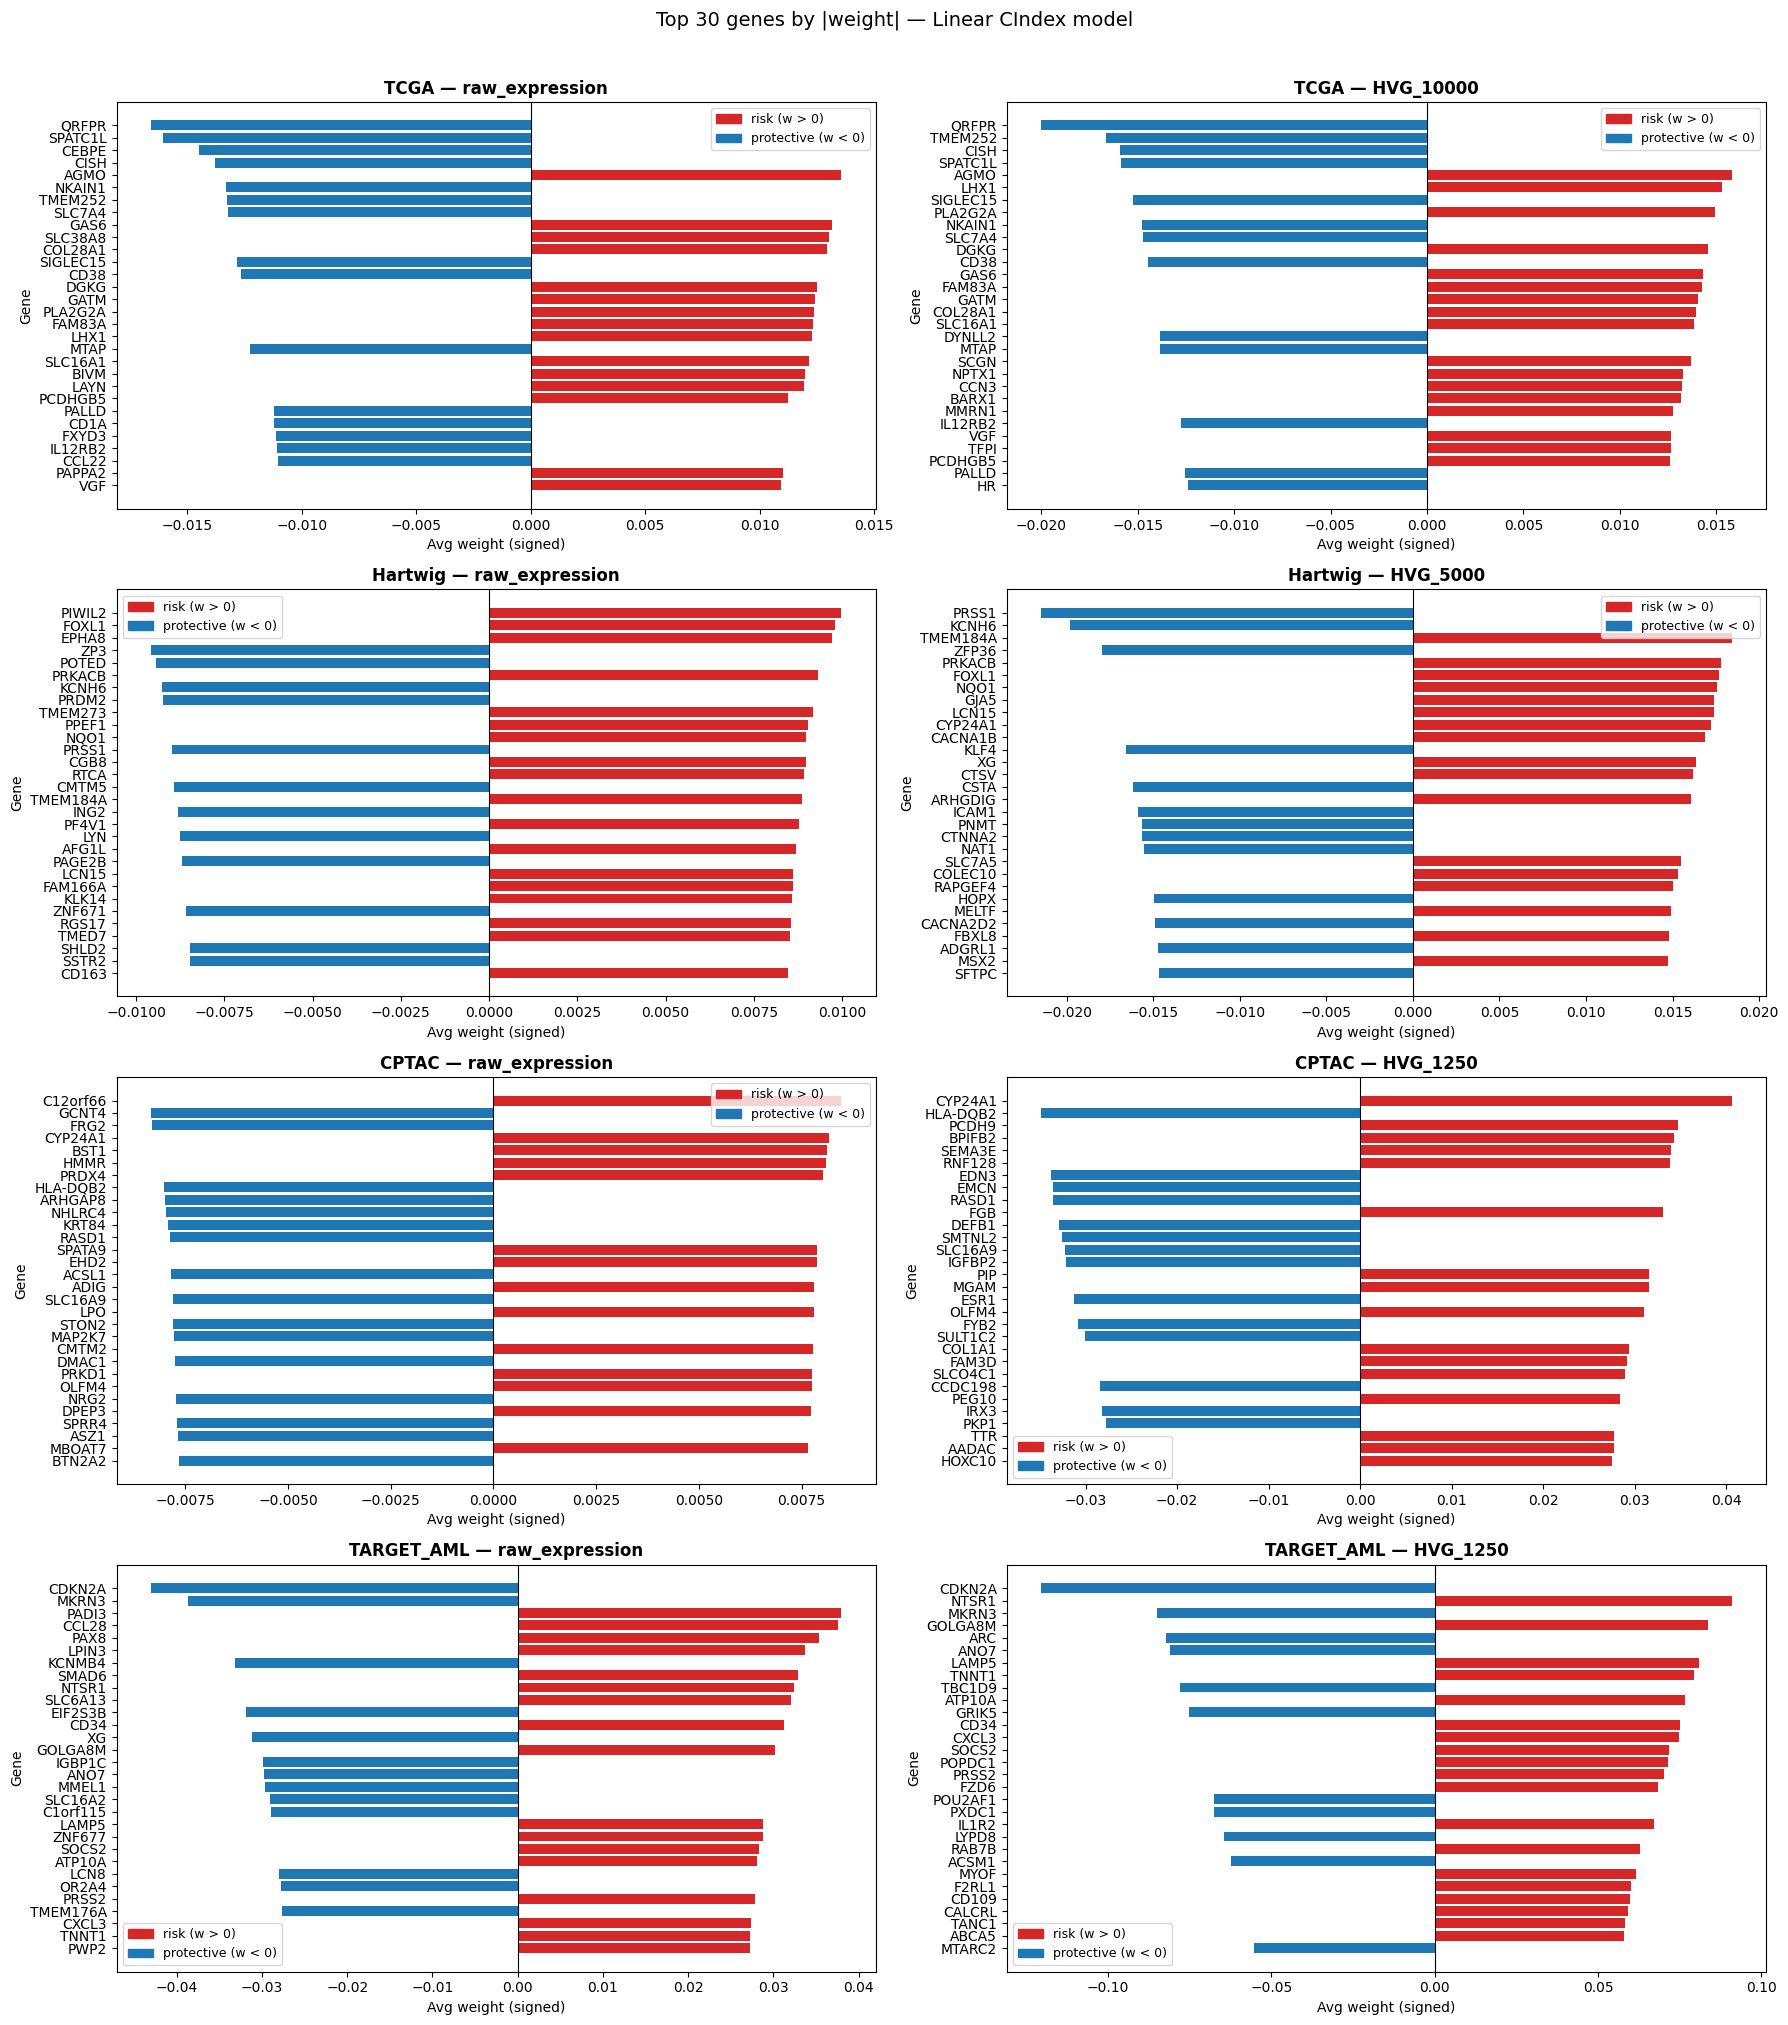

In [ ]:
# ── Plot 1: Top-N gene weight barplots (one panel per dataset, raw vs HVG side by side)
# ───────────────────────────────────────────────────────────────────────────────
datasets = list(all_weights.keys())
fig, axes = plt.subplots(len(datasets), 2, figsize=(18, 5 * len(datasets)))

for row, ds in enumerate(datasets):
    configs = list(all_weights[ds].keys())  # ["raw_expression", "HVG_XXXX"]
    for col, config in enumerate(configs):
        ax = axes[row, col]
        df = dfs[(ds, config)].head(TOP_N).copy()
        colors = ["#d62728" if d == "risk" else "#1f77b4" for d in df["direction"]]
        ax.barh(df["gene"][::-1], df["weight"][::-1], color=colors[::-1])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(f"{ds} — {config}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Avg weight (signed)")
        ax.set_ylabel("Gene")
        # legend
        from matplotlib.patches import Patch
        ax.legend(handles=[
            Patch(color="#d62728", label="risk (w > 0)"),
            Patch(color="#1f77b4", label="protective (w < 0)"),
        ], fontsize=9)

plt.suptitle(f"Top {TOP_N} genes by |weight| — Linear CIndex model", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

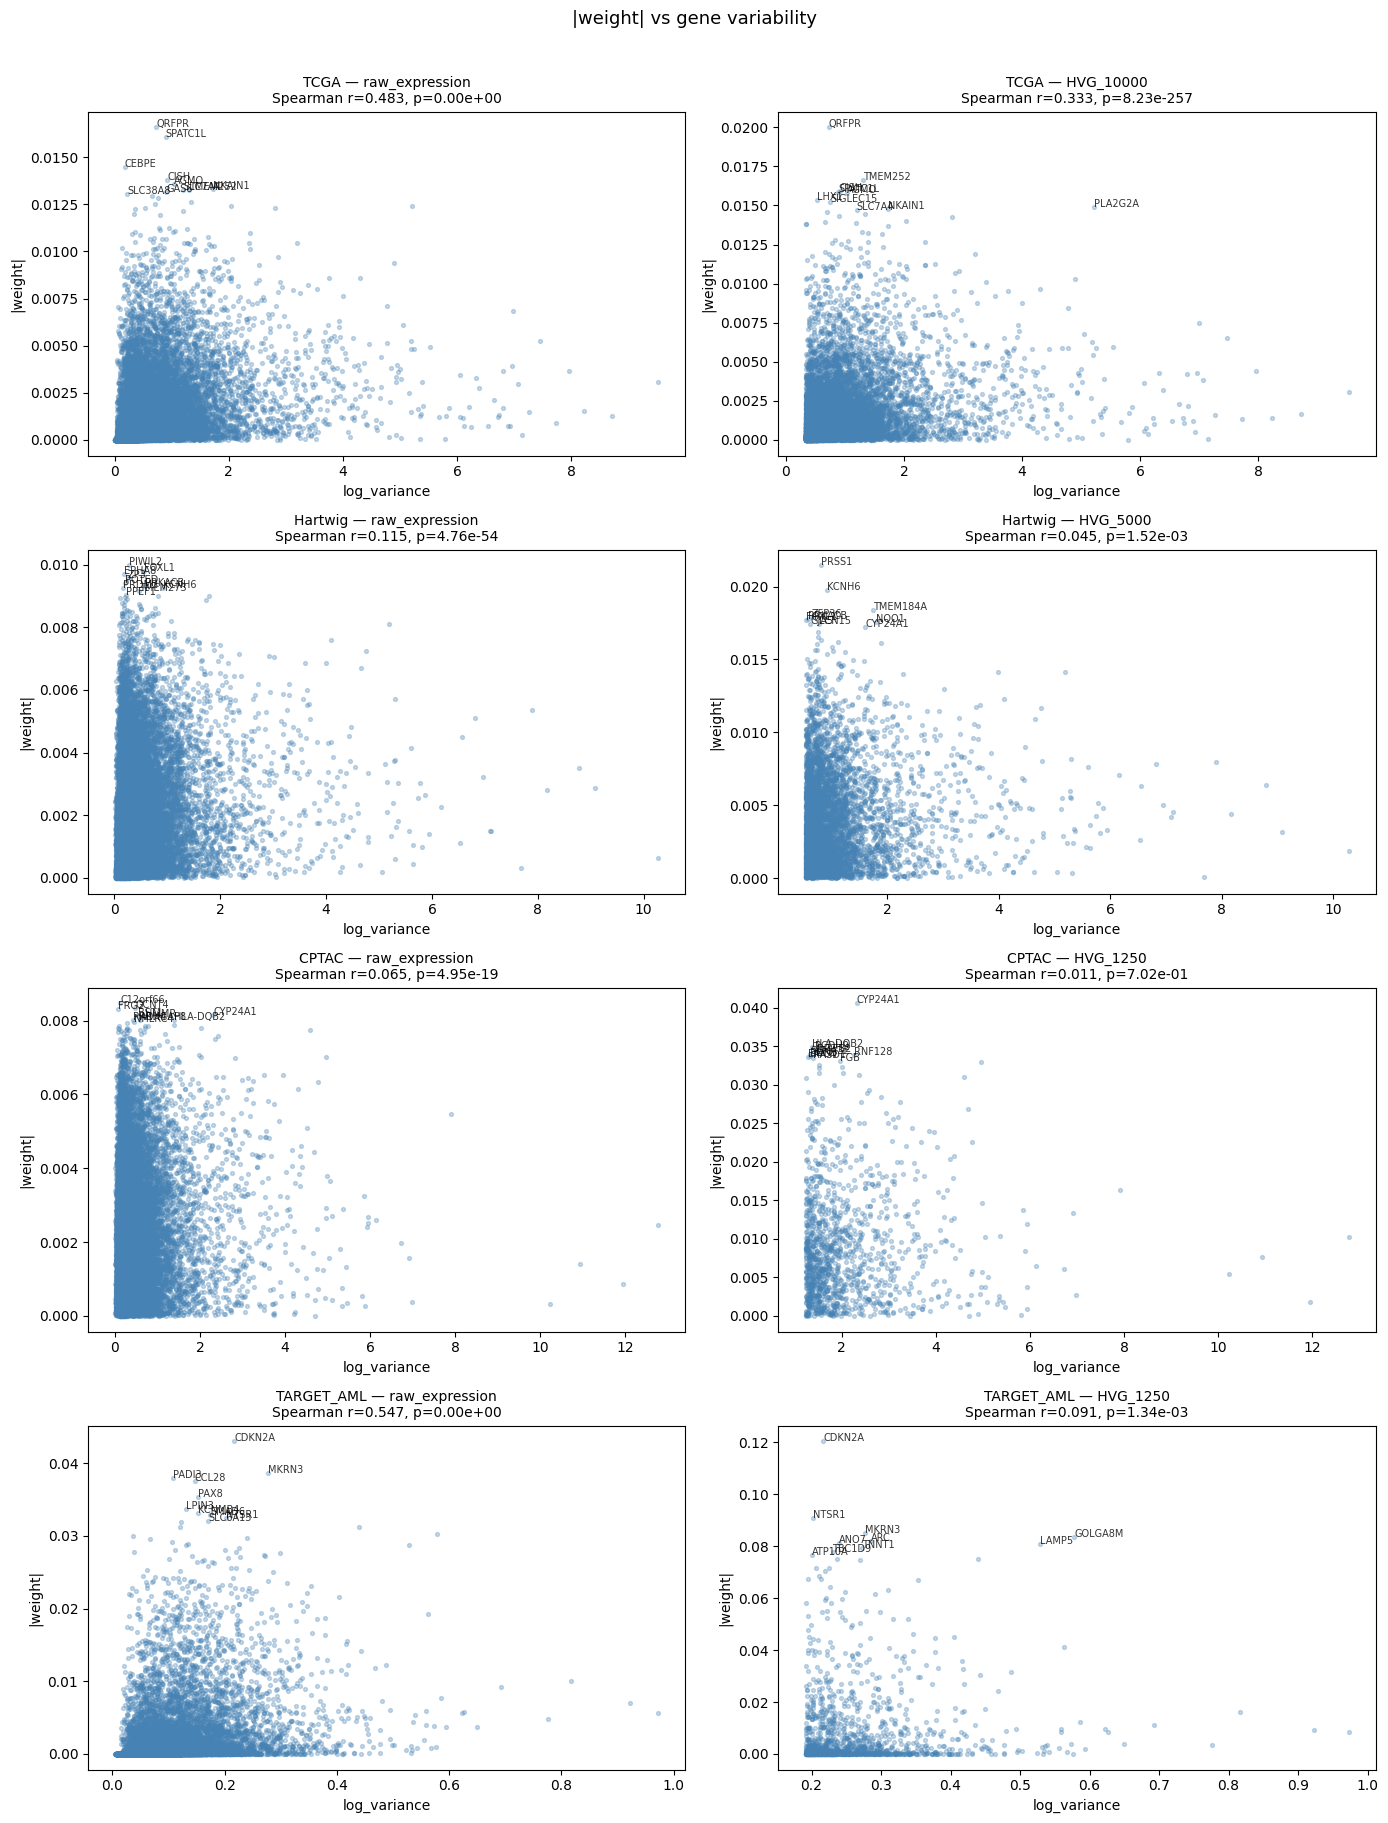

In [ ]:
# ── Plot 2: |weight| vs log_variance scatter (with Spearman correlation)
# ───────────────────────────────────────────────────────────────────────────────
from scipy.stats import spearmanr

fig, axes = plt.subplots(len(datasets), 2, figsize=(14, 4.5 * len(datasets)))

for row, ds in enumerate(datasets):
    configs = list(all_weights[ds].keys())
    for col, config in enumerate(configs):
        ax = axes[row, col]
        df = dfs[(ds, config)].dropna(subset=["log_variance"])

        r, p = spearmanr(df["abs_weight"], df["log_variance"])

        ax.scatter(df["log_variance"], df["abs_weight"], alpha=0.3, s=8, color="steelblue")

        # Annotate top genes
        top = df.nlargest(10, "abs_weight")
        for _, row_ in top.iterrows():
            ax.annotate(row_["gene"], (row_["log_variance"], row_["abs_weight"]),
                        fontsize=7, alpha=0.8)

        ax.set_title(f"{ds} — {config}\nSpearman r={r:.3f}, p={p:.2e}", fontsize=10)
        ax.set_xlabel("log_variance")
        ax.set_ylabel("|weight|")

plt.suptitle("|weight| vs gene variability", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

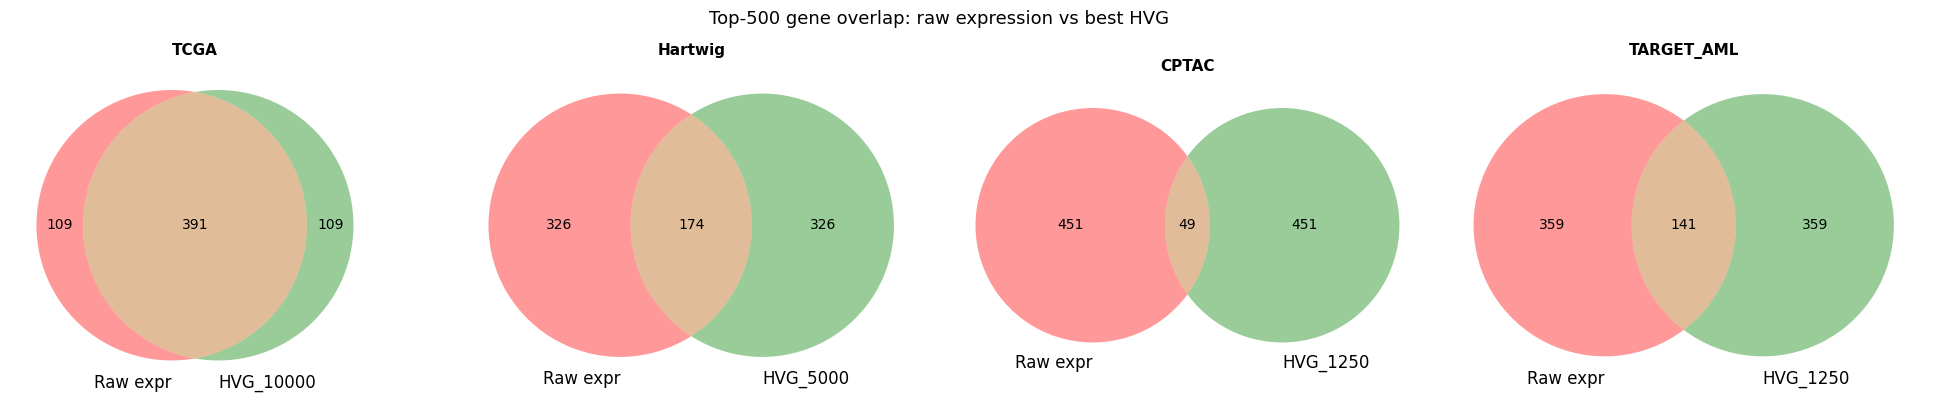

In [ ]:
# ── Plot 3: Overlap of top genes between raw_expression and best HVG (per dataset)
# ───────────────────────────────────────────────────────────────────────────────
TOP_OVERLAP = 500  # compare top-N for overlap

fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 4))

for ax, ds in zip(axes, datasets):
    configs = list(all_weights[ds].keys())
    raw_cfg = [c for c in configs if "raw" in c][0]
    hvg_cfg = [c for c in configs if "HVG" in c][0]

    raw_top = set(dfs[(ds, raw_cfg)].nlargest(TOP_OVERLAP, "abs_weight")["gene"])
    hvg_top = set(dfs[(ds, hvg_cfg)].nlargest(TOP_OVERLAP, "abs_weight")["gene"])

    try:
        venn2([raw_top, hvg_top], set_labels=("Raw expr", hvg_cfg), ax=ax)
    except Exception:
        # fallback if matplotlib_venn not installed
        overlap = len(raw_top & hvg_top)
        ax.text(0.5, 0.5, f"Overlap: {overlap}/{TOP_OVERLAP}", ha="center", va="center", fontsize=12)
        ax.set_axis_off()

    ax.set_title(f"{ds}", fontsize=11, fontweight="bold")

plt.suptitle(f"Top-{TOP_OVERLAP} gene overlap: raw expression vs best HVG", fontsize=13)
plt.tight_layout()
plt.show()

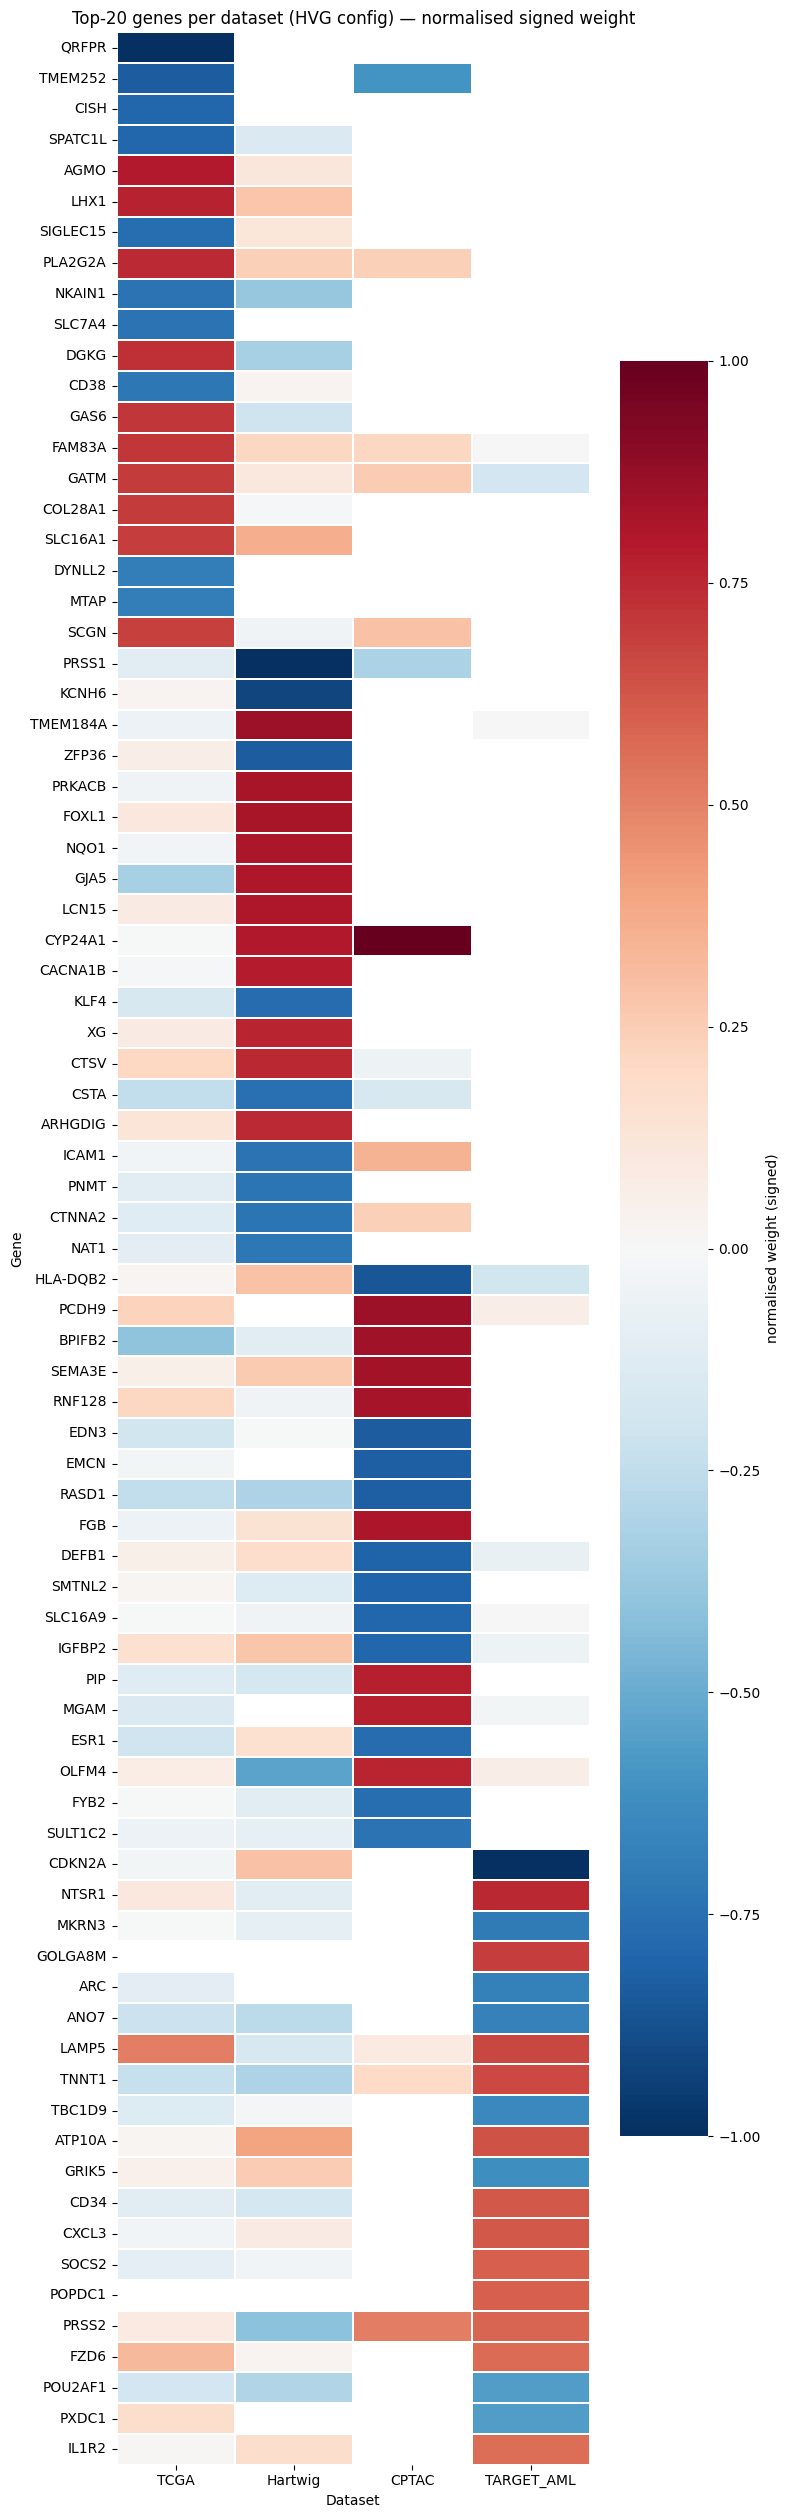

In [ ]:
# ── Plot 4: Cross-dataset gene importance heatmap (top genes from each dataset)
# ───────────────────────────────────────────────────────────────────────────────
# For each dataset use the HVG config; normalise |weights| to [0,1] within dataset
# so magnitudes are comparable. Show top-20 genes per dataset union.

TOP_PER_DS = 20
config_key = lambda ds: [c for c in all_weights[ds] if "HVG" in c][0]

gene_union = []
for ds in datasets:
    cfg = config_key(ds)
    top = dfs[(ds, cfg)].nlargest(TOP_PER_DS, "abs_weight")["gene"].tolist()
    gene_union.extend(top)
gene_union = list(dict.fromkeys(gene_union))  # deduplicated, order preserved

heatmap_data = {}
for ds in datasets:
    cfg = config_key(ds)
    df = dfs[(ds, cfg)].set_index("gene")
    # Normalised signed weight: w / max(|w|) so range is [-1, 1]
    max_abs = df["abs_weight"].max()
    heatmap_data[ds] = df["weight"].reindex(gene_union) / max_abs

heatmap_df = pd.DataFrame(heatmap_data, index=gene_union)

fig, ax = plt.subplots(figsize=(8, max(6, len(gene_union) * 0.32)))
sns.heatmap(
    heatmap_df,
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.3,
    ax=ax,
    cbar_kws={"label": "normalised weight (signed)"},
)
ax.set_title(f"Top-{TOP_PER_DS} genes per dataset (HVG config) — normalised signed weight", fontsize=12)
ax.set_xlabel("Dataset")
ax.set_ylabel("Gene")
plt.tight_layout()
plt.show()

### Binning

In [ ]:
# ── Binning ablation config ────────────────────────────────────────────────
# Fixed model config used in the binning experiment
BINNED_ARCH = "ResidualMLP"
BINNED_LOSS = "CIndex"
BINNED_SEED = 37

BEST_NHVGS = {"TCGA": 10000, "Hartwig": 5000, "CPTAC": 1250, "TARGET_AML": 1250}

N_BINS_ORDER = [2, 8, 16, 32, 51, 64, 128, 256, 512, 1024]

STRATEGY_STYLE = {
    "linear":              dict(color="#2ca02c", marker="o", ls="-",  label="Per-gene linear"),
    "quantile":            dict(color="#98df8a", marker="o", ls="-",  label="Per-gene quantile"),
    "global_linear":       dict(color="#1f77b4", marker="o", ls="-",  label="Global linear"),
    "global_quantile":     dict(color="#aec7e8", marker="o", ls="-",  label="Global quantile"),
    "per_sample_linear":   dict(color="#d62728", marker="o", ls="-",  label="Per-sample linear"),
    "per_sample_quantile": dict(color="#ff9896", marker="o", ls="-",  label="Per-sample quantile"),
}

In [ ]:
# ── Load binned CSVs ───────────────────────────────────────────────────────
binned_dfs = []
for ds in DATASETS:
    path = BASE / ds / "survival" / "PFS" / "binned_HVG_ablation" / "binned_HVG_metrics.csv"
    df = pd.read_csv(path)
    df["dataset"] = ds
    binned_dfs.append(df)
binned = pd.concat(binned_dfs, ignore_index=True)
binned = binned[binned["error"].isna() | (binned["error"] == "")]

# Keep only the fixed config used in this experiment
binned = binned[
    (binned["arch"] == BINNED_ARCH) &
    (binned["loss"] == BINNED_LOSS) &
    (binned["seed"] == BINNED_SEED)
]
binned = binned[binned.apply(lambda r: r["n_hvgs"] == BEST_NHVGS[r["dataset"]], axis=1)]

# Average over splits
binned_agg = (
    binned
    .groupby(["dataset", "bin_strategy", "n_bins"])["overall"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)

print(binned_agg.groupby(["dataset", "bin_strategy"])["n_bins"].count())
print(binned_agg.head(10).to_string(index=False))


dataset     bin_strategy       
CPTAC       global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
Hartwig     global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
TARGET_AML  global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
TCGA        global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
Name: n_bins, dtype: int64
dataset  bin_strategy  n_bins

In [ ]:
# ── Continuous HVG baseline: best arch/loss per dataset ───────────────────
# Uses the val-selected agg_filtered CSVs from the main benchmarking experiment
hvg_dfs = []
for ds in DATASETS:
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{ds}_survival_PFS_agg_filtered.csv")
    df["nHVGs"] = df["nHVGs"].fillna("None").astype(str)
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    hvg = df[
        (df["RNA_key"] == "RNA_seq") &
        (df["nHVGs"] == str(float(BEST_NHVGS[ds])))
    ].copy()
    hvg["dataset"] = ds
    hvg_dfs.append(hvg)

hvg_df = pd.concat(hvg_dfs, ignore_index=True)
hvg_filtered = hvg_df[hvg_df["arch"] == BINNED_ARCH]
hvg_best = (
    hvg_filtered
    .loc[hvg_filtered.groupby("dataset")["overall_mean"].idxmax()]
    .set_index("dataset")
)
print(hvg_best[["arch", "loss", "overall_mean", "overall_std"]].to_string())


                   arch    loss  overall_mean  overall_std
dataset                                                   
CPTAC       ResidualMLP     Cox      0.734626     0.030173
Hartwig     ResidualMLP  CIndex      0.606880     0.020888
TARGET_AML  ResidualMLP     Cox      0.683158     0.010854
TCGA        ResidualMLP  CIndex      0.741761     0.010647


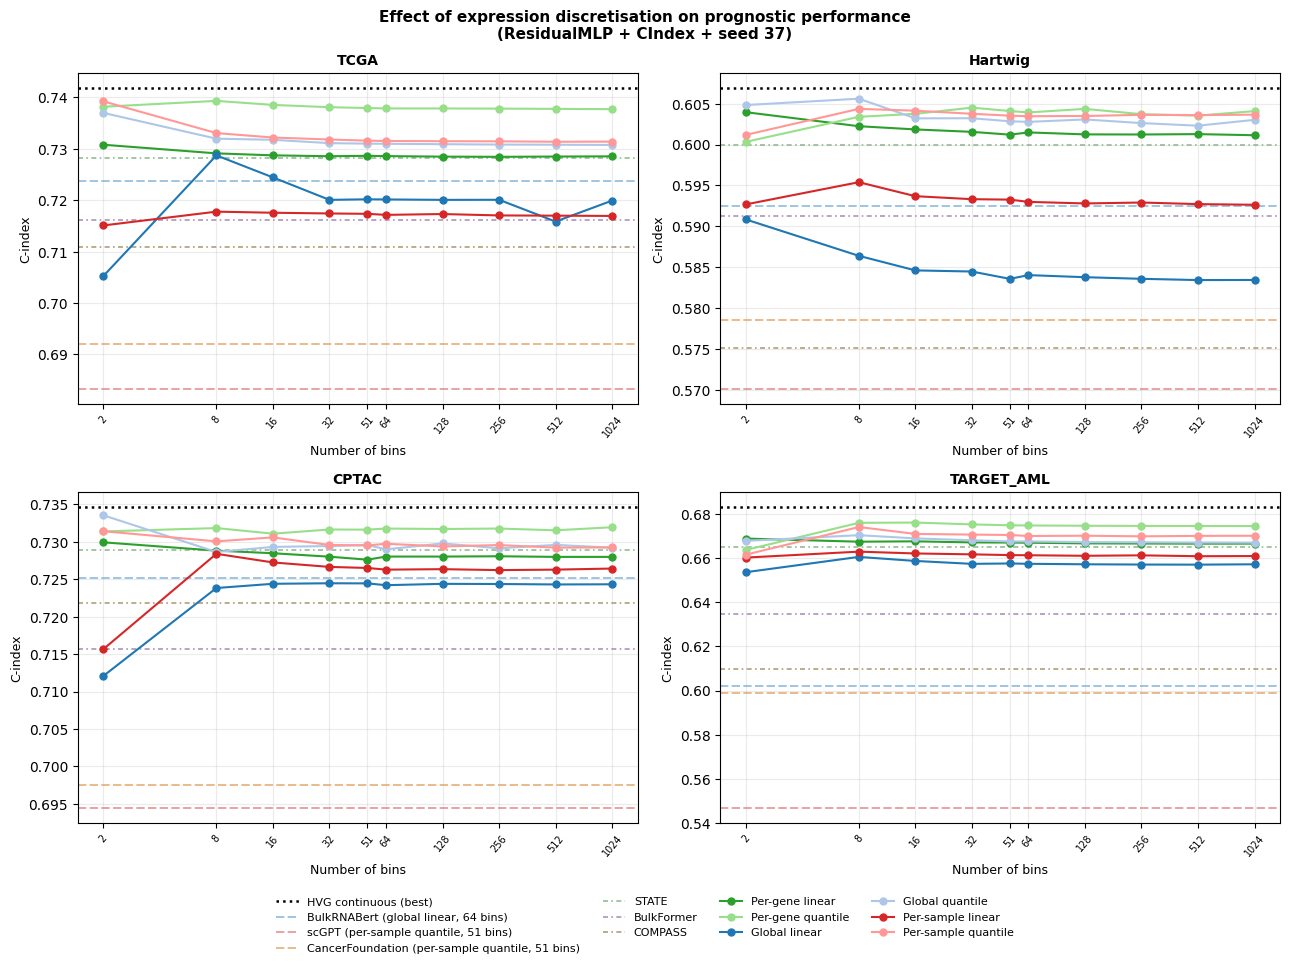

In [ ]:
import matplotlib.ticker as mticker

# Muted FM palette — distinct from the strategy line colors
FM_STYLE = {
    "BulkRNABert":      dict(color="#7bafd4", ls=(0,(5,2)),   lw=1.2, label="BulkRNABert (global linear, 64 bins)"),
    "scGPT":            dict(color="#e08080", ls=(0,(5,2)),   lw=1.2, label="scGPT (per-sample quantile, 51 bins)"),
    "CancerFoundation": dict(color="#e0a060", ls=(0,(5,2)),   lw=1.2, label="CancerFoundation (per-sample quantile, 51 bins)"),
    "STATE":            dict(color="#80b080", ls=(0,(3,2,1,2)),lw=1.2, label="STATE"),
    "BulkFormer":       dict(color="#a080b0", ls=(0,(3,2,1,2)),lw=1.2, label="BulkFormer"),
    "COMPASS":          dict(color="#a09060", ls=(0,(3,2,1,2)),lw=1.2, label="COMPASS"),
}

# Load FM performance per dataset from agg_filtered CSVs
fm_perf = {}
for ds in DATASETS:
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{ds}_survival_PFS_agg_filtered.csv")
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    fm_perf[ds] = {
        fm: float(df[df["RNA_key"] == fm]["overall_mean"].max())
        for fm in FM_STYLE
        if not df[df["RNA_key"] == fm].empty
    }

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=False)
axes_flat = axes.flatten()

for ax, ds in zip(axes_flat, DATASETS):
    baseline_mean = hvg_best.loc[ds, "overall_mean"]

    # Continuous HVG baseline — just a line, no band
    ax.axhline(baseline_mean, color="black", ls=":", lw=1.8, zorder=4,
               label="HVG continuous (best)")

    # FM reference horizontals (drawn behind strategy lines)
    for fm, style in FM_STYLE.items():
        if fm in fm_perf.get(ds, {}):
            ax.axhline(fm_perf[ds][fm],
                       color=style["color"], ls=style["ls"], lw=style["lw"],
                       alpha=0.85, zorder=2, label=style["label"])

    # Binning strategy convergence curves
    sub = binned_agg[binned_agg["dataset"] == ds]
    for strategy, style in STRATEGY_STYLE.items():
        rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
        ys   = [rows.loc[nb, "mean"] if nb in rows.index else np.nan for nb in N_BINS_ORDER]
        errs = [rows.loc[nb, "std"]  if nb in rows.index else np.nan for nb in N_BINS_ORDER]
        ax.errorbar(N_BINS_ORDER, ys,
                    color=style["color"], marker=style["marker"],
                    ls=style["ls"], lw=1.5, ms=5, capsize=3, zorder=3,
                    label=style["label"])

    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_xticks(N_BINS_ORDER)
    ax.tick_params(axis="x", rotation=50, labelsize=7)
    ax.set_xlabel("Number of bins", fontsize=9)
    ax.set_ylabel("C-index", fontsize=9)
    ax.set_title(ds, fontsize=10, fontweight="bold")
    ax.grid(True, alpha=0.25)

# Shared legend — FMs first, then strategies, then baseline
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.08), fontsize=8, frameon=False)

fig.suptitle(
    "Effect of expression discretisation on prognostic performance\n"
    f"(ResidualMLP + CIndex + seed {BINNED_SEED})",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "binned_HVG_ablation.png", bbox_inches="tight", dpi=150)
plt.show()

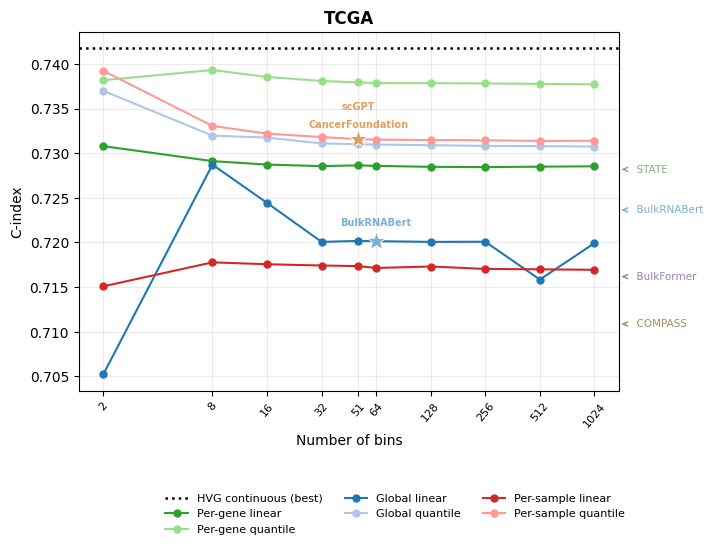

In [ ]:
import matplotlib.ticker as mticker

# (strategy, n_bins, label_y_offset_points)
FM_POINTS = {
    "scGPT":            ("per_sample_quantile", 51, (0, 20)),
    "CancerFoundation": ("per_sample_quantile", 51, (0,  7)),
    "BulkRNABert":      ("global_linear",       64, (0, 10)),
}

fig, ax = plt.subplots(1, 1, figsize=(8, 5.5))

ds = "TCGA"
baseline_mean = hvg_best.loc[ds, "overall_mean"]

ax.axhline(baseline_mean, color="black", ls=":", lw=1.8, zorder=4,
           label="HVG continuous (best)")

sub = binned_agg[binned_agg["dataset"] == ds]
for strategy, style in STRATEGY_STYLE.items():
    rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
    ys   = [rows.loc[nb, "mean"] if nb in rows.index else np.nan for nb in N_BINS_ORDER]
    ax.plot(N_BINS_ORDER, ys,
            color=style["color"], marker=style["marker"],
            ls=style["ls"], lw=1.5, ms=5, zorder=3,
            label=style["label"])

# ── Stars at FM operating points on the ablation curves ───────────────────
for fm, (strategy, n_bins, offset) in FM_POINTS.items():
    rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
    if n_bins not in rows.index:
        continue
    y  = rows.loc[n_bins, "mean"]
    fc = FM_STYLE[fm]["color"] if fm != "scGPT" else FM_STYLE["CancerFoundation"]["color"]  # use same color/style for these two since they overlap
    ax.plot(n_bins, y, marker="*", ms=14, color=fc,
            markeredgecolor="white", markeredgewidth=0.6,
            zorder=5, clip_on=False)
    ax.annotate(
        fm, xy=(n_bins, y), xytext=offset,
        textcoords="offset points",
        fontsize=7, color=fc, ha="center", va="bottom",
        fontweight="bold",
    )
# ──────────────────────────────────────────────────────────────────────────

ax.set_xscale("log", base=2)
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
ax.set_xticks(N_BINS_ORDER)
ax.tick_params(axis="x", rotation=50, labelsize=8)
ax.set_xlabel("Number of bins", fontsize=10)
ax.set_ylabel("C-index", fontsize=10)
ax.set_title("TCGA", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.25)

# ── FM arrows on the right pointing to actual FM performance ──────────────
y_lim = ax.get_ylim()
visible_fms = sorted(
    [(fm, val) for fm, val in fm_perf.get(ds, {}).items()
     if fm in FM_STYLE and y_lim[0] <= val <= y_lim[1]],
    key=lambda x: x[1]
)

min_gap = (y_lim[1] - y_lim[0]) * 0.04
label_y = []
for fm, val in visible_fms:
    pos = val
    for prev in label_y:
        if abs(pos - prev) < min_gap:
            pos = prev + min_gap
    label_y.append(pos)

for (fm, val), pos in zip(visible_fms, label_y):
    style = FM_STYLE[fm] if fm != "scGPT" else FM_STYLE["CancerFoundation"]  # use same color/style for these two since they overlap
    ax.annotate(
        f"  {fm}",
        xy=(1.0, val),
        xycoords=("axes fraction", "data"),
        xytext=(1.02, pos),
        textcoords=("axes fraction", "data"),
        arrowprops=dict(arrowstyle="->", color=style["color"],
                        lw=1.1, connectionstyle="arc3,rad=0.0"),
        fontsize=7.5, va="center", ha="left",
        color=style["color"], clip_on=False,
    )
# ──────────────────────────────────────────────────────────────────────────

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0), fontsize=8, frameon=False)
'''
fig.suptitle(
    "Effect of expression discretisation on prognostic performance — TCGA\n"
    f"(ResidualMLP + CIndex + seed {BINNED_SEED})",
    fontsize=10, fontweight="bold"
)
'''
plt.tight_layout()
plt.subplots_adjust(right=0.78, bottom=0.28)
plt.savefig(FIGURE_DIR / "binned_HVG_ablation_TCGA.png", bbox_inches="tight", dpi=150)
plt.show()

In [ ]:
rows = []
for fm, (strategy, n_bins, _) in FM_POINTS.items():
    # Performance of binned HVG at the FM's operating point
    sub_fm = binned_agg[
        (binned_agg["dataset"] == ds) &
        (binned_agg["bin_strategy"] == strategy) &
        (binned_agg["n_bins"] == n_bins)
    ]
    binned_mean = sub_fm["mean"].values[0] if len(sub_fm) else float("nan")
    binned_std  = sub_fm["std"].values[0]  if len(sub_fm) else float("nan")

    # Actual FM performance
    fm_mean = fm_perf.get(ds, {}).get(fm, float("nan"))

    rows.append({
        "Model":            fm,
        "Bin strategy":     strategy,
        "n_bins":           n_bins,
        "HVG w/ binning":   f"{binned_mean:.3f} ± {binned_std:.3f}",
        "Actual FM":        f"{fm_mean:.3f}",
        "Gap (FM − binned)": f"{fm_mean - binned_mean:+.3f}",
    })

df_compare = pd.DataFrame(rows).set_index("Model")
display(df_compare)

,Bin strategy,n_bins,HVG w/ binning,Actual FM,Gap (FM − binned)
Model,,,,,
scGPT,per_sample_quantile,51,0.732 ± 0.012,0.683,-0.048
CancerFoundation,per_sample_quantile,51,0.732 ± 0.012,0.692,-0.040
BulkRNABert,global_linear,64,0.720 ± 0.007,0.724,+0.003


### Clinical Concat

In [ ]:
CLINICAL_CONCAT_BASE = REPO_DIR / "clinical_concat_model_outputs"
FM_ORDER = ["BulkFormer", "BulkRNABert", "COMPASS", "scGPT", "STATE", "CancerFoundation", "RNA_seq"]

# ── Clinical concat results ───────────────────────────────────────────────────
clin_concat_dfs = []
for dataset in DATASETS:
    csv = CLINICAL_CONCAT_BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if csv.exists():
        clin_concat_dfs.append(pd.read_csv(csv))
    else:
        print(f"Missing: {csv}")

clin_concat_df = pd.concat(clin_concat_dfs, ignore_index=True)
clin_concat_df = clin_concat_df[clin_concat_df["fm_key"].isin(FM_ORDER)]
print(f"Clinical concat: {len(clin_concat_df)} runs across {clin_concat_df['dataset'].nunique()} datasets")

# ── FM-only results (from main benchmarking) ──────────────────────────────────
fm_dfs = []
for dataset in DATASETS:
    csv = BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if not csv.exists():
        continue
    df = pd.read_csv(csv)
    df = df[df["RNA_key"].isin(FM_ORDER)].copy()
    df = df.rename(columns={"RNA_key": "fm_key", "overall": "fm_only_cindex"})
    fm_dfs.append(df[["dataset", "arch", "loss", "fm_key", "seed", "split", "fm_only_cindex"]])

fm_only_df = pd.concat(fm_dfs, ignore_index=True)
print(f"FM-only: {len(fm_only_df)} runs")

# ── Clinical-only results (from train_clinical_baseline.py) ───────────────────
clin_only_df = pd.read_csv(REPO_DIR / "benchmarking_results" / "clinical" / "cindex_results.csv")
clin_only = clin_only_df.set_index("Dataset")["cindex_mean"].to_dict()
print("Clinical-only C-index:", clin_only)


Clinical concat: 1120 runs across 4 datasets
FM-only: 2400 runs
Clinical-only C-index: {'TCGA': 0.7686037334429026, 'Hartwig': 0.5596368352037251, 'CPTAC': 0.7436093674732699, 'TARGET_AML': 0.5334049096528544}


In [ ]:
# Merge clinical concat with FM-only (paired per run)
merged = (
    clin_concat_df
    .rename(columns={"overall": "clin_concat_cindex"})
    .merge(fm_only_df, on=["dataset", "arch", "loss", "fm_key", "seed", "split"], how="inner")
)
merged["delta_vs_fm"] = merged["clin_concat_cindex"] - merged["fm_only_cindex"]

# Aggregate across seeds & splits
agg = (
    merged.groupby(["dataset", "arch", "loss", "fm_key"])
    .agg(
        clin_concat_mean  = ("clin_concat_cindex", "mean"),
        clin_concat_std   = ("clin_concat_cindex", "std"),
        fm_only_mean      = ("fm_only_cindex",     "mean"),
        delta_vs_fm_mean  = ("delta_vs_fm",        "mean"),
        delta_vs_fm_std   = ("delta_vs_fm",        "std"),
        n_runs            = ("clin_concat_cindex",  "count"),
    )
    .reset_index()
)
agg["clin_only_mean"] = agg["dataset"].map(clin_only)

# Pick best (arch, loss) per (dataset, fm_key) by clinical concat mean C-index
best_idx = agg.groupby(["dataset", "fm_key"])["clin_concat_mean"].idxmax()
best = agg.loc[best_idx].copy().reset_index(drop=True)
best["fm_key"] = pd.Categorical(best["fm_key"], categories=FM_ORDER, ordered=True)
best = best.sort_values(["dataset", "fm_key"]).reset_index(drop=True)

display(best[["dataset", "fm_key", "arch", "loss",
              "clin_only_mean", "fm_only_mean", "clin_concat_mean",
              "delta_vs_fm_mean", "delta_vs_fm_std", "n_runs"]].round(4))

KeyError: '[nan] not in index'

NameError: name 'best' is not defined

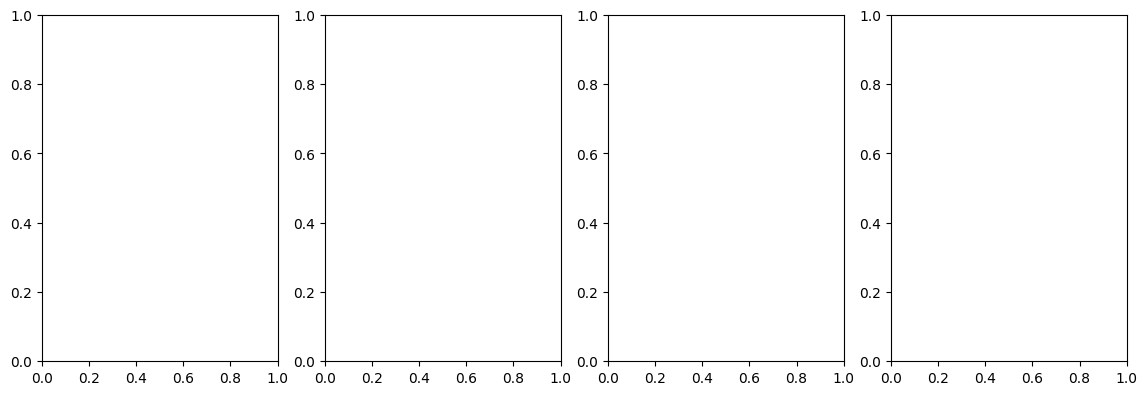

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 4.5), sharey=False)

bar_w = 0.22
x = np.arange(len(FM_ORDER))

for ax, dataset in zip(axes, DATASETS):
    sub = best[best["dataset"] == dataset].set_index("fm_key").reindex(FM_ORDER)

    fm_vals   = sub["fm_only_mean"].values
    cc_vals   = sub["clin_concat_mean"].values
    cc_err    = sub["clin_concat_std"].fillna(0).values
    clin_line = clin_only.get(dataset, np.nan)

    ax.bar(x - bar_w/2, fm_vals, bar_w, label="FM only",           color="#4C72B0", alpha=0.85)
    ax.bar(x + bar_w/2, cc_vals, bar_w, label="FM + clinical",     color="#DD8452", alpha=0.85,
           yerr=cc_err, capsize=3, error_kw={"linewidth": 1})
    ax.axhline(clin_line, color="#55A868", linestyle="--", linewidth=1.5, label="Clinical only")

    ax.set_title(dataset_labels.get(dataset, dataset), fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(FM_ORDER, rotation=45, ha="right", fontsize=7.5)
    ax.set_ylabel("Mean C-index" if ax is axes[0] else "")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_ylim(bottom=max(0, min(np.nanmin(fm_vals), clin_line) - 0.05))
    if ax is axes[0]:
        ax.legend(fontsize=8, frameon=False)

plt.suptitle("FM only  vs  FM + clinical features  vs  Clinical only", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clinical_concat_bar_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

KeyError: 'delta_vs_fm_mean'

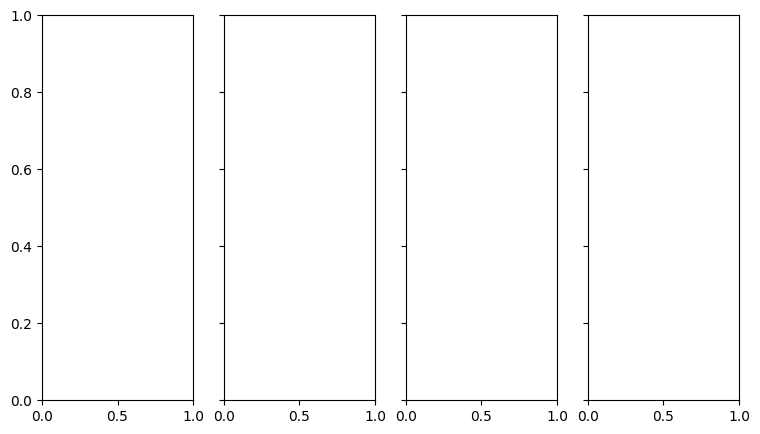

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(9, 5), sharey=True)

vmax = max(best["delta_vs_fm_mean"].abs().max(), 0.01)

for ax, dataset in zip(axes, DATASETS):
    sub = best[best["dataset"] == dataset].set_index("fm_key").reindex(FM_ORDER)
    vals = sub["delta_vs_fm_mean"].values.reshape(-1, 1)

    im = ax.imshow(vals, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")

    for i, fm in enumerate(FM_ORDER):
        if fm in sub.index and not pd.isna(sub.loc[fm, "delta_vs_fm_mean"]):
            v = sub.loc[fm, "delta_vs_fm_mean"]
            ax.text(0, i, f"{v:+.3f}", ha="center", va="center", fontsize=9,
                    fontweight="bold" if abs(v) > 0.005 else "normal", color="black")

    ax.set_title(dataset_labels.get(dataset, dataset), fontsize=11)
    ax.set_xticks([])
    ax.set_yticks(range(len(FM_ORDER)))
    if ax is axes[0]:
        ax.set_yticklabels(FM_ORDER, fontsize=9)

plt.colorbar(im, ax=axes[-1], label="ΔC-index", shrink=0.8)
fig.suptitle("Incremental value of clinical features over FM alone\n(FM + clinical) − (FM only)", fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clinical_concat_delta_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
summary = (
    best.groupby("dataset")
    .apply(lambda g: pd.Series({
        "clinical_only":          clin_only.get(g.name, np.nan),
        "best_fm_only":           g["fm_only_mean"].max(),
        "best_fm_clinical":       g["clin_concat_mean"].max(),
        "mean_delta_vs_fm":       g["delta_vs_fm_mean"].mean(),
        "n_fm_keys_improved":     (g["delta_vs_fm_mean"] > 0).sum(),
        "best_fm_key":            g.loc[g["clin_concat_mean"].idxmax(), "fm_key"],
    }))
    .reset_index()
)
summary["delta_vs_clinical_only"] = summary["best_fm_clinical"] - summary["clinical_only"]
display(summary.round(4))


NameError: name 'best' is not defined

### Analyze clinical features

In [ ]:
import pandas as pd

# Load the CSV
path = "/data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/clinical/feature_importance.csv"
df = pd.read_csv(path)

# For each dataset, print top 10 features by abs_mean_coef
for dataset, sub_df in df.groupby("dataset"):
    print(f"\n=== {dataset} ===")
    
    top10 = (
        sub_df
        .sort_values("abs_mean_coef", ascending=False)
        .head(10)
    )
    
    print(top10[["feature", "abs_mean_coef", "mean_coef", "std_coef", "feature_group"]])


=== CPTAC ===
                                               feature  abs_mean_coef  \
317               diagnoses.ajcc_pathologic_t__missing       1.105628   
318                       diagnoses.morphology__8290/0       1.047151   
319            diagnoses.primary_diagnosis__Oncocytoma       1.047151   
320                          diagnoses.tumor_grade__G4       0.994739   
321                          diagnoses.tumor_grade__GX       0.945004   
322           diagnoses.ajcc_pathologic_stage__missing       0.825980   
323   diagnoses.tissue_or_organ_of_origin__Tongue, NOS       0.717831   
324                diagnoses.residual_disease__MISSING       0.640326   
325   diagnoses.tissue_or_organ_of_origin__Kidney, NOS       0.615953   
326  diagnoses.primary_diagnosis__Infiltrating duct...       0.524542   

     mean_coef  std_coef                        feature_group  
317   1.105628  0.301608          diagnoses.ajcc_pathologic_t  
318  -1.047151  0.525799                 diagnoses.mo

In [ ]:
top10.head()

,dataset,feature,mean_coef,std_coef,abs_mean_coef,feature_group
0,TCGA,diagnoses.tumor_grade__Low Grade,-2.053520,0.065925,2.053520,diagnoses.tumor_grade
1,TCGA,project.project_id__TCGA-CHOL,2.048739,0.999176,2.048739,project.project_id
2,TCGA,diagnoses.tissue_or_organ_of_origin__Transvers...,-1.942548,0.628625,1.942548,diagnoses.tissue_or_organ_of_origin
3,TCGA,diagnoses.primary_diagnosis__Diffuse large B-c...,1.734150,0.238382,1.734150,diagnoses.primary_diagnosis
4,TCGA,"diagnoses.tissue_or_organ_of_origin__Testis, NOS",-1.663903,0.528141,1.663903,diagnoses.tissue_or_organ_of_origin


### Mean Pooling Experiment

In [ ]:
# ── HVG-pooling comparison: BulkRNABert & BulkFormer original vs HVG-pooled ──

HVG_CSV  = REPO_DIR / "model_outputs/HVG_pooling/TCGA/survival/PFS/all_metrics.csv"
ORIG_AGG = OUT_DIR / "transcriptomic/TCGA_survival_PFS_agg_filtered.csv"

# --- Original: pull BulkRNABert & BulkFormer from the existing aggregated CSV ---
orig = pd.read_csv(ORIG_AGG)
orig["overall_mean"] = pd.to_numeric(orig["overall_mean"], errors="coerce")
orig["overall_std"]  = pd.to_numeric(orig["overall_std"],  errors="coerce")

orig_fm = (
    orig[orig["RNA_key"].isin(["BulkRNABert", "BulkFormer"])]
    .sort_values("overall_mean", ascending=False)
    .groupby("RNA_key", as_index=False)
    .first()          # best arch×loss combo
    [["RNA_key", "arch", "loss", "overall_mean", "overall_std"]]
)

# --- New: aggregate HVG-pooling raw CSV (mean ± std over seeds & splits) ---
hvg_raw = pd.read_csv(HVG_CSV)
hvg_raw["overall"] = pd.to_numeric(hvg_raw["overall"], errors="coerce")

hvg_agg = (
    hvg_raw.dropna(subset=["overall"])
    .groupby(["RNA_key", "arch", "loss"])["overall"]
    .agg(overall_mean="mean", overall_std="std")
    .reset_index()
)

hvg_best = (
    hvg_agg.sort_values("overall_mean", ascending=False)
    .groupby("RNA_key", as_index=False)
    .first()
)

# --- Combine ---
compare = pd.concat([orig_fm, hvg_best], ignore_index=True)
compare["model_family"] = compare["RNA_key"].apply(
    lambda k: "BulkRNABert" if "BulkRNABert" in k else "BulkFormer"
)
compare["label"] = compare["RNA_key"].str.replace("BulkRNABert_HVG_", "BRB HVG-")\
                                      .str.replace("BulkFormer_HVG_",  "BF HVG-")\
                                      .str.replace("BulkRNABert", "BRB (original)")\
                                      .str.replace("BulkFormer",  "BF (original)")

# Fixed display order
key_order = [
    "BulkRNABert", "BulkRNABert_HVG_1250", "BulkRNABert_HVG_5000", "BulkRNABert_HVG_10000",
    "BulkFormer",  "BulkFormer_HVG_1250",  "BulkFormer_HVG_2000",  "BulkFormer_HVG_5000", "BulkFormer_HVG_10000",
]
compare = compare.set_index("RNA_key").reindex(key_order).reset_index()
print(compare[["label", "arch", "loss", "overall_mean", "overall_std"]].to_string(index=False))

         label        arch   loss  overall_mean  overall_std
BRB (original) ResidualMLP    Cox      0.723639     0.009901
  BRB HVG-1250 ResidualMLP CIndex      0.723992     0.009920
  BRB HVG-5000 ResidualMLP CIndex      0.723074     0.010358
 BRB HVG-10000 ResidualMLP    Cox      0.722952     0.010529
 BF (original) ResidualMLP CIndex      0.716180     0.014934
   BF HVG-1250 ResidualMLP    Cox      0.713967     0.013370
   BF HVG-2000 ResidualMLP    Cox      0.713240     0.014213
   BF HVG-5000 ResidualMLP    Cox      0.712415     0.012497
  BF HVG-10000 ResidualMLP    Cox      0.712001     0.014087


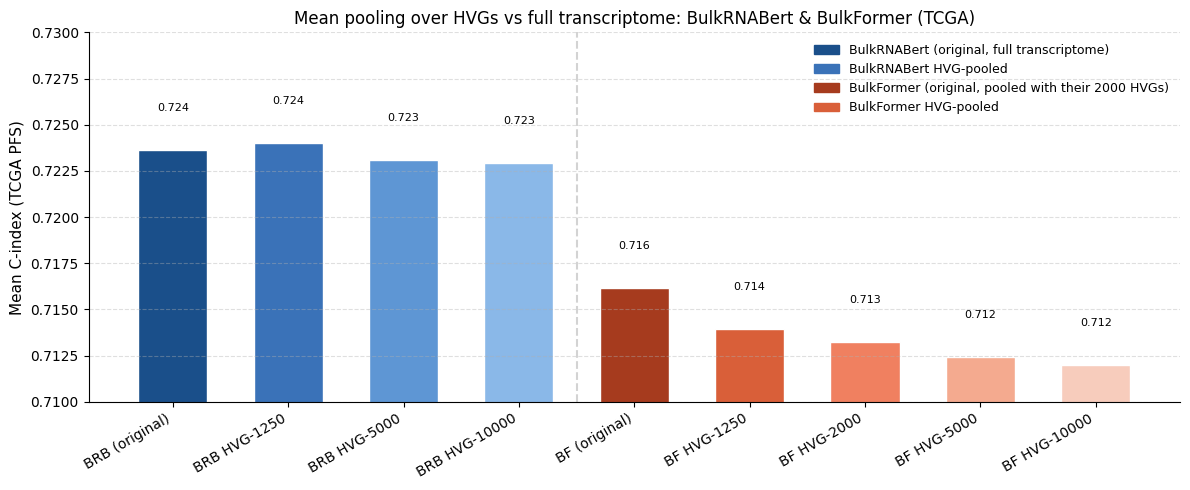

In [ ]:
# Color palettes: dark original, progressively lighter HVG variants
brb_colors = ["#1a4f8a", "#3a72b8", "#5e96d4", "#8ab8e8"]   # BulkRNABert family (dark → light)
bf_colors  = ["#a63b1e", "#d95f39", "#f08060", "#f4aa8f", "#f7ccbc"]  # BulkFormer family

colors = brb_colors[:4] + bf_colors[:5]

x      = np.arange(len(compare))
means  = compare["overall_mean"].values
stds   = compare["overall_std"].fillna(0).values
labels = compare["label"].values

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(x, means, color=colors, width=0.6, edgecolor="white", capsize=4, error_kw=dict(elinewidth=1.2, ecolor="grey"))

# Value labels on top of bars
for bar, m in zip(bars, means):
    if pd.notna(m):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
                f"{m:.3f}", ha="center", va="bottom", fontsize=8)

# Separator between BulkRNABert and BulkFormer groups
ax.axvline(3.5, color="lightgrey", linewidth=1.5, linestyle="--")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=10)
ax.set_ylabel("Mean C-index (TCGA PFS)", fontsize=11)
ax.set_title("Mean pooling over HVGs vs full transcriptome: BulkRNABert & BulkFormer (TCGA)", fontsize=12)
ax.set_ylim(0.71, 0.73)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend_elements = [
    mpatches.Patch(color=brb_colors[0], label="BulkRNABert (original, full transcriptome)"),
    mpatches.Patch(color=brb_colors[1], label="BulkRNABert HVG-pooled"),
    mpatches.Patch(color=bf_colors[0],  label="BulkFormer (original, pooled with their 2000 HVGs)"),
    mpatches.Patch(color=bf_colors[1],  label="BulkFormer HVG-pooled"),
]
ax.legend(handles=legend_elements, fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "HVG_pooling_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


### Foundation Model Finetuning

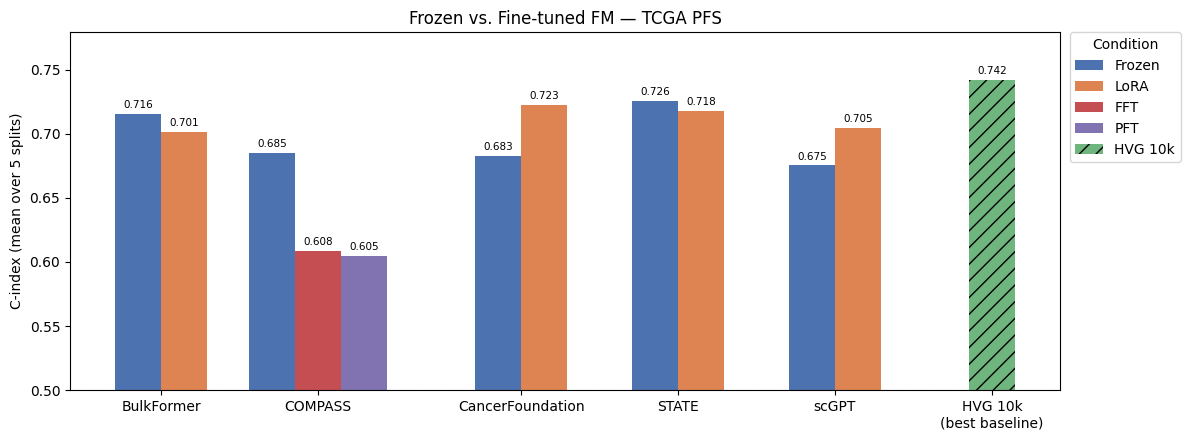

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Load data ─────────────────────────────────────────────────────────────────
ft   = pd.read_csv("../model_outputs_finetune/TCGA/survival/PFS/finetune_metrics.csv")
orig = pd.read_csv("../model_outputs/TCGA/survival/PFS/all_metrics.csv")

# ── Filter ────────────────────────────────────────────────────────────────────
ft_filt   = ft[(ft["loss"] == "CIndex") & (ft["seed"] == 37)]
orig_filt = orig[(orig["arch"] == "Linear") & (orig["loss"] == "CIndex") & (orig["seed"] == 37)]

# ── Averages ──────────────────────────────────────────────────────────────────
orig_mean        = orig_filt.groupby("RNA_key")["overall"].mean()
ft_mean_by_mode  = ft_filt.groupby(["fm_name", "ft_mode"])["overall"].mean()

hvg_mean = (
    orig[(orig["RNA_key"] == "RNA_seq") & (orig["nHVGs"] == 10000) & (orig["loss"] == "CIndex")]
    .groupby(["arch", "seed"])["overall"].mean().max()
)

# ── Build groups: (group_label, [(bar_label, value, color), ...]) ─────────────
COLORS = {
    "Frozen": "#4C72B0",
    "LoRA":   "#DD8452",
    "FFT":    "#C44E52",
    "PFT":    "#8172B2",
    "HVG":    "#55A868",
}

fms = sorted(ft_filt["fm_name"].unique().tolist())
groups = []
for fm in fms:
    bars = [("Frozen", orig_mean.get(fm, np.nan), COLORS["Frozen"])]
    if fm == "COMPASS":
        for mode in ["FFT", "PFT"]:
            val = ft_mean_by_mode.get((fm, mode), np.nan)
            bars.append((mode, val, COLORS[mode]))
    else:
        val = ft_mean_by_mode.get((fm, "LoRA"), np.nan)
        bars.append(("LoRA", val, COLORS["LoRA"]))
    groups.append((fm, bars))

groups.append(("HVG 10k\n(best baseline)", [("HVG 10k", hvg_mean, COLORS["HVG"])]))

# ── Compute x positions ───────────────────────────────────────────────────────
w         = 0.25   # individual bar width
group_gap = 0.35   # space between groups

flat_bars    = []   # (x_center, val, color, bar_label)
x_centers    = []
cur_x        = 0.0

for g_label, bars in groups:
    n       = len(bars)
    offsets = (np.arange(n) - (n - 1) / 2) * w
    g_cx    = cur_x
    for (b_label, val, color), offset in zip(bars, offsets):
        flat_bars.append((g_cx + offset, val, color, b_label))
    x_centers.append(g_cx)
    cur_x += n * w + group_gap

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(max(6, len(groups) * 2), 4.5))

seen_labels = set()
for x, val, color, b_label in flat_bars:
    lbl = b_label if b_label not in seen_labels else "_nolegend_"
    seen_labels.add(b_label)
    ax.bar(x, val if not np.isnan(val) else 0, w, color=color, label=lbl,
           alpha=0.85 if b_label == "HVG 10k" else 1.0,
           hatch="//" if b_label == "HVG 10k" else "")
    if not np.isnan(val):
        ax.text(x, val + 0.003, f"{val:.3f}", ha="center", va="bottom", fontsize=7.5)

ax.set_ylabel("C-index (mean over 5 splits)")
ax.set_title("Frozen vs. Fine-tuned FM — TCGA PFS")
ax.set_xticks(x_centers)
ax.set_xticklabels([g[0] for g in groups])
ax.set_ylim(0.5, None)
ax.axhline(0.5, color="grey", lw=0.8, ls="--", alpha=0.6)
ax.legend(title="Condition", bbox_to_anchor=(1.01, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "finetune_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


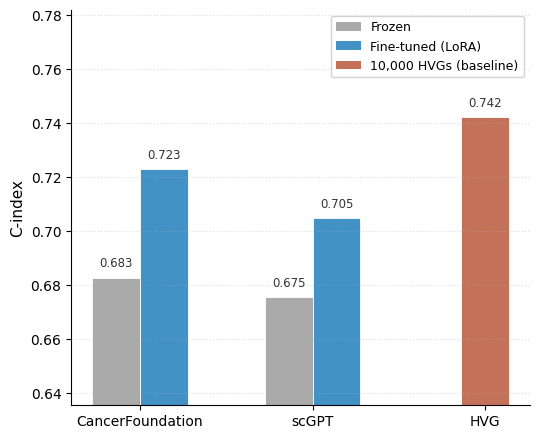

In [ ]:
from matplotlib.lines import Line2D

# ── load ──────────────────────────────────────────────────────────────────────
ft   = pd.read_csv("../model_outputs_finetune/TCGA/survival/PFS/finetune_metrics.csv")
orig = pd.read_csv("../model_outputs/TCGA/survival/PFS/all_metrics.csv")

SHOW_FMS = ['CancerFoundation', 'scGPT']

# ── aggregate ─────────────────────────────────────────────────────────────────
ft_filt   = ft[(ft["loss"] == "CIndex") & (ft["seed"] == 37) & ft["fm_name"].isin(SHOW_FMS)]
orig_filt = orig[(orig["arch"] == "Linear") & (orig["loss"] == "CIndex") & (orig["seed"] == 37)]

orig_mean       = orig_filt.groupby("RNA_key")["overall"].mean()
ft_mean_by_mode = ft_filt.groupby(["fm_name", "ft_mode"])["overall"].mean()
hvg_mean        = (
    orig[(orig["RNA_key"] == "RNA_seq") & (orig["nHVGs"] == 10000) & (orig["loss"] == "CIndex")]
    .groupby(["arch", "seed"])["overall"].mean().max()
)

# ── groups & colors ───────────────────────────────────────────────────────────
COLORS = {"Frozen": "#AAAAAA", "LoRA": "#4292C6", "HVG": "#C4715A"}

groups = []
for fm in SHOW_FMS:
    groups.append((fm, [
        ("Frozen", orig_mean.get(fm, np.nan),                    COLORS["Frozen"]),
        ("LoRA",   ft_mean_by_mode.get((fm, "LoRA"), np.nan),    COLORS["LoRA"]),
    ]))
groups.append(("HVG", [("HVG", hvg_mean, COLORS["HVG"])]))

# ── x positions ───────────────────────────────────────────────────────────────
w, group_gap = 0.28, 0.45
flat_bars, x_centers, cur_x = [], [], 0.0

for g_label, bars in groups:
    n       = len(bars)
    offsets = (np.arange(n) - (n - 1) / 2) * w
    for (b_label, val, color), offset in zip(bars, offsets):
        flat_bars.append((cur_x + offset, val, color, b_label))
    x_centers.append(cur_x)
    cur_x += n * w + group_gap

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, 4.5))

seen = set()
for x, val, color, b_label in flat_bars:
    lbl = b_label if b_label not in seen else "_nolegend_"
    seen.add(b_label)
    ax.bar(x, val if not np.isnan(val) else 0, w,
           color=color, label=lbl, edgecolor='white', linewidth=0.6)
    if not np.isnan(val):
        ax.text(x, val + 0.003, f"{val:.3f}",
                ha='center', va='bottom', fontsize=8.5, color='#333333')

all_vals = [v for _, v, _, _ in flat_bars if not np.isnan(v)]
ax.set_ylim(min(all_vals) - 0.04, max(all_vals) + 0.04)
ax.set_ylabel("C-index", fontsize=11)
#ax.set_title("Frozen vs. fine-tuned — TCGA PFS", fontsize=12, fontweight='bold')
ax.set_xticks(x_centers)
ax.set_xticklabels([g[0] for g in groups], fontsize=10)
ax.grid(axis='y', ls=':', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

legend_handles = [
    mpatches.Patch(facecolor=COLORS["Frozen"], label="Frozen"),
    mpatches.Patch(facecolor=COLORS["LoRA"],   label="Fine-tuned (LoRA)"),
    mpatches.Patch(facecolor=COLORS["HVG"],    label="10,000 HVGs (baseline)"),
]
ax.legend(handles=legend_handles, fontsize=9, framealpha=0.85, loc='upper right')

plt.tight_layout()
plt.savefig(FIGURE_DIR / "finetune_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
